# Web Scraping and Exploratory Data Analysis of Company Reviews and Salaries from AmbitionBox

# Problem Statement:
AmbitionBox is a platform where employees share company reviews, ratings, salaries, work culture experiences, and job-related information. 
This project collects real-world company data through web scraping and performs exploratory data analysis to identify patterns in employee satisfaction and salary trends.

#### Observation: 
- AmbitionBox contains employee-generated company information.
- The dataset can help understand factors affecting employee satisfaction.

In [3]:
# Import Required Libraries
import pandas as pd
import numpy as np
import time
import requests

from bs4 import BeautifulSoup
import re

In [4]:
url = "https://www.ambitionbox.com/list-of-companies?campaign=desktop_nav"

headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36"
    }

response = requests.get(url, headers = headers)
response.status_code


200

In [5]:
html_code = response.text

In [6]:
soup = BeautifulSoup(html_code)

In [7]:
soup.text[:1000]

'\n\n\n\n\n\n\n\n\n\nTop Companies in India | AmbitionBox\n\n\n\n   \n\t\t\t\t\t\tAmbitionBox\n\t\t\t\t\t       \n\tSearch\n\t    About Company  \n\t\t\tReviews\n\t\t\n\t\t\tSalaries\n\t\t\n\t\t\tInterview Questions\n\t\t\n\t\t\tAbout Company\n\t\t\n\t\t\tBenefits\n\t\t\n\t\t\tJobs\n\t\t\n\t\t\tOffice Photos\n\t\t\n\t\t\tCommunity\n\t\t + Contribute\n\t\t\t\t\t\t\t   0        \n\t\t\t\t\t\t\tLogin\n\t\t\t\t\t\t     Home  Companies  Reviews  Salaries  Interview Questions  Jobs  Tools   Compare Companies   Salary Calculator   Are you paid fairly?   Evaluate Offer Letter   Gratuity Calculator   HRA Calculator   Salary Hike Calculator     Awards   ABECA 2027  \n\t\t\tRate Now\n\t\t ABECA 2026   ABECA 2025    Communities   My Company My Role       FOR EMPLOYERS   Create Company Profile   Edit Company Profile   Respond to reviews   Invite employees to review   Employer Offerings   Employer Brochure     More   About Us   Our Team   Email Us     \n\t\t\t\t\t\tPrivacy\n\t\t\t\t\t\n\t\t\t\t\t\tG

'<!doctype html>\n<html data-n-head-ssr lang="en" data-n-head="%7B%22lang%22:%7B%22ssr%22:%22en%22%7D%7D">\n  <head >\n    <meta charset="UTF-8">\n    <meta name="viewport" content="width=device-width,initial-scale=1,minimum-scale=1">\n    <meta http-equiv="X-UA-Compatible" content="IE=edge"> \n    <link rel="manifest" href="/assets/next/manifest.json">\n    <style>@media only screen and (min-width:767px){.trp-img{width:400px!important;max-width:400px!important}}</style>\n    <script src="/static/js/env-runtime.js" defer></script>\n    <script>window.dataLayer=window.dataLayer||[],window.gtag=window.gtag||function(){window.dataLayer.push(arguments)},gtag("js",new Date),window.initialDate=(new Date).toISOString()</script>\n    <script>window.Prism=window.Prism||{},window.Prism.manual=!0</script>\n    <title>Top Companies in India | AmbitionBox</title><meta data-n-head="ssr" name="copyright" content="2026 AmbitionBox"><meta data-n-head="ssr" name="revisit-after" content="1 day"><meta dat
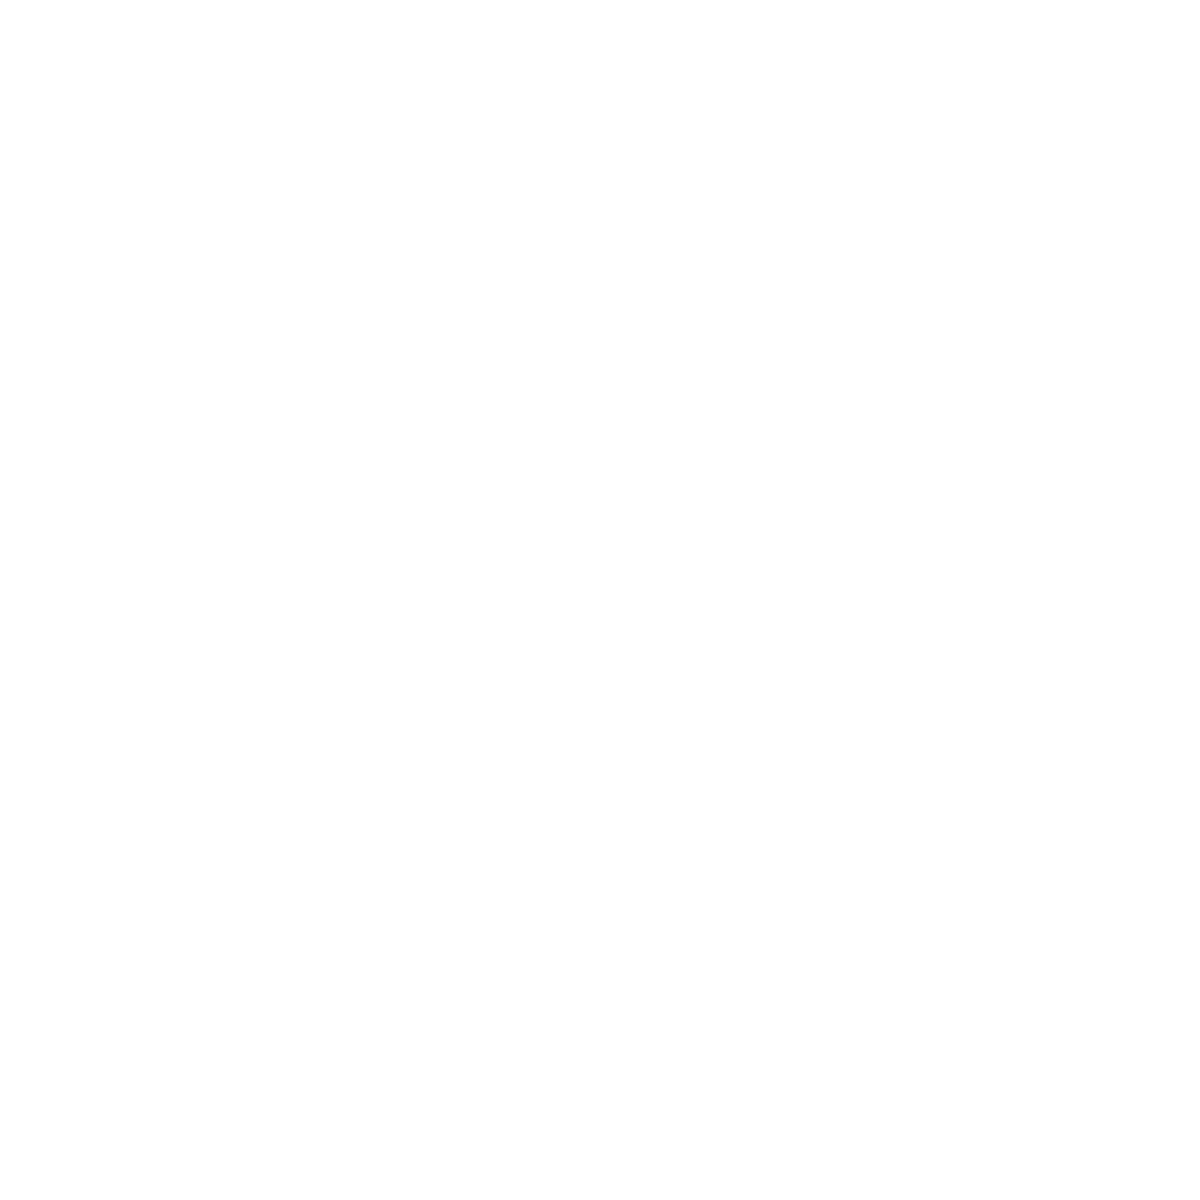

In [8]:
html_code

# Extract Single Company Data Using find()

In [10]:
# Company Name
company = soup.find("h2", attrs={"class":"companyCardWrapper__companyName"})
company.text.strip()

'TCS'

In [11]:
# Comapny rating
rating = soup.find("div", attrs={"class":"rating_text rating_text--md"})
rating.text.strip()

'3.3'

In [12]:
# Company Review
review = soup.find("span", attrs={"class":"companyCardWrapper__ActionCount"})
review.text.strip()

'1.2L'

In [13]:
# Company location
location = soup.find("span", attrs={"class":"companyCardWrapper__interLinking"})
location.text.strip()

'IT Services & Consulting | Bengaluru +448 other locations'

In [14]:
# salary
salary = soup.find("span", attrs={"class":"companyCardWrapper__ActionCount"})
salary.text.strip()

'1.2L'

In [15]:
# Company Industry
industry = soup.find("span",attrs={"class":"companyCardWrapper__interLinking"})
industry.text.strip()

'IT Services & Consulting | Bengaluru +448 other locations'

# Extract Multiple Company Data Using find all()

In [16]:
# Company names
companies = soup.find_all("h2",attrs={"class":"companyCardWrapper__companyName"})
len(companies)

20

In [17]:
# company ratings
ratings = soup.find_all("div",attrs={"class":"rating_text rating_text--md"})
len(ratings)

20

In [18]:
# Company Reviews
review = soup.find_all("span",attrs={"class":"companyCardWrapper__ActionCount"})
len(review)

120

In [19]:
# Company locations
locations = soup.find_all("span",attrs={"class":"companyCardWrapper__interLinking"})
len(locations)

20

In [20]:
# salaries
salaries = soup.find_all("span",attrs={"class":"companyCardWrapper__ActionCount"})
len(salaries)

120

In [21]:
# Company Industries
industries = soup.find_all("span",attrs={"class":"companyCardWrapper__interLinking"})
len(industries)

20

In [22]:
# Preview First Element in List
companies[0].text.strip()

'TCS'

In [23]:
# Print All Extracted Company Names
for m in companies:
    print(m.text.strip())

TCS
Accenture
Wipro
Cognizant
Capgemini
HDFC Bank
Infosys
HCLTech
ICICI Bank
Tech Mahindra
Genpact
TP
Axis Bank
Jio
Concentrix Corporation
Amazon
Reliance Retail
iEnergizer
LTIMindtree
HDB Financial Services


# Iterate over each page and scrap the data

In [24]:
url = "https://www.ambitionbox.com/list-of-companies?campaign=desktop_nav"

for i in range(1,51):
    print(f"https://www.ambitionbox.com/list-of-companies?page={i}")

https://www.ambitionbox.com/list-of-companies?page=1
https://www.ambitionbox.com/list-of-companies?page=2
https://www.ambitionbox.com/list-of-companies?page=3
https://www.ambitionbox.com/list-of-companies?page=4
https://www.ambitionbox.com/list-of-companies?page=5
https://www.ambitionbox.com/list-of-companies?page=6
https://www.ambitionbox.com/list-of-companies?page=7
https://www.ambitionbox.com/list-of-companies?page=8
https://www.ambitionbox.com/list-of-companies?page=9
https://www.ambitionbox.com/list-of-companies?page=10
https://www.ambitionbox.com/list-of-companies?page=11
https://www.ambitionbox.com/list-of-companies?page=12
https://www.ambitionbox.com/list-of-companies?page=13
https://www.ambitionbox.com/list-of-companies?page=14
https://www.ambitionbox.com/list-of-companies?page=15
https://www.ambitionbox.com/list-of-companies?page=16
https://www.ambitionbox.com/list-of-companies?page=17
https://www.ambitionbox.com/list-of-companies?page=18
https://www.ambitionbox.com/list-of-c

In [26]:
# Create lists for all features to store the values
name_data = []
rating_data = []
review_data = []
salary_data =[]
job_data = []
type_data = []
highly_rated_data=[]
industry_data = []

for i in range(1,51):
    web = f"https://www.ambitionbox.com/list-of-companies?page={i}"
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36"
    }
    response = requests.get(web, headers=headers)
    html_code = response.text
    soup = BeautifulSoup(html_code, 'html.parser')
    
    # Name
    companies = soup.find_all("h2", attrs={"class": "companyCardWrapper__companyName"})
    for m in companies:
        name_data.append(m.text.strip())
        
    # Rating
    ratings = soup.find_all("div", attrs={"class": "rating_text rating_text--md"})
    for m in ratings:
        rating_data.append(m.text.strip())
        
    # review 
    reviews = soup.find_all("a", href=lambda x: x and "reviews" in x)
    for m in reviews:
        count = m.find("span", attrs={"class": "companyCardWrapper__ActionCount"})
        review_data.append(count.text.strip() if count else "0")
        
    # Salary 
    salary = soup.find_all("a", href=lambda x: x and "salaries" in x)
    for m in salary:
        count = m.find("span", attrs={"class": "companyCardWrapper__ActionCount"})
        salary_data.append(count.text.strip() if count else "0")
            
    # Jobs
    jobs = soup.find_all("span", attrs={"class": "companyCardWrapper__ActionCount"})
    for m in jobs:
        job_data.append(m.text.strip())

    # Type 
    type = soup.find_all("a", href=lambda x: x and "salaries" in x)
    for m in type:
        count = m.find("span", attrs={"class":"companyCardWrapper__interLinking"})
        type_data.append(count.text.strip() if count else "0")
        
    # Industry
    industries = soup.find_all("span", attrs={"class": "companyCardWrapper__interLinking"})
    for m in industries:
        industry_data.append(m.text.strip())

In [27]:
print("Name Data :", len(name_data))
print("Rating Data :", len(rating_data))
print("Review Data :", len(review_data))
print("Salary Data :", len(salary_data))
print("Job Data :", len(job_data))
print("Type Data :", len(type_data))
print("Industry Data :", len(industry_data))

Name Data : 1000
Rating Data : 1000
Review Data : 1100
Salary Data : 1250
Job Data : 6000
Type Data : 1250
Industry Data : 1000


In [28]:
### Scrape Multiple Pages with Error Handling
name_data = []
rating_data = []
review_data = []
salary_data =[]
job_data = []
type_data = []
highly_rated_data=[]
industry_data = []

# Scraping Multiple Company Data
for i in range(1,51):
    url = f"https://www.ambitionbox.com/list-of-companies?page={i}"
    headers = {
        "User-Agent":"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36"
    }
    response = requests.get(url, headers=headers)

    html_text = response.text
    soup = BeautifulSoup(html_text)
    containers = soup.find_all("div",attrs={"class":"companyCardWrapper"})
    
    for c in containers:
        # Name
        name = c.find("h2",attrs={"class":"companyCardWrapper__companyName"})
        if name is None:
            name_data.append(np.nan)
        else:
            name_data.append(name.text.strip())

        # Rating
        rating = c.find("div",attrs={"class":"rating_text rating_text--md"})
        if rating is None:
            rating_data.append(np.nan)
        else:
            rating_data.append(rating.text.strip())

        # Review
        review = c.find("span",attrs={"class":"companyCardWrapper__ActionCount"})
        if review is None:
            review_data.append(np.nan)
        else:
            review_data.append(review.text.strip())

        # Salary 
        salary = c.find("a",href= lambda x: x and "salaries" in x)
        if salary:
            salary_count = salary.find("span",class_="companyCardWrapper__ActionCount")
            salary_data.append(salary_count.text.strip() if salary_count else np.nan)
        else:
            salary_data.append(np.nan)

        # Job 
        job = c.find("a",href=lambda x: x and "jobs" in x)
        if job:
            job_count = job.find("span",class_="companyCardWrapper__ActionCount")
            job_data.append(job_count.text.strip()if job_count else np.nan)
        else:
            job_data.append(np.nan)

        # Type
        c_type = c.find("span",attrs = {"class":"companyCardWrapper__interLinking"})
        if c_type is None :
            type_data.append(np.nan)
        else:
            type_data.append(c_type.text)

        # Highly rated
        ratings = c.find_all("span", class_="companyCardWrapper__ratingValues")

        highly = ratings[0].text.strip() if len(ratings) > 0 else np.nan
        highly_rated_data.append(highly)

        # Industry Type
        industry = c.find("span",attrs={"class":"companyCardWrapper__interLinking"})
        if industry is None:
            industry_data.append(np.nan)
        else:
            industry_data.append(industry.text.strip())


In [29]:
# Extract Sample Container Data
print(containers[0].find("h2", attrs={"class": "companyCardWrapper__companyName"}).text.strip())
print(containers[0].find("div", attrs={"class": "rating_text rating_text--md"}).text.strip())
print(containers[0].find("span", attrs={"class": "companyCardWrapper__ActionCount"}).text.strip())
print(containers[0].find("a", href=lambda x: x and "salaries" in x).find("span", class_="companyCardWrapper__ActionCount").text.strip())
ratings = containers[0].find_all("span", class_="companyCardWrapper__ratingValues")
print("Highly Rated For:", ratings[0].text.strip() if len(ratings) > 0 else "N/A")
print(containers[0].find("span", attrs={"class": "companyCardWrapper__interLinking"}).text.strip())

Saipem
4.2
1.1k
3.4k
Highly Rated For: Job Security, Work Life Balance, Company Culture
Engineering & Construction | Chennai +42 other locations


In [30]:
# Check Data List Lengths
print("Name Data :", len(name_data))
print("Rating Data :", len(rating_data))
print("Review Data :", len(review_data))
print("Salary Data :", len(salary_data))
print("Job Data :", len(job_data))
print("Type Data :", len(type_data))
print("Highly Rated Data :", len(highly_rated_data))
print("Industry Data :", len(industry_data))

Name Data : 1000
Rating Data : 1000
Review Data : 1000
Salary Data : 1000
Job Data : 1000
Type Data : 1000
Highly Rated Data : 1000
Industry Data : 1000


# Create a Dataframe

In [31]:
# Create DataFrame from Scraped Data
df = pd.DataFrame({"Company": name_data,
                   "Rating": rating_data,
                   "Review": review_data,
                   "Salary": salary_data,
                   "Job": job_data,
                   "Type": type_data,
                   "Highly_rated_for": highly_rated_data,
                   "Industry": industry_data
                    })
df

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry
0,TCS,3.3,1.2L,10.3L,4.6k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,Job Security,IT Services & Consulting | Bengaluru +448 othe...
1,Accenture,3.7,75k,7.1L,22.3k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...
2,Wipro,3.6,66.2k,4.9L,4.2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...
3,Cognizant,3.7,62.6k,6.1L,947,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...
4,Capgemini,3.6,54.6k,4.9L,2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...
...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,\n\t\t\t\t\t\t\tPower | Bengaluru +68 other lo...,"Work Life Balance, Salary",Power | Bengaluru +68 other locations
996,Dana Anand,4.0,1.1k,3k,--,\n\t\t\t\t\t\t\tAuto Components | Pune +49 oth...,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations
997,Shyam Steel Group,3.5,1.1k,3.8k,8,\n\t\t\t\t\t\t\tIron & Steel | Kolkata +89 oth...,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations
998,Aspire Systems,3.8,1.1k,9.9k,93,\n\t\t\t\t\t\t\tIT Services & Consulting | Che...,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...


In [32]:
# DataFrame Summary and Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Company           1000 non-null   object
 1   Rating            1000 non-null   object
 2   Review            1000 non-null   object
 3   Salary            1000 non-null   object
 4   Job               1000 non-null   object
 5   Type              1000 non-null   object
 6   Highly_rated_for  999 non-null    object
 7   Industry          1000 non-null   object
dtypes: object(8)
memory usage: 62.6+ KB


# Export into CSV Format

In [33]:
# Export Data into CSV Format
df.to_csv("Ambition_box_data.csv",index=False)

# Read CSV File

In [34]:
import re

In [35]:
# Read CSV File
df = pd.read_csv("Ambition_box_data.csv")

In [36]:
# Display the first five rows 
df.head()

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry
0,TCS,3.3,1.2L,10.3L,4.6k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,Job Security,IT Services & Consulting | Bengaluru +448 othe...
1,Accenture,3.7,75k,7.1L,22.3k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...
2,Wipro,3.6,66.2k,4.9L,4.2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...
3,Cognizant,3.7,62.6k,6.1L,947,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...
4,Capgemini,3.6,54.6k,4.9L,2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...


In [37]:
# Display the first five rows 
df.tail()

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry
995,Vayona Energy,4.0,1.1k,4.9k,--,\n\t\t\t\t\t\t\tPower | Bengaluru +68 other lo...,"Work Life Balance, Salary",Power | Bengaluru +68 other locations
996,Dana Anand,4.0,1.1k,3k,--,\n\t\t\t\t\t\t\tAuto Components | Pune +49 oth...,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations
997,Shyam Steel Group,3.5,1.1k,3.8k,8,\n\t\t\t\t\t\t\tIron & Steel | Kolkata +89 oth...,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations
998,Aspire Systems,3.8,1.1k,9.9k,93,\n\t\t\t\t\t\t\tIT Services & Consulting | Che...,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...
999,Fractal Analytics,4.0,1.1k,11.7k,332,\n\t\t\t\t\t\t\tAnalytics & KPO | Bengaluru +1...,"Company Culture, Job Security, Work Life Balance",Analytics & KPO | Bengaluru +19 other locations


In [38]:
# 1. How many features (columns) and observations (rows)?
rows, columns = df.shape
print(f"Features (Columns): {columns}")
print(f"Observations (Rows): {rows}")

Features (Columns): 8
Observations (Rows): 1000


In [39]:
# 2. What is the data type of each feature?
print("\nData Types:")
print(df.dtypes)


Data Types:
Company              object
Rating              float64
Review               object
Salary               object
Job                  object
Type                 object
Highly_rated_for     object
Industry             object
dtype: object


In [40]:
# 3. How many missing values are there?
print("\nMissing Values per Column:")
print(df.isnull().sum())


Missing Values per Column:
Company             0
Rating              0
Review              0
Salary              0
Job                 0
Type                0
Highly_rated_for    1
Industry            0
dtype: int64


In [41]:
# Inspect Column Names
print(df.columns)

Index(['Company', 'Rating', 'Review', 'Salary', 'Job', 'Type',
       'Highly_rated_for', 'Industry'],
      dtype='object')


In [42]:
data_lines = df.values.tolist()
print(data_lines)

[['TCS', 3.3, '1.2L', '10.3L', '4.6k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +448 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Bengaluru +448 other locations'], ['Accenture', 3.7, '75k', '7.1L', '22.3k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +261 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +261 other locations'], ['Wipro', 3.6, '66.2k', '4.9L', '4.2k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +375 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +375 other locations'], ['Cognizant', 3.7, '62.6k', '6.1L', '947', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +233 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +233 other locations'], ['Capgemini', 3.6, '54.6k', '4.9L', '2k', '\n\t\t\t\t\t\t\tIT Services & Consulting 

In [43]:
lines = [" ".join(map(str, row)) for row in data_lines]

for line in lines:
    print(line)

TCS 3.3 1.2L 10.3L 4.6k 
							IT Services & Consulting | Bengaluru +448 other locations
						 Job Security IT Services & Consulting | Bengaluru +448 other locations
Accenture 3.7 75k 7.1L 22.3k 
							IT Services & Consulting | Bengaluru +261 other locations
						 Promotions, Salary, Work Satisfaction IT Services & Consulting | Bengaluru +261 other locations
Wipro 3.6 66.2k 4.9L 4.2k 
							IT Services & Consulting | Hyderabad +375 other locations
						 Promotions, Salary, Work Satisfaction IT Services & Consulting | Hyderabad +375 other locations
Cognizant 3.7 62.6k 6.1L 947 
							IT Services & Consulting | Hyderabad +233 other locations
						 Promotions, Salary, Work Satisfaction IT Services & Consulting | Hyderabad +233 other locations
Capgemini 3.6 54.6k 4.9L 2k 
							IT Services & Consulting | Bengaluru +188 other locations
						 Work Life Balance, Job Security IT Services & Consulting | Bengaluru +188 other locations
HDFC Bank 3.8 53.7k 1.5L 256 
							Banking | Mum

In [44]:
data = '''[['TCS', 3.3, '1.2L', '10.3L', '4.3k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +448 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Bengaluru +448 other locations'], ['Accenture', 3.7, '74.7k', '7.1L', '22.1k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +261 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +261 other locations'], ['Wipro', 3.6, '66k', '4.9L', '4.1k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +375 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +375 other locations'], ['Cognizant', 3.7, '62.3k', '6.1L', '847', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +233 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +233 other locations'], ['Capgemini', 3.6, '54.4k', '4.9L', '2.1k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +187 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Bengaluru +187 other locations'], ['HDFC Bank', 3.8, '53.4k', '1.5L', '237', '\n\t\t\t\t\t\t\tBanking | Mumbai +1858 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Banking | Mumbai +1858 other locations'], ['Infosys', 3.5, '49.6k', '5.3L', '2.8k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +247 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Bengaluru +247 other locations'], ['HCLTech', 3.4, '46.7k', '3.9L', '241', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +231 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Chennai +231 other locations'], ['ICICI Bank', 3.9, '46.5k', '1.6L', '11', '\n\t\t\t\t\t\t\tBanking | Mumbai +1446 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Skill Development', 'Banking | Mumbai +1446 other locations'], ['Tech Mahindra', 3.3, '44k', '2.9L', '696', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +323 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +323 other locations'], ['Genpact', 3.6, '43.1k', '2.4L', '654', '\n\t\t\t\t\t\t\tAnalytics & KPO | Hyderabad +181 other locations\n\t\t\t\t\t\t', 'Job Security', 'Analytics & KPO | Hyderabad +181 other locations'], ['TP', 3.9, '39.4k', '1L', '1.6k', '\n\t\t\t\t\t\t\tBPO | Mumbai +258 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Skill Development', 'BPO | Mumbai +258 other locations'], ['Jio', 4.4, '33.9k', '62.4k', '--', '\n\t\t\t\t\t\t\tTelecom | Mumbai +1965 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Telecom | Mumbai +1965 other locations'], ['Axis Bank', 3.6, '33.9k', '1L', '240', '\n\t\t\t\t\t\t\tBanking | Mumbai +1530 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Mumbai +1530 other locations'], ['Concentrix Corporation', 3.6, '32.7k', '1.3L', '17', '\n\t\t\t\t\t\t\tBPO | Bengaluru +185 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Bengaluru +185 other locations'], ['Amazon', 3.9, '32.2k', '1.6L', '78', '\n\t\t\t\t\t\t\tInternet | Bengaluru +521 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Internet | Bengaluru +521 other locations'], ['Reliance Retail', 3.9, '27.7k', '74.8k', '107', '\n\t\t\t\t\t\t\tRetail | Mumbai +1166 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Work Life Balance', 'Retail | Mumbai +1166 other locations'], ['iEnergizer', 4.6, '27.4k', '24.9k', '81', '\n\t\t\t\t\t\t\tBPO | Noida +54 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'BPO | Noida +54 other locations'], ['LTIMindtree', 3.6, '26.9k', '2L', '524', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +145 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +145 other locations'], ['HDB Financial Services', 3.9, '26.1k', '49.2k', '7', '\n\t\t\t\t\t\t\tNBFC | Mumbai +1098 other locations\n\t\t\t\t\t\t', 'Job Security', 'NBFC | Mumbai +1098 other locations'], ['IBM', 3.9, '26.1k', '2.2L', '1.7k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +162 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'IT Services & Consulting | Bengaluru +162 other locations'], ['Larsen & Toubro Limited', 3.9, '24.2k', '76.8k', '240', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +776 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Engineering & Construction | Mumbai +776 other locations'], ['Deloitte', 3.6, '23.7k', '2.7L', '354', '\n\t\t\t\t\t\t\tManagement Consulting | Hyderabad +186 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Management Consulting | Hyderabad +186 other locations'], ['Kotak Mahindra Bank', 3.6, '22.9k', '88.5k', '118', '\n\t\t\t\t\t\t\tBanking | Mumbai +693 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Mumbai +693 other locations'], ['Reliance Industries', 4.0, '20.5k', '74.4k', '96', '\n\t\t\t\t\t\t\tOil & Gas | Jamnagar +822 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Oil & Gas | Jamnagar +822 other locations'], ['Vodafone Idea', 3.9, '17.8k', '49k', '99', '\n\t\t\t\t\t\t\tTelecom | Pune +707 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'Telecom | Pune +707 other locations'], ['Bharti Airtel', 3.8, '17.3k', '50.4k', '214', '\n\t\t\t\t\t\t\tTelecom | Gurugram +797 other locations\n\t\t\t\t\t\t', 'Promotions', 'Telecom | Gurugram +797 other locations'], ["BYJU'S", 3.2, '16.4k', '50.1k', '1', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +321 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'EdTech | Bengaluru +321 other locations'], ['WNS', 3.3, '15.5k', '71.4k', '63', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +67 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Pune +67 other locations'], ['IDFC FIRST Bank', 3.9, '15.1k', '49.9k', '52', '\n\t\t\t\t\t\t\tBanking | Mumbai +742 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Skill Development', 'Banking | Mumbai +742 other locations'], ['Ernst & Young', 3.4, '14.9k', '1.5L', '5.5k', '\n\t\t\t\t\t\t\tManagement Consulting | Bengaluru +135 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Management Consulting | Bengaluru +135 other locations'], ['IndusInd Bank', 3.4, '14.5k', '53.3k', '175', '\n\t\t\t\t\t\t\tBanking | Mumbai +803 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Banking | Mumbai +803 other locations'], ['AU Small Finance Bank', 3.8, '14.5k', '30.3k', '301', '\n\t\t\t\t\t\t\tBanking | Jaipur +806 other locations\n\t\t\t\t\t\t', 'Salary', 'Banking | Jaipur +806 other locations'], ['Tata Motors', 4.1, '14.3k', '44.2k', '210', '\n\t\t\t\t\t\t\tAutomobile | Pune +507 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Automobile | Pune +507 other locations'], ['Bajaj Finserv', 3.9, '13.4k', '32.1k', '8', '\n\t\t\t\t\t\t\tNBFC | Pune +1216 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Job Security', 'NBFC | Pune +1216 other locations'], ['Muthoot FinCorp', 4.5, '13.3k', '9.7k', '37', '\n\t\t\t\t\t\t\tNBFC | Bengaluru +1125 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'NBFC | Bengaluru +1125 other locations'], ['Flipkart', 3.9, '13.2k', '57.2k', '166', '\n\t\t\t\t\t\t\tInternet | Bengaluru +558 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary', 'Internet | Bengaluru +558 other locations'], ['PwC', 3.3, '13k', '1.3L', '1.1k', '\n\t\t\t\t\t\t\tManagement Consulting | Bengaluru +137 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Management Consulting | Bengaluru +137 other locations'], ['HDFC Life', 3.8, '12.3k', '33.9k', '132', '\n\t\t\t\t\t\t\tInsurance | Mumbai +720 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Insurance | Mumbai +720 other locations'], ['Mahindra & Mahindra', 4.0, '12.3k', '41.4k', '1', '\n\t\t\t\t\t\t\tAutomobile | Pune +569 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Automobile | Pune +569 other locations'], ['Infosys BPM', 3.5, '12.3k', '77.6k', '34', '\n\t\t\t\t\t\t\tBPO | Bengaluru +95 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Bengaluru +95 other locations'], ['DXC Technology', 3.6, '12.2k', '75.3k', '198', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +131 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Bengaluru +131 other locations'], ['Bandhan Bank', 3.7, '11.5k', '27.8k', '4', '\n\t\t\t\t\t\t\tBanking | Kolkata +1019 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Kolkata +1019 other locations'], ['Digitide Solutions', 3.5, '10.5k', '27.3k', '437', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +275 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +275 other locations'], ['Yes Bank', 3.7, '10.4k', '42.9k', '196', '\n\t\t\t\t\t\t\tBanking | Mumbai +544 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Banking | Mumbai +544 other locations'], ['Mphasis', 3.3, '10.4k', '75.5k', '107', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +63 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +63 other locations'], ['Tata Steel', 4.0, '10.1k', '34.8k', '--', '\n\t\t\t\t\t\t\tIron & Steel | Jamshedpur +228 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Iron & Steel | Jamshedpur +228 other locations'], ['Quess', 3.8, '9.9k', '31.8k', '57', '\n\t\t\t\t\t\t\tRecruitment | Bengaluru +764 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Recruitment | Bengaluru +764 other locations'], ['Asian Paints', 3.9, '9.8k', '26.7k', '118', '\n\t\t\t\t\t\t\tChemicals | Mumbai +561 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Job Security', 'Chemicals | Mumbai +561 other locations'], ['UltraTech Cement', 4.1, '9.7k', '25k', '58', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +544 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Building Material | Mumbai +544 other locations'], ['Startek', 3.0, '9.7k', '25k', '249', '\n\t\t\t\t\t\t\tBPO | Bengaluru +104 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'BPO | Bengaluru +104 other locations'], ['Maruti Suzuki', 4.1, '9.7k', '29.6k', '145', '\n\t\t\t\t\t\t\tAutomobile | Gurugram +460 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Company Culture', 'Automobile | Gurugram +460 other locations'], ['Paytm', 3.2, '9.5k', '34.7k', '991', '\n\t\t\t\t\t\t\tFinTech | Noida +428 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'FinTech | Noida +428 other locations'], ['Bajaj Finance', 3.9, '9.4k', '23.7k', '7k', '\n\t\t\t\t\t\t\tNBFC | Pune +1007 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Job Security', 'NBFC | Pune +1007 other locations'], ['Shriram Finance', 3.9, '9.3k', '15.6k', '6', '\n\t\t\t\t\t\t\tNBFC | Chennai +1126 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'NBFC | Chennai +1126 other locations'], ['Sutherland Global Services', 3.3, '9.2k', '36.6k', '274', '\n\t\t\t\t\t\t\tBPO | Chennai +82 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'BPO | Chennai +82 other locations'], ['Equitas Small Finance Bank', 4.3, '9k', '14k', '67', '\n\t\t\t\t\t\t\tBanking | Chennai +486 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Banking | Chennai +486 other locations'], ['Coforge', 3.3, '9k', '67.5k', '317', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +113 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'IT Services & Consulting | Hyderabad +113 other locations'], ['Wells Fargo', 3.6, '8.9k', '64.4k', '118', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +27 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Financial Services | Bengaluru +27 other locations'], ['Cipla', 4.1, '8.7k', '26.8k', '46', '\n\t\t\t\t\t\t\tPharma | Mumbai +296 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Skill Development', 'Pharma | Mumbai +296 other locations'], ['EXL Service', 3.6, '8.7k', '45.7k', '85', '\n\t\t\t\t\t\t\tAnalytics & KPO | Noida +62 other locations\n\t\t\t\t\t\t', 'Job Security', 'Analytics & KPO | Noida +62 other locations'], ['Ericsson', 3.9, '8.5k', '42.7k', '65', '\n\t\t\t\t\t\t\tTelecom | Noida +161 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Telecom | Noida +161 other locations'], ['Samsung', 3.9, '8.4k', '26.3k', '48', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Noida +582 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Consumer Electronics & Appliances | Noida +582 other locations'], ["Dr. Reddy's", 4.0, '8.3k', '25.8k', '57', '\n\t\t\t\t\t\t\tPharma | Hyderabad +216 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Pharma | Hyderabad +216 other locations'], ['Optum Global Solutions', 4.0, '8.1k', '51.9k', '197', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +69 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'IT Services & Consulting | Hyderabad +69 other locations'], ['JSW Steel', 3.9, '8.1k', '32.2k', '124', '\n\t\t\t\t\t\t\tIron & Steel | Ballari +201 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Iron & Steel | Ballari +201 other locations'], ['Delhivery', 3.8, '8k', '22.6k', '611', '\n\t\t\t\t\t\t\tLogistics | Gurugram +768 other locations\n\t\t\t\t\t\t', 'Promotions', 'Logistics | Gurugram +768 other locations'], ['JPMorgan Chase & Co.', 3.8, '8k', '93.1k', '447', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +56 other locations\n\t\t\t\t\t\t', 'Job Security, Salary', 'Financial Services | Bengaluru +56 other locations'], ['ICICI Prudential Life Insurance', 3.9, '7.9k', '23.7k', '317', '\n\t\t\t\t\t\t\tInsurance | Mumbai +513 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Skill Development', 'Insurance | Mumbai +513 other locations'], ['Hexaware Technologies', 3.4, '7.8k', '56.5k', '1.7k', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +71 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Chennai +71 other locations'], ['Ujjivan Small Finance Bank', 4.0, '7.8k', '13.8k', '169', '\n\t\t\t\t\t\t\tBanking | Bengaluru +546 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Banking | Bengaluru +546 other locations'], ['Sun Pharmaceutical Industries', 4.1, '7.8k', '23.6k', '430', '\n\t\t\t\t\t\t\tPharma | Vadodara +265 other locations\n\t\t\t\t\t\t', 'Salary, Job Security, Skill Development', 'Pharma | Vadodara +265 other locations'], ['Jana Small Finance Bank', 3.7, '7.8k', '14.3k', '171', '\n\t\t\t\t\t\t\tBanking | Bengaluru +428 other locations\n\t\t\t\t\t\t', 'Salary', 'Banking | Bengaluru +428 other locations'], ['Zydus Lifesciences', 4.0, '7.7k', '20.5k', '33', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +184 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Work Life Balance', 'Pharma | Ahmedabad +184 other locations'], ['Ekart Logistics', 3.9, '7.6k', '17.2k', '1', '\n\t\t\t\t\t\t\tLogistics | Bengaluru +741 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Logistics | Bengaluru +741 other locations'], ['HGS', 3.7, '7.6k', '20.4k', '30', '\n\t\t\t\t\t\t\tEmerging Technologies | Bengaluru +122 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Emerging Technologies | Bengaluru +122 other locations'], ['Amazon Development Centre India', 3.8, '7.5k', '40k', '13', '\n\t\t\t\t\t\t\tInternet | Hyderabad +146 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'Internet | Hyderabad +146 other locations'], ['KPMG India', 3.4, '7.5k', '70.5k', '111', '\n\t\t\t\t\t\t\tManagement Consulting | Bengaluru +112 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Management Consulting | Bengaluru +112 other locations'], ['Lupin', 4.1, '7.5k', '22.5k', '65', '\n\t\t\t\t\t\t\tPharma | Pune +205 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'Pharma | Pune +205 other locations'], ['Axis Max Life Insurance', 4.0, '7.4k', '20.2k', '1.9k', '\n\t\t\t\t\t\t\tInsurance | New Delhi +512 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Insurance | New Delhi +512 other locations'], ['L&T Construction', 4.0, '7.3k', '19.2k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | Chennai +436 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Engineering & Construction | Chennai +436 other locations'], ['ITC', 3.9, '7.3k', '25.4k', '87', '\n\t\t\t\t\t\t\tFMCG | Bengaluru +381 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'FMCG | Bengaluru +381 other locations'], ['Hindustan Unilever', 4.2, '7.3k', '20.7k', '19', '\n\t\t\t\t\t\t\tFMCG | Mumbai +549 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'FMCG | Mumbai +549 other locations'], ['Megha Engineering & Infrastructures', 3.9, '7.1k', '19.3k', '28', '\n\t\t\t\t\t\t\tEngineering & Construction | Hyderabad +413 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Engineering & Construction | Hyderabad +413 other locations'], ['Tata Projects', 4.2, '7k', '22.7k', '52', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +288 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'Engineering & Construction | Mumbai +288 other locations'], ['Cholamandalam Investment & Finance', 3.8, '6.8k', '13.3k', '61', '\n\t\t\t\t\t\t\tFinancial Services | Chennai +872 other locations\n\t\t\t\t\t\t', 'Salary', 'Financial Services | Chennai +872 other locations'], ['Bajaj Life Insurance', 3.8, '6.8k', '18k', '97', '\n\t\t\t\t\t\t\tInsurance | Pune +623 other locations\n\t\t\t\t\t\t', 'Salary', 'Insurance | Pune +623 other locations'], ['L&T Technology Services', 3.1, '6.8k', '45.2k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +95 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +95 other locations'], ['FIS', 3.8, '6.7k', '39.1k', '135', '\n\t\t\t\t\t\t\tFinTech | Pune +61 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'FinTech | Pune +61 other locations'], ['Oracle', 3.3, '6.6k', '65.5k', '231', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +56 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Software Product | Bengaluru +56 other locations'], ['Omega Healthcare', 3.8, '6.6k', '28.2k', '184', '\n\t\t\t\t\t\t\tBPO | Chennai +70 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'BPO | Chennai +70 other locations'], ['JLL', 4.1, '6.5k', '25.7k', '503', '\n\t\t\t\t\t\t\tReal Estate | Gurugram +88 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Real Estate | Gurugram +88 other locations'], ['Muthoot Finance', 3.7, '6.5k', '13.2k', '175', '\n\t\t\t\t\t\t\tNBFC | Bengaluru +799 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction', 'NBFC | Bengaluru +799 other locations'], ['IIFL Finance', 4.0, '6.5k', '14k', '44', '\n\t\t\t\t\t\t\tNBFC | Mumbai +819 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'NBFC | Mumbai +819 other locations'], ['eClerx', 3.1, '6.4k', '33.7k', '438', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +33 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Pune +33 other locations'], ['Indian Army', 4.7, '6.3k', '9.3k', '--', '\n\t\t\t\t\t\t\tDefence & Aerospace | New Delhi +364 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Defence & Aerospace | New Delhi +364 other locations'], ['DMart', 3.9, '6.3k', '19.9k', '257', '\n\t\t\t\t\t\t\tRetail | Mumbai +256 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture', 'Retail | Mumbai +256 other locations'], ['PolicyBazaar', 3.7, '6.3k', '18.6k', '1.2k', '\n\t\t\t\t\t\t\tInternet | Gurugram +161 other locations\n\t\t\t\t\t\t', 'Salary', 'Internet | Gurugram +161 other locations'], ['Piramal Finance', 4.2, '6.3k', '12.8k', '529', '\n\t\t\t\t\t\t\tNBFC | Mumbai +436 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'NBFC | Mumbai +436 other locations'], ['Virtusa Consulting Services', 3.7, '6.2k', '57.8k', '168', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +56 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'IT Services & Consulting | Hyderabad +56 other locations'], ['Indiamart Intermesh', 3.5, '6.2k', '22.2k', '238', '\n\t\t\t\t\t\t\tInternet | Noida +169 other locations\n\t\t\t\t\t\t', 'Work Satisfaction, Promotions, Company Culture', 'Internet | Noida +169 other locations'], ['HSBC Group', 3.8, '6.1k', '45.8k', '124', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +63 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Financial Services | Bengaluru +63 other locations'], ['HCL Group', 3.5, '6.1k', '38.7k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +97 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Chennai +97 other locations'], ['SMFG India Credit', 3.9, '6.1k', '11.6k', '134', '\n\t\t\t\t\t\t\tNBFC | Mumbai +610 other locations\n\t\t\t\t\t\t', 'Salary', 'NBFC | Mumbai +610 other locations'], ['Access Healthcare', 3.7, '6.1k', '29.4k', '762', '\n\t\t\t\t\t\t\tBPO | Chennai +62 other locations\n\t\t\t\t\t\t', 'Promotions', 'BPO | Chennai +62 other locations'], ['BigBasket', 3.9, '5.9k', '20.1k', '65', '\n\t\t\t\t\t\t\tInternet | Bengaluru +145 other locations\n\t\t\t\t\t\t', 'Job Security', 'Internet | Bengaluru +145 other locations'], ['ICICI Lombard General Insurance Company', 3.5, '5.9k', '20.5k', '243', '\n\t\t\t\t\t\t\tInsurance | Mumbai +323 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Insurance | Mumbai +323 other locations'], ['Siemens', 3.9, '5.9k', '34.9k', '710', '\n\t\t\t\t\t\t\tIndustrial Automation | Bengaluru +156 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Industrial Automation | Bengaluru +156 other locations'], ['Manappuram Finance', 3.9, '5.9k', '9.8k', '21', '\n\t\t\t\t\t\t\tNBFC | Bengaluru +664 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Promotions, Skill Development', 'NBFC | Bengaluru +664 other locations'], ['Firstsource Solutions', 3.5, '5.9k', '25.3k', '132', '\n\t\t\t\t\t\t\tBPO | Bengaluru +73 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'BPO | Bengaluru +73 other locations'], ['GlobalLogic', 3.5, '5.9k', '42.2k', '79', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +62 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +62 other locations'], ['Aurobindo Pharma', 4.0, '5.9k', '20.4k', '25', '\n\t\t\t\t\t\t\tPharma | Hyderabad +117 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Work Life Balance', 'Pharma | Hyderabad +117 other locations'], ['Tata Capital', 3.9, '5.8k', '16.5k', '4.6k', '\n\t\t\t\t\t\t\tNBFC | Mumbai +456 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'NBFC | Mumbai +456 other locations'], ['Shapoorji Pallonji Group', 4.1, '5.8k', '15.6k', '58', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +190 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Engineering & Construction | Mumbai +190 other locations'], ['UST', 3.7, '5.8k', '41.4k', '711', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +52 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Bengaluru +52 other locations'], ['Standard Chartered', 3.6, '5.8k', '42.4k', '1', '\n\t\t\t\t\t\t\tBanking | Chennai +69 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'Banking | Chennai +69 other locations'], ['Swiggy', 3.7, '5.8k', '24.6k', '200', '\n\t\t\t\t\t\t\tInternet | Bengaluru +240 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Life Balance', 'Internet | Bengaluru +240 other locations'], ['Mahindra Finance', 3.8, '5.7k', '12.4k', '95', '\n\t\t\t\t\t\t\tNBFC | Mumbai +743 other locations\n\t\t\t\t\t\t', 'Promotions', 'NBFC | Mumbai +743 other locations'], ['Apollo Hospitals', 4.0, '5.7k', '16.9k', '472', '\n\t\t\t\t\t\t\tHealthcare | Chennai +226 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Healthcare | Chennai +226 other locations'], ['Udaan', 3.9, '5.7k', '15.2k', '--', '\n\t\t\t\t\t\t\tInternet | Bengaluru +366 other locations\n\t\t\t\t\t\t', 'Salary', 'Internet | Bengaluru +366 other locations'], ['Bosch Global Software Technologies', 3.7, '5.7k', '41.3k', '49', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +47 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'IT Services & Consulting | Bengaluru +47 other locations'], ['Citicorp', 3.6, '5.6k', '55.1k', '--', '\n\t\t\t\t\t\t\tFinancial Services | Pune +68 other locations\n\t\t\t\t\t\t', 'Salary', 'Financial Services | Pune +68 other locations'], ['Ashok Leyland', 4.0, '5.6k', '19k', '3', '\n\t\t\t\t\t\t\tAutomobile | Chennai +265 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Automobile | Chennai +265 other locations'], ['Hero MotoCorp', 4.1, '5.5k', '16.5k', '6', '\n\t\t\t\t\t\t\tAutomobile | Gurugram +374 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Automobile | Gurugram +374 other locations'], ['CGI Inc', 4.0, '5.5k', '47.9k', '604', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +43 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'IT Services & Consulting | Bengaluru +43 other locations'], ['SBI Cards & Payment Services', 3.6, '5.4k', '16.2k', '119', '\n\t\t\t\t\t\t\tFinancial Services | Gurugram +450 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Financial Services | Gurugram +450 other locations'], ['Kalpataru Projects International', 4.1, '5.4k', '14.1k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +328 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Engineering & Construction | Mumbai +328 other locations'], ['NTT DATA', 3.8, '5.4k', '39.2k', '22', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +81 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Bengaluru +81 other locations'], ['Cyient', 3.6, '5.4k', '27.8k', '126', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +49 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'IT Services & Consulting | Hyderabad +49 other locations'], ['BNY', 3.6, '5.4k', '32.4k', '61', '\n\t\t\t\t\t\t\tFinancial Services | Pune +28 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'Financial Services | Pune +28 other locations'], ['IQVIA', 3.7, '5.3k', '32.4k', '38', '\n\t\t\t\t\t\t\tClinical Research | Bengaluru +67 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Clinical Research | Bengaluru +67 other locations'], ['Nagarjuna Construction Company', 4.0, '5.3k', '12.8k', '21', '\n\t\t\t\t\t\t\tEngineering & Construction | Hyderabad +300 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Engineering & Construction | Hyderabad +300 other locations'], ['Schneider Electric', 4.1, '5.3k', '26.3k', '486', '\n\t\t\t\t\t\t\tIndustrial Automation | Bengaluru +122 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Industrial Automation | Bengaluru +122 other locations'], ['SBI Life Insurance Company', 3.7, '5.3k', '12.2k', '12', '\n\t\t\t\t\t\t\tInsurance | Mumbai +664 other locations\n\t\t\t\t\t\t', 'Job Security', 'Insurance | Mumbai +664 other locations'], ['JustDial', 3.4, '5.2k', '15.7k', '39', '\n\t\t\t\t\t\t\tInternet | Noida +238 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Internet | Noida +238 other locations'], ['CBRE', 4.1, '5.2k', '19.4k', '93', '\n\t\t\t\t\t\t\tReal Estate | Hyderabad +92 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Real Estate | Hyderabad +92 other locations'], ['TVS Motor', 3.8, '5.2k', '16.9k', '146', '\n\t\t\t\t\t\t\tAutomobile | Hosur +356 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Automobile | Hosur +356 other locations'], ['State Bank of India', 3.8, '5.2k', '11.8k', '4', '\n\t\t\t\t\t\t\tBanking | Mumbai +653 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Banking | Mumbai +653 other locations'], ['Persistent Systems', 3.6, '5.1k', '47.5k', '445', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +42 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'IT Services & Consulting | Pune +42 other locations'], ['KEC International', 4.0, '5.1k', '13.8k', '23', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +320 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Company Culture', 'Engineering & Construction | Mumbai +320 other locations'], ['ITC Infotech', 3.8, '5k', '30.4k', '85', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +69 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Bengaluru +69 other locations'], ['Atos', 3.8, '5k', '33.4k', '90', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +50 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +50 other locations'], ['Amdocs', 3.6, '5k', '37.8k', '5', '\n\t\t\t\t\t\t\tSoftware Product | Pune +24 other locations\n\t\t\t\t\t\t', 'Company Culture', 'Software Product | Pune +24 other locations'], ['vivo', 4.0, '4.9k', '13k', '18', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Noida +416 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'Consumer Electronics & Appliances | Noida +416 other locations'], ['Varun Beverages', 4.0, '4.9k', '12.3k', '44', '\n\t\t\t\t\t\t\tBeverage | New Delhi +383 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Beverage | New Delhi +383 other locations'], ['JBM Group', 3.9, '4.9k', '14.2k', '60', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +119 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Auto Components | Gurugram +119 other locations'], ['Utkarsh Small Finance Bank', 3.6, '4.9k', '11.7k', '59', '\n\t\t\t\t\t\t\tBanking | Varanasi +425 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Banking | Varanasi +425 other locations'], ['Ecom Express', 4.1, '4.9k', '9.4k', '--', '\n\t\t\t\t\t\t\tLogistics | Gurugram +781 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Logistics | Gurugram +781 other locations'], ['Nagarro', 3.9, '4.8k', '33.9k', '308', '\n\t\t\t\t\t\t\tIT Services & Consulting | Gurugram +48 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'IT Services & Consulting | Gurugram +48 other locations'], ['Randstad', 3.7, '4.8k', '17.4k', '211', '\n\t\t\t\t\t\t\tRecruitment | Hyderabad +371 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'Recruitment | Hyderabad +371 other locations'], ['Eviden', 3.6, '4.8k', '26.5k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +39 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +39 other locations'], ['EY Global Delivery Services ( EY GDS)', 3.5, '4.8k', '54.1k', '14', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +57 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Bengaluru +57 other locations'], ['Bosch', 4.1, '4.8k', '21.3k', '--', '\n\t\t\t\t\t\t\tAuto Components | Bengaluru +133 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'Auto Components | Bengaluru +133 other locations'], ['Intas Pharmaceuticals', 4.1, '4.7k', '18k', '50', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +150 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Work Life Balance', 'Pharma | Ahmedabad +150 other locations'], ['Havells', 3.9, '4.7k', '15.5k', '11', '\n\t\t\t\t\t\t\tElectrical Equipment | Noida +268 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Electrical Equipment | Noida +268 other locations'], ['L&T Finance', 3.9, '4.7k', '12.3k', '--', '\n\t\t\t\t\t\t\tNBFC | Mumbai +658 other locations\n\t\t\t\t\t\t', 'Salary', 'NBFC | Mumbai +658 other locations'], ['Hetero', 3.9, '4.7k', '15.6k', '95', '\n\t\t\t\t\t\t\tPharma | Hyderabad +72 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Pharma | Hyderabad +72 other locations'], ['Hewlett Packard Enterprise', 4.0, '4.7k', '27.7k', '247', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +104 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'IT Services & Consulting | Bengaluru +104 other locations'], ['Aditya Birla Fashion and Retail', 4.0, '4.7k', '13.4k', '66', '\n\t\t\t\t\t\t\tFashion & Textile | Bengaluru +294 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Fashion & Textile | Bengaluru +294 other locations'], ['R1 RCM', 3.8, '4.7k', '22.5k', '160', '\n\t\t\t\t\t\t\tBPO | New Delhi +49 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | New Delhi +49 other locations'], ['Cars24', 3.4, '4.7k', '16k', '91', '\n\t\t\t\t\t\t\tInternet | Gurugram +172 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Gurugram +172 other locations'], ['Tata AIA Life Insurance', 3.9, '4.7k', '14.6k', '785', '\n\t\t\t\t\t\t\tInsurance | Mumbai +456 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Insurance | Mumbai +456 other locations'], ['Mahindra Logistics', 3.7, '4.6k', '12.9k', '244', '\n\t\t\t\t\t\t\tLogistics | Mumbai +233 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Logistics | Mumbai +233 other locations'], ['Dell', 3.8, '4.6k', '29.4k', '32', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Bengaluru +117 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Consumer Electronics & Appliances | Bengaluru +117 other locations'], ['Home Credit Finance', 4.0, '4.6k', '9.1k', '94', '\n\t\t\t\t\t\t\tNBFC | Gurugram +140 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'NBFC | Gurugram +140 other locations'], ['Lenskart', 3.3, '4.6k', '13.7k', '227', '\n\t\t\t\t\t\t\tInternet | New Delhi +256 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Internet | New Delhi +256 other locations'], ['Berger Paints', 3.7, '4.6k', '10.9k', '227', '\n\t\t\t\t\t\t\tChemicals | Kolkata +372 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'Chemicals | Kolkata +372 other locations'], ['Deutsche Bank', 3.8, '4.6k', '38.5k', '295', '\n\t\t\t\t\t\t\tBanking | Pune +42 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Banking | Pune +42 other locations'], ['Motilal Oswal Financial Services', 3.7, '4.5k', '13.6k', '63', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +170 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Financial Services | Mumbai +170 other locations'], ['OPPO', 3.9, '4.5k', '11.7k', '8', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Greater Noida +413 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Consumer Electronics & Appliances | Greater Noida +413 other locations'], ['Hyundai Motor India Limited', 4.1, '4.5k', '14.4k', '8', '\n\t\t\t\t\t\t\tAutomobile | Chennai +294 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Company Culture', 'Automobile | Chennai +294 other locations'], ['TeamLease Services', 3.9, '4.5k', '16.6k', '--', '\n\t\t\t\t\t\t\tRecruitment | Bengaluru +408 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Recruitment | Bengaluru +408 other locations'], ['VE Commercial Vehicles', 3.9, '4.4k', '14.5k', '26', '\n\t\t\t\t\t\t\tAutomobile | Indore +183 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Automobile | Indore +183 other locations'], ['Thermax Limited', 4.2, '4.4k', '13.5k', '41', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +261 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Industrial Machinery | Pune +261 other locations'], ['Jubilant Foods Works', 3.7, '4.3k', '10k', '341', '\n\t\t\t\t\t\t\tHospitality | New Delhi +272 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction', 'Hospitality | New Delhi +272 other locations'], ['Carelon Global Solutions', 3.9, '4.3k', '29.2k', '131', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +20 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Work Life Balance', 'IT Services & Consulting | Bengaluru +20 other locations'], ['Macleods Pharmaceuticals', 3.7, '4.3k', '16.1k', '33', '\n\t\t\t\t\t\t\tPharma | Mumbai +139 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Mumbai +139 other locations'], ['Aakash Educational Services', 3.2, '4.3k', '14k', '105', '\n\t\t\t\t\t\t\tEducation & Training | New Delhi +251 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Job Security', 'Education & Training | New Delhi +251 other locations'], ['Jindal Steel Limited', 3.9, '4.2k', '16.4k', '47', '\n\t\t\t\t\t\t\tIron & Steel | Angul +176 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Iron & Steel | Angul +176 other locations'], ['Bajaj Auto', 3.8, '4.2k', '14.9k', '40', '\n\t\t\t\t\t\t\tAutomobile | Pune +326 other locations\n\t\t\t\t\t\t', 'Promotions', 'Automobile | Pune +326 other locations'], ['State Street Corporation', 3.5, '4.2k', '34.6k', '11', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Financial Services | Bengaluru +36 other locations'], ['Hindalco Industries', 4.2, '4.2k', '13.3k', '13', '\n\t\t\t\t\t\t\tMetals & Mining | Sambalpur +133 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Metals & Mining | Sambalpur +133 other locations'], ['LG Electronics', 3.8, '4.2k', '11.3k', '13', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Pune +303 other locations\n\t\t\t\t\t\t', 'Job Security', 'Consumer Electronics & Appliances | Pune +303 other locations'], ['Kogta Financial India Limited', 4.6, '4.2k', '2k', '90', '\n\t\t\t\t\t\t\tNBFC | Jaipur +260 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'NBFC | Jaipur +260 other locations'], ['HDFC ERGO General Insurance', 3.9, '4.1k', '12.2k', '2', '\n\t\t\t\t\t\t\tInsurance | Mumbai +328 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Insurance | Mumbai +328 other locations'], ['DCB Bank', 3.8, '4.1k', '9.8k', '9', '\n\t\t\t\t\t\t\tBanking | Mumbai +349 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Banking | Mumbai +349 other locations'], ['Royal Enfield', 4.2, '4.1k', '15.2k', '3', '\n\t\t\t\t\t\t\tAutomobile | Chennai +375 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Company Culture', 'Automobile | Chennai +375 other locations'], ['John Deere', 4.0, '4.1k', '15.7k', '4', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +157 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Industrial Machinery | Pune +157 other locations'], ['RBL Bank', 3.5, '4.1k', '18.7k', '82', '\n\t\t\t\t\t\t\tBanking | Mumbai +294 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Banking | Mumbai +294 other locations'], ['Publicis Sapient', 3.2, '4.1k', '33.5k', '252', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +47 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'IT Services & Consulting | Bengaluru +47 other locations'], ['Tata Communications', 3.8, '4.1k', '23.7k', '194', '\n\t\t\t\t\t\t\tTelecom | Pune +102 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Telecom | Pune +102 other locations'], ['Cummins', 4.3, '4.1k', '15.8k', '164', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +117 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Industrial Machinery | Pune +117 other locations'], ['Alembic Pharmaceuticals', 3.9, '4k', '15.7k', '59', '\n\t\t\t\t\t\t\tPharma | Vadodara +189 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance', 'Pharma | Vadodara +189 other locations'], ['Cloudnine Hospital', 4.5, '4k', '3.1k', '36', '\n\t\t\t\t\t\t\tHealthcare | Bengaluru +46 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Healthcare | Bengaluru +46 other locations'], ['Bank of America', 4.1, '4k', '30.4k', '1', '\n\t\t\t\t\t\t\tBanking | Gurugram +34 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Banking | Gurugram +34 other locations'], ['Pidilite Industries', 4.2, '4k', '12.2k', '17', '\n\t\t\t\t\t\t\tChemicals | Mumbai +322 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Chemicals | Mumbai +322 other locations'], ['Grasim Industries', 4.0, '4k', '13.5k', '2', '\n\t\t\t\t\t\t\tBuilding Material | Bharuch +263 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Building Material | Bharuch +263 other locations'], ['Aditya Birla Sun Life Insurance', 4.0, '4k', '10.6k', '--', '\n\t\t\t\t\t\t\tInsurance | Mumbai +512 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Insurance | Mumbai +512 other locations'], ['Oyo Rooms', 3.0, '4k', '13.6k', '167', '\n\t\t\t\t\t\t\tHospitality | Gurugram +121 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Satisfaction', 'Hospitality | Gurugram +121 other locations'], ['Kyndryl', 3.9, '3.9k', '28.1k', '550', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +39 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'IT Services & Consulting | Bengaluru +39 other locations'], ['PNB MetLife', 3.3, '3.9k', '8.2k', '13', '\n\t\t\t\t\t\t\tInsurance | New Delhi +435 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Satisfaction, Job Security', 'Insurance | New Delhi +435 other locations'], ['American Express', 4.1, '3.9k', '25.8k', '122', '\n\t\t\t\t\t\t\tFinancial Services | Gurugram +54 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Financial Services | Gurugram +54 other locations'], ['Aditya Birla Capital', 3.8, '3.9k', '14.6k', '--', '\n\t\t\t\t\t\t\tNBFC | Mumbai +353 other locations\n\t\t\t\t\t\t', 'Promotions', 'NBFC | Mumbai +353 other locations'], ['Subros', 3.7, '3.9k', '12.8k', '4', '\n\t\t\t\t\t\t\tAuto Components | Noida +88 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Auto Components | Noida +88 other locations'], ['ADP Private Limited', 3.8, '3.9k', '22.5k', '44', '\n\t\t\t\t\t\t\tSoftware Product | Hyderabad +41 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Software Product | Hyderabad +41 other locations'], ['KPIT Technologies', 2.8, '3.9k', '24.4k', '30', '\n\t\t\t\t\t\t\tSoftware Product | Pune +43 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'Software Product | Pune +43 other locations'], ['Escorts Kubota Limited', 4.1, '3.9k', '14k', '1', '\n\t\t\t\t\t\t\tIndustrial Machinery | Faridabad +160 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'Industrial Machinery | Faridabad +160 other locations'], ['Viatris', 4.1, '3.9k', '14.5k', '22', '\n\t\t\t\t\t\t\tPharma | Hyderabad +80 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Job Security', 'Pharma | Hyderabad +80 other locations'], ['Maersk', 3.9, '3.9k', '19.9k', '53', '\n\t\t\t\t\t\t\tLogistics | Chennai +50 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Logistics | Chennai +50 other locations'], ['XpressBees', 4.1, '3.9k', '8.3k', '6', '\n\t\t\t\t\t\t\tLogistics | Pune +482 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Logistics | Pune +482 other locations'], ['PVR INOX', 3.9, '3.9k', '9.6k', '44', '\n\t\t\t\t\t\t\tMedia & Entertainment | New Delhi +152 other locations\n\t\t\t\t\t\t', 'Job Security', 'Media & Entertainment | New Delhi +152 other locations'], ['Altruist Technologies', 4.4, '3.9k', '8.4k', '5', '\n\t\t\t\t\t\t\tBPO | Bengaluru +43 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'BPO | Bengaluru +43 other locations'], ['JK Cement', 4.0, '3.9k', '10.2k', '1', '\n\t\t\t\t\t\t\tBuilding Material | New Delhi +334 other locations\n\t\t\t\t\t\t', 'Salary', 'Building Material | New Delhi +334 other locations'], ['Birlasoft', 3.4, '3.8k', '29.7k', '562', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +50 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Pune +50 other locations'], ['Reliance Communications', 4.0, '3.8k', '9.3k', '--', '\n\t\t\t\t\t\t\tTelecom | Mumbai +468 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Telecom | Mumbai +468 other locations'], ['Synechron', 3.4, '3.8k', '29.1k', '195', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +33 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'IT Services & Consulting | Pune +33 other locations'], ['PhonePe', 4.0, '3.8k', '14.2k', '86', '\n\t\t\t\t\t\t\tFinTech | Bengaluru +410 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'FinTech | Bengaluru +410 other locations'], ['Glenmark Pharmaceuticals', 3.8, '3.8k', '12.4k', '389', '\n\t\t\t\t\t\t\tPharma | Mumbai +194 other locations\n\t\t\t\t\t\t', 'Promotions', 'Pharma | Mumbai +194 other locations'], ['Blinkit', 3.8, '3.8k', '14.4k', '1', '\n\t\t\t\t\t\t\tInternet | Gurugram +163 other locations\n\t\t\t\t\t\t', 'Salary', 'Internet | Gurugram +163 other locations'], ['Kotak Mahindra Life Insurance Company', 3.5, '3.8k', '12.7k', '317', '\n\t\t\t\t\t\t\tInsurance | Mumbai +259 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Insurance | Mumbai +259 other locations'], ['Bharat Electronics', 4.2, '3.8k', '12.9k', '1', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Bengaluru +88 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Electronics Manufacturing | Bengaluru +88 other locations'], ['Dabur', 3.8, '3.7k', '9.2k', '46', '\n\t\t\t\t\t\t\tFMCG | New Delhi +322 other locations\n\t\t\t\t\t\t', 'Salary', 'FMCG | New Delhi +322 other locations'], ['Sodexo', 4.0, '3.7k', '10.1k', '407', '\n\t\t\t\t\t\t\tHospitality | Mumbai +162 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Hospitality | Mumbai +162 other locations'], ['Cogent E Services', 3.1, '3.7k', '10.5k', '2', '\n\t\t\t\t\t\t\tBPO | Noida +58 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Satisfaction', 'BPO | Noida +58 other locations'], ['Godrej & Boyce Manufacturing', 3.8, '3.7k', '15.2k', '44', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +175 other locations\n\t\t\t\t\t\t', 'Job Security', 'Consumer Electronics & Appliances | Mumbai +175 other locations'], ['Ipca Laboratories', 3.8, '3.7k', '11.6k', '34', '\n\t\t\t\t\t\t\tPharma | Mumbai +165 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Pharma | Mumbai +165 other locations'], ['UNO Minda', 3.9, '3.7k', '11.8k', '49', '\n\t\t\t\t\t\t\tAuto Components | Pune +112 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Auto Components | Pune +112 other locations'], ['ArcelorMittal Nippon Steel India', 4.1, '3.7k', '12.9k', '10', '\n\t\t\t\t\t\t\tIron & Steel | Surat +90 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Iron & Steel | Surat +90 other locations'], ['Abbott', 4.1, '3.7k', '12.2k', '255', '\n\t\t\t\t\t\t\tPharma | Mumbai +215 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary, Company Culture', 'Pharma | Mumbai +215 other locations'], ['Aarti Industries', 4.1, '3.7k', '14.6k', '94', '\n\t\t\t\t\t\t\tAgro Chemicals | Bharuch +60 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Agro Chemicals | Bharuch +60 other locations'], ['Samvardhana Motherson Group', 3.7, '3.7k', '12k', '42', '\n\t\t\t\t\t\t\tAuto Components | Noida +94 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Noida +94 other locations'], ['Reliance Projects & Property Management Services', 4.0, '3.6k', '7.7k', '--', '\n\t\t\t\t\t\t\tOther | Kolkata +626 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Other | Kolkata +626 other locations'], ['Reliance Digital', 4.1, '3.6k', '8.4k', '2', '\n\t\t\t\t\t\t\tRetail | Mumbai +386 other locations\n\t\t\t\t\t\t', 'Skill Development, Job Security, Company Culture', 'Retail | Mumbai +386 other locations'], ['IGT Solutions', 3.2, '3.6k', '13.8k', '128', '\n\t\t\t\t\t\t\tBPO | New Delhi +48 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'BPO | New Delhi +48 other locations'], ['MRF Tyres', 3.6, '3.6k', '13.2k', '83', '\n\t\t\t\t\t\t\tAuto Components | Chennai +195 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Satisfaction, Work Life Balance', 'Auto Components | Chennai +195 other locations'], ['Indian Oil Corporation', 4.4, '3.6k', '8k', '--', '\n\t\t\t\t\t\t\tOil & Gas | New Delhi +312 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Oil & Gas | New Delhi +312 other locations'], ['NTT DATA, Inc.', 3.9, '3.6k', '21k', '199', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +38 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'IT Services & Consulting | Bengaluru +38 other locations'], ['Alkem Laboratories', 3.9, '3.6k', '9.9k', '25', '\n\t\t\t\t\t\t\tPharma | Mumbai +201 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Pharma | Mumbai +201 other locations'], ['Johnson Controls', 3.5, '3.5k', '17.9k', '12', '\n\t\t\t\t\t\t\tIndustrial Automation | Pune +58 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Industrial Automation | Pune +58 other locations'], ['[24]7.ai', 3.4, '3.5k', '11.7k', '66', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Hospitality | Bengaluru +36 other locations'], ['Honda Motorcycle & Scooter', 4.1, '3.5k', '11.3k', '--', '\n\t\t\t\t\t\t\tAutomobile | Gurugram +303 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Automobile | Gurugram +303 other locations'], ['Vishal Mega Mart', 3.7, '3.5k', '6.3k', '5', '\n\t\t\t\t\t\t\tRetail | New Delhi +382 other locations\n\t\t\t\t\t\t', 'Salary', 'Retail | New Delhi +382 other locations'], ['Hindustan Coca Cola Beverages', 4.0, '3.5k', '7.9k', '34', '\n\t\t\t\t\t\t\tBeverage | Bengaluru +265 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Company Culture', 'Beverage | Bengaluru +265 other locations'], ['Barclays', 3.7, '3.5k', '34.5k', '--', '\n\t\t\t\t\t\t\tBanking | Pune +38 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Banking | Pune +38 other locations'], ['DTDC Express', 3.7, '3.5k', '8.9k', '70', '\n\t\t\t\t\t\t\tLogistics | New Delhi +274 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Logistics | New Delhi +274 other locations'], ['Bajaj General Insurance Limited', 3.7, '3.5k', '10.9k', '248', '\n\t\t\t\t\t\t\tInsurance | Pune +310 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Insurance | Pune +310 other locations'], ['UBS', 3.8, '3.5k', '32.6k', '1', '\n\t\t\t\t\t\t\tFinancial Services | Pune +19 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Financial Services | Pune +19 other locations'], ['IndusInd Nippon Life Insurance', 3.4, '3.5k', '8.1k', '3', '\n\t\t\t\t\t\t\tMumbai +494 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Satisfaction', 'Mumbai +494 other locations'], ['RSPL Group', 4.0, '3.5k', '9.9k', '61', '\n\t\t\t\t\t\t\tFMCG | Kanpur +263 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'FMCG | Kanpur +263 other locations'], ['ABB', 4.0, '3.5k', '19k', '782', '\n\t\t\t\t\t\t\tIndustrial Machinery | Bengaluru +109 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Industrial Machinery | Bengaluru +109 other locations'], ['TVS Credit Services Ltd', 4.2, '3.5k', '7.6k', '52', '\n\t\t\t\t\t\t\tNBFC | Chennai +449 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'NBFC | Chennai +449 other locations'], ['Ceat Tyres', 3.9, '3.4k', '13.1k', '48', '\n\t\t\t\t\t\t\tAuto Components | Nagpur +143 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Auto Components | Nagpur +143 other locations'], ['AGS Health', 4.0, '3.4k', '15.1k', '43', '\n\t\t\t\t\t\t\tAnalytics & KPO | Chennai +64 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Work Life Balance', 'Analytics & KPO | Chennai +64 other locations'], ['NatWest Group', 3.9, '3.4k', '22k', '31', '\n\t\t\t\t\t\t\tBanking | Gurugram +29 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Banking | Gurugram +29 other locations'], ['Ford Motor', 4.2, '3.4k', '15.6k', '6', '\n\t\t\t\t\t\t\tAutomobile | Chennai +131 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Automobile | Chennai +131 other locations'], ['HARMAN', 3.8, '3.4k', '24.3k', '237', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Bengaluru +42 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Consumer Electronics & Appliances | Bengaluru +42 other locations'], ['Alstom Transportation', 3.7, '3.4k', '15.9k', '230', '\n\t\t\t\t\t\t\tEngineering & Construction | Bengaluru +80 other locations\n\t\t\t\t\t\t', 'Job Security', 'Engineering & Construction | Bengaluru +80 other locations'], ['Croma', 3.8, '3.4k', '9.8k', '32', '\n\t\t\t\t\t\t\tRetail | Mumbai +193 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development', 'Retail | Mumbai +193 other locations'], ['Niva Bupa Health Insurance Company', 4.0, '3.4k', '8.7k', '249', '\n\t\t\t\t\t\t\tInsurance | New Delhi +325 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Insurance | New Delhi +325 other locations'], ['InterGlobe Aviation', 3.4, '3.4k', '13.8k', '29', '\n\t\t\t\t\t\t\tAviation | New Delhi +104 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Life Balance', 'Aviation | New Delhi +104 other locations'], ['Conduent', 3.4, '3.3k', '17.3k', '555', '\n\t\t\t\t\t\t\tBPO | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'BPO | Bengaluru +36 other locations'], ['Tata AIG', 4.0, '3.3k', '12k', '77', '\n\t\t\t\t\t\t\tInsurance | Mumbai +263 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Insurance | Mumbai +263 other locations'], ['Tata Technologies', 3.4, '3.3k', '23.5k', '187', '\n\t\t\t\t\t\t\tAutomobile | Pune +59 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Automobile | Pune +59 other locations'], ['Indian Air Force', 4.6, '3.3k', '5.3k', '2', '\n\t\t\t\t\t\t\tDefence & Aerospace | New Delhi +135 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Defence & Aerospace | New Delhi +135 other locations'], ['Sagility', 3.9, '3.3k', '13.3k', '83', '\n\t\t\t\t\t\t\tBPO | Bengaluru +29 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'BPO | Bengaluru +29 other locations'], ['GeBBS Healthcare Solutions', 3.8, '3.3k', '11.5k', '86', '\n\t\t\t\t\t\t\tBPO | Mumbai +26 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Mumbai +26 other locations'], ['Canara HSBC Life Insurance', 4.1, '3.3k', '6.4k', '7', '\n\t\t\t\t\t\t\tInsurance | Gurugram +370 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'Insurance | Gurugram +370 other locations'], ['Tata AutoComp Systems', 3.7, '3.3k', '11.4k', '93', '\n\t\t\t\t\t\t\tAuto Components | Pune +83 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Pune +83 other locations'], ['Jindal Stainless', 4.1, '3.3k', '11.9k', '162', '\n\t\t\t\t\t\t\tIron & Steel | Jajpur +78 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Iron & Steel | Jajpur +78 other locations'], ['UPL', 4.1, '3.2k', '11.3k', '58', '\n\t\t\t\t\t\t\tAgro Chemicals | Ankleshwar +185 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Agro Chemicals | Ankleshwar +185 other locations'], ['PepsiCo', 4.0, '3.2k', '14.3k', '269', '\n\t\t\t\t\t\t\tFood Processing | Hyderabad +282 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Food Processing | Hyderabad +282 other locations'], ['Ambuja Cements', 3.9, '3.2k', '8.8k', '6', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +301 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Building Material | Mumbai +301 other locations'], ['Max Healthcare', 4.0, '3.2k', '10.8k', '171', '\n\t\t\t\t\t\t\tHealthcare | New Delhi +78 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Healthcare | New Delhi +78 other locations'], ['Mankind Pharma', 3.8, '3.2k', '9.8k', '12', '\n\t\t\t\t\t\t\tPharma | New Delhi +250 other locations\n\t\t\t\t\t\t', 'Salary', 'Pharma | New Delhi +250 other locations'], ['Titan Company', 4.2, '3.2k', '10.1k', '115', '\n\t\t\t\t\t\t\tRetail | Bengaluru +186 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Work Life Balance', 'Retail | Bengaluru +186 other locations'], ['Allcargo Logistics', 3.8, '3.2k', '6.8k', '18', '\n\t\t\t\t\t\t\tLogistics | Mumbai +175 other locations\n\t\t\t\t\t\t', 'Promotions', 'Logistics | Mumbai +175 other locations'], ['Amazon Transportation Services', 4.2, '3.2k', '8.8k', '--', '\n\t\t\t\t\t\t\tLogistics | Hyderabad +226 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Salary', 'Logistics | Hyderabad +226 other locations'], ['Dilip Buildcon', 3.9, '3.2k', '8k', '13', '\n\t\t\t\t\t\t\tEngineering & Construction | Bhopal +230 other locations\n\t\t\t\t\t\t', 'Salary', 'Engineering & Construction | Bhopal +230 other locations'], ['S&P Global', 3.9, '3.2k', '21.2k', '77', '\n\t\t\t\t\t\t\tAnalytics & KPO | Hyderabad +48 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'Analytics & KPO | Hyderabad +48 other locations'], ['Societe Generale Global Solution Centre', 3.6, '3.2k', '23.6k', '47', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +24 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Bengaluru +24 other locations'], ['MSN Laboratories', 3.6, '3.2k', '9.9k', '32', '\n\t\t\t\t\t\t\tPharma | Hyderabad +107 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Hyderabad +107 other locations'], ['Walmart', 3.4, '3.2k', '24.7k', '97', '\n\t\t\t\t\t\t\tRetail | Bengaluru +91 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Retail | Bengaluru +91 other locations'], ['Varroc Group', 3.6, '3.2k', '9.8k', '30', '\n\t\t\t\t\t\t\tAuto Components | Pune +63 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Auto Components | Pune +63 other locations'], ['Quest Global', 3.5, '3.2k', '22.4k', '283', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +49 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +49 other locations'], ['Afcons Infrastructure', 4.2, '3.1k', '8.8k', '40', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +125 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Engineering & Construction | Mumbai +125 other locations'], ['Ola Electric Mobility', 3.3, '3.1k', '9.8k', '--', '\n\t\t\t\t\t\t\tAutomobile | Bengaluru +446 other locations\n\t\t\t\t\t\t', 'Salary', 'Automobile | Bengaluru +446 other locations'], ['ESAF Small Finance Bank', 3.6, '3.1k', '7.7k', '62', '\n\t\t\t\t\t\t\tBanking | Thrissur +460 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Thrissur +460 other locations'], ['Marpu Foundation', 4.9, '3.1k', '61', '--', '\n\t\t\t\t\t\t\tNon-Profit | Hyderabad +61 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Non-Profit | Hyderabad +61 other locations'], ['Tata Electronics', 3.8, '3.1k', '13.2k', '151', '\n\t\t\t\t\t\t\tSemiconductors | Hosur +62 other locations\n\t\t\t\t\t\t', 'Job Security', 'Semiconductors | Hosur +62 other locations'], ['IDFC FIRST Bharat', 4.2, '3.1k', '5.1k', '1', '\n\t\t\t\t\t\t\tFinancial Services | Chennai +447 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Financial Services | Chennai +447 other locations'], ['Torrent Pharmaceuticals', 4.0, '3.1k', '10.4k', '38', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +133 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Pharma | Ahmedabad +133 other locations'], ['DS Group', 4.0, '3.1k', '7.7k', '44', '\n\t\t\t\t\t\t\tFMCG | Noida +294 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Salary', 'FMCG | Noida +294 other locations'], ['Tata Elxsi', 3.4, '3.1k', '24.6k', '53', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +31 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +31 other locations'], ['Zepto', 3.6, '3.1k', '10.9k', '58', '\n\t\t\t\t\t\t\tInternet | Bengaluru +110 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Bengaluru +110 other locations'], ['Bharat Financial Inclusion', 3.7, '3.1k', '5.6k', '4', '\n\t\t\t\t\t\t\tFinancial Services | Hyderabad +513 other locations\n\t\t\t\t\t\t', 'Salary', 'Financial Services | Hyderabad +513 other locations'], ['Square Yards', 3.5, '3.1k', '9.6k', '79', '\n\t\t\t\t\t\t\tInternet | Gurugram +51 other locations\n\t\t\t\t\t\t', 'Job Security, Work Satisfaction, Company Culture', 'Internet | Gurugram +51 other locations'], ['HDFC Sales', 3.9, '3k', '8.3k', '40', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +354 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Financial Services | Mumbai +354 other locations'], ['Zensar Technologies', 3.7, '3k', '25.7k', '595', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +29 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +29 other locations'], ['Suzlon Group', 4.0, '3k', '7.9k', '33', '\n\t\t\t\t\t\t\tPower | Pune +148 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Power | Pune +148 other locations'], ['Indus Towers', 3.6, '3k', '9.4k', '46', '\n\t\t\t\t\t\t\tTelecom | Gurugram +245 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Life Balance', 'Telecom | Gurugram +245 other locations'], ['Future Group', 4.2, '3k', '6.2k', '--', '\n\t\t\t\t\t\t\tRetail | Mumbai +207 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Retail | Mumbai +207 other locations'], ['CMS IT Services', 3.1, '3k', '9.2k', '52', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +153 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Mumbai +153 other locations'], ['Fujitsu', 3.8, '3k', '17.9k', '78', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +41 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'IT Services & Consulting | Pune +41 other locations'], ['I Process Services', 3.8, '3k', '5.6k', '5', '\n\t\t\t\t\t\t\tRecruitment | Mumbai +407 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Recruitment | Mumbai +407 other locations'], ['Eternal Limited', 3.6, '3k', '15.6k', '20', '\n\t\t\t\t\t\t\tInternet | Gurugram +220 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Life Balance', 'Internet | Gurugram +220 other locations'], ['VVDN Technologies', 3.6, '3k', '14.2k', '16', '\n\t\t\t\t\t\t\tIT Services & Consulting | Gurugram +51 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Gurugram +51 other locations'], ['ACC', 3.9, '3k', '9.1k', '13', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +278 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Building Material | Mumbai +278 other locations'], ['IKS Health', 3.5, '3k', '11.7k', '14', '\n\t\t\t\t\t\t\tBPO | Mumbai +33 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'BPO | Mumbai +33 other locations'], ['Yazaki', 3.9, '3k', '9.3k', '31', '\n\t\t\t\t\t\t\tAuto Components | Pune +94 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Auto Components | Pune +94 other locations'], ['Nokia', 4.0, '3k', '17.4k', '11', '\n\t\t\t\t\t\t\tTelecom | Bengaluru +165 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Telecom | Bengaluru +165 other locations'], ['Shoppers Stop', 3.9, '3k', '7.1k', '44', '\n\t\t\t\t\t\t\tRetail | Mumbai +85 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Retail | Mumbai +85 other locations'], ['Shree Cement', 3.8, '2.9k', '10k', '11', '\n\t\t\t\t\t\t\tBuilding Material | Beawar +270 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Building Material | Beawar +270 other locations'], ['Apollo Tyres', 4.0, '2.9k', '10.1k', '19', '\n\t\t\t\t\t\t\tAuto Components | Chennai +182 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Auto Components | Chennai +182 other locations'], ['Fiserv', 2.8, '2.9k', '17.7k', '61', '\n\t\t\t\t\t\t\tFinTech | Pune +33 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'FinTech | Pune +33 other locations'], ['Britannia', 3.9, '2.9k', '8.6k', '21', '\n\t\t\t\t\t\t\tHospitality | Pune +307 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Hospitality | Pune +307 other locations'], ['Landmark Group', 3.8, '2.9k', '9.6k', '6', '\n\t\t\t\t\t\t\tRetail | Bengaluru +175 other locations\n\t\t\t\t\t\t', 'Job Security', 'Retail | Bengaluru +175 other locations'], ['Exl India', 3.5, '2.8k', '18.5k', '2', '\n\t\t\t\t\t\t\tLogistics | New Delhi +45 other locations\n\t\t\t\t\t\t', 'Job Security', 'Logistics | New Delhi +45 other locations'], ['Dalmia Bharat Cement', 3.9, '2.8k', '5.7k', '1', '\n\t\t\t\t\t\t\tBuilding Material | Guwahati +255 other locations\n\t\t\t\t\t\t', 'Job Security, Salary', 'Building Material | Guwahati +255 other locations'], ['Physicswallah', 3.6, '2.8k', '9.6k', '783', '\n\t\t\t\t\t\t\tEdTech | Noida +146 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'EdTech | Noida +146 other locations'], ['SRF', 4.1, '2.8k', '9.3k', '18', '\n\t\t\t\t\t\t\tChemicals | Bharuch +68 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Work Life Balance', 'Chemicals | Bharuch +68 other locations'], ['Kansai Nerolac Paints', 3.8, '2.8k', '8.1k', '70', '\n\t\t\t\t\t\t\tChemicals | Mumbai +265 other locations\n\t\t\t\t\t\t', 'Promotions', 'Chemicals | Mumbai +265 other locations'], ['Blue Dart Express Ltd', 3.9, '2.8k', '7k', '6', '\n\t\t\t\t\t\t\tLogistics | Mumbai +280 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Logistics | Mumbai +280 other locations'], ['ZS', 3.0, '2.8k', '22.2k', '111', '\n\t\t\t\t\t\t\tManagement Consulting | Pune +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Work Satisfaction, Promotions', 'Management Consulting | Pune +17 other locations'], ['Nestlé', 3.8, '2.8k', '10.2k', '23', '\n\t\t\t\t\t\t\tFMCG | Gurugram +284 other locations\n\t\t\t\t\t\t', 'Salary', 'FMCG | Gurugram +284 other locations'], ['Exide Industries', 3.4, '2.8k', '8.8k', '95', '\n\t\t\t\t\t\t\tElectrical Equipment | Kolkata +199 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Electrical Equipment | Kolkata +199 other locations'], ['UnitedHealth', 4.0, '2.8k', '13.6k', '--', '\n\t\t\t\t\t\t\tHealthcare | Hyderabad +18 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Healthcare | Hyderabad +18 other locations'], ['Star Health & Allied Insurance', 3.5, '2.8k', '10.7k', '44', '\n\t\t\t\t\t\t\tInsurance | Chennai +338 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Insurance | Chennai +338 other locations'], ['Foxconn', 3.8, '2.8k', '12k', '8', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Chennai +64 other locations\n\t\t\t\t\t\t', 'Job Security', 'Electronics Manufacturing | Chennai +64 other locations'], ['Shell', 3.9, '2.8k', '14.4k', '42', '\n\t\t\t\t\t\t\tOil & Gas | Bengaluru +91 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Salary', 'Oil & Gas | Bengaluru +91 other locations'], ['KPMG Global Services', 3.4, '2.7k', '24.7k', '37', '\n\t\t\t\t\t\t\tManagement Consulting | Bengaluru +38 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'Management Consulting | Bengaluru +38 other locations'], ['Micro Labs', 3.6, '2.7k', '10k', '16', '\n\t\t\t\t\t\t\tPharma | Bengaluru +156 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Bengaluru +156 other locations'], ['TVS Supply Chain Solutions', 3.8, '2.7k', '8.6k', '13', '\n\t\t\t\t\t\t\tLogistics | Chennai +156 other locations\n\t\t\t\t\t\t', 'Job Security', 'Logistics | Chennai +156 other locations'], ['Flex', 3.9, '2.7k', '15.5k', '63', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Chennai +46 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Electronics Manufacturing | Chennai +46 other locations'], ['ElasticRun', 3.6, '2.7k', '6.4k', '7', '\n\t\t\t\t\t\t\tLogistics | Pune +391 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Logistics | Pune +391 other locations'], ['KFintech', 3.3, '2.7k', '11.4k', '13', '\n\t\t\t\t\t\t\tFinancial Services | Hyderabad +114 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Financial Services | Hyderabad +114 other locations'], ['Care Health Insurance', 3.5, '2.7k', '8.9k', '59', '\n\t\t\t\t\t\t\tInsurance | Gurugram +258 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Insurance | Gurugram +258 other locations'], ['Capita', 3.5, '2.7k', '12.5k', '37', '\n\t\t\t\t\t\t\tBPO | Pune +32 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Salary', 'BPO | Pune +32 other locations'], ['Gallagher', 3.6, '2.7k', '14.9k', '143', '\n\t\t\t\t\t\t\tInsurance | Bengaluru +30 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Insurance | Bengaluru +30 other locations'], ['Ajanta Pharma', 3.9, '2.7k', '9.1k', '24', '\n\t\t\t\t\t\t\tPharma | Mumbai +118 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Mumbai +118 other locations'], ['G4S', 4.0, '2.7k', '5.2k', '877', '\n\t\t\t\t\t\t\tLaw Enforcement & Security | Gurugram +168 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Salary', 'Law Enforcement & Security | Gurugram +168 other locations'], ['Blue Star', 4.0, '2.7k', '10k', '352', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +150 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'Consumer Electronics & Appliances | Mumbai +150 other locations'], ['Sonalika Tractors', 3.5, '2.7k', '9.2k', '1', '\n\t\t\t\t\t\t\tAutomobile | Hoshiarpur +197 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'Automobile | Hoshiarpur +197 other locations'], ['Whitehat jr', 3.3, '2.7k', '8.8k', '--', '\n\t\t\t\t\t\t\tEdTech | Mumbai +48 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'EdTech | Mumbai +48 other locations'], ['Movate', 3.1, '2.7k', '15.3k', '118', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +38 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Chennai +38 other locations'], ['Tata Advanced Systems', 3.7, '2.7k', '13.2k', '11', '\n\t\t\t\t\t\t\tDefence & Aerospace | Bengaluru +58 other locations\n\t\t\t\t\t\t', 'Job Security', 'Defence & Aerospace | Bengaluru +58 other locations'], ['Voltas', 4.0, '2.7k', '8.7k', '30', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +203 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Consumer Electronics & Appliances | Mumbai +203 other locations'], ['Photon Interactive', 4.0, '2.7k', '7.7k', '785', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +19 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary, Company Culture', 'IT Services & Consulting | Chennai +19 other locations'], ['Adani Power', 3.7, '2.6k', '9.9k', '--', '\n\t\t\t\t\t\t\tPower | Mundra +131 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture', 'Power | Mundra +131 other locations'], ['NoBroker', 3.0, '2.6k', '11.1k', '336', '\n\t\t\t\t\t\t\tInternet | Bengaluru +47 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Internet | Bengaluru +47 other locations'], ['DBS Bank', 3.7, '2.6k', '13.4k', '375', '\n\t\t\t\t\t\t\tBanking | Hyderabad +181 other locations\n\t\t\t\t\t\t', 'Salary', 'Banking | Hyderabad +181 other locations'], ['BlackBuck', 3.7, '2.6k', '6.6k', '32', '\n\t\t\t\t\t\t\tInternet | Bengaluru +363 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions', 'Internet | Bengaluru +363 other locations'], ['ACT Fibernet', 3.8, '2.6k', '7.9k', '204', '\n\t\t\t\t\t\t\tTelecom | Hyderabad +58 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security', 'Telecom | Hyderabad +58 other locations'], ['Foundever', 3.3, '2.6k', '9.2k', '52', '\n\t\t\t\t\t\t\tBPO | Hyderabad +21 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'BPO | Hyderabad +21 other locations'], ['IntouchCX', 2.7, '2.6k', '10.7k', '152', '\n\t\t\t\t\t\t\tBPO | Hyderabad +22 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'BPO | Hyderabad +22 other locations'], ['Himalaya Wellness', 3.9, '2.6k', '5.9k', '165', '\n\t\t\t\t\t\t\tPharma | Bengaluru +245 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Pharma | Bengaluru +245 other locations'], ["Domino's Pizza", 3.9, '2.6k', '4.3k', '--', '\n\t\t\t\t\t\t\tHospitality | New Delhi +255 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary', 'Hospitality | New Delhi +255 other locations'], ['Laurus Labs', 4.3, '2.6k', '7.4k', '11', '\n\t\t\t\t\t\t\tPharma | Visakhapatnam +35 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Company Culture', 'Pharma | Visakhapatnam +35 other locations'], ['Fortis Healthcare', 4.0, '2.6k', '7.8k', '1.2k', '\n\t\t\t\t\t\t\tHealthcare | New Delhi +69 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Healthcare | New Delhi +69 other locations'], ['BT Group', 3.8, '2.6k', '12.1k', '17', '\n\t\t\t\t\t\t\tTelecom | Gurugram +26 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Telecom | Gurugram +26 other locations'], ['V-Mart', 4.0, '2.6k', '4.4k', '23', '\n\t\t\t\t\t\t\tRetail | Gurugram +287 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Life Balance, Job Security', 'Retail | Gurugram +287 other locations'], ['Sahrudaya Healthcare (Medicover Hospitals)', 4.3, '2.6k', '3.7k', '28', '\n\t\t\t\t\t\t\tHealthcare | Hyderabad +46 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Company Culture', 'Healthcare | Hyderabad +46 other locations'], ['JCB', 3.9, '2.6k', '9.9k', '--', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +111 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Industrial Machinery | Pune +111 other locations'], ['Alldigi Tech', 3.8, '2.6k', '7.6k', '14', '\n\t\t\t\t\t\t\tBPO | Chennai +37 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Chennai +37 other locations'], ['Northern Trust Operating Services', 3.6, '2.6k', '17.9k', '136', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +28 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Financial Services | Bengaluru +28 other locations'], ['Sterlite Technologies', 3.8, '2.5k', '10.1k', '136', '\n\t\t\t\t\t\t\tHardware & Networking | Chhatrapati Sambhajinagar +100 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Hardware & Networking | Chhatrapati Sambhajinagar +100 other locations'], ['Adani Group', 3.8, '2.5k', '11.8k', '727', '\n\t\t\t\t\t\t\tPower | Ahmedabad +201 other locations\n\t\t\t\t\t\t', 'Salary', 'Power | Ahmedabad +201 other locations'], ['Tractors and Farm Equipment', 3.9, '2.5k', '8.5k', '21', '\n\t\t\t\t\t\t\tIndustrial Machinery | Chennai +192 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development', 'Industrial Machinery | Chennai +192 other locations'], ['Bajaj Electricals', 3.9, '2.5k', '7.2k', '25', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +235 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Consumer Electronics & Appliances | Mumbai +235 other locations'], ['CorroHealth Infotech', 3.6, '2.5k', '8.1k', '60', '\n\t\t\t\t\t\t\tAnalytics & KPO | Hyderabad +38 other locations\n\t\t\t\t\t\t', 'Salary', 'Analytics & KPO | Hyderabad +38 other locations'], ['Sammaan Capital Limited', 3.7, '2.5k', '5.7k', '16', '\n\t\t\t\t\t\t\tNBFC | Gurugram +199 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'NBFC | Gurugram +199 other locations'], ['GAO Tek', 4.4, '2.5k', '264', '--', '\n\t\t\t\t\t\t\tElectrical Equipment | New York +45 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Company Culture', 'Electrical Equipment | New York +45 other locations'], ['Parle Agro', 3.9, '2.5k', '6.9k', '1', '\n\t\t\t\t\t\t\tBeverage | Mumbai +259 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Beverage | Mumbai +259 other locations'], ['ICICI Securities', 3.9, '2.5k', '9.7k', '56', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +154 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Financial Services | Mumbai +154 other locations'], ['Emcure Pharmaceuticals', 3.6, '2.5k', '8.6k', '58', '\n\t\t\t\t\t\t\tPharma | Pune +121 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Job Security', 'Pharma | Pune +121 other locations'], ['Planet Spark', 3.8, '2.5k', '3.8k', '67', '\n\t\t\t\t\t\t\tEdTech | Gurugram +59 other locations\n\t\t\t\t\t\t', 'Skill Development', 'EdTech | Gurugram +59 other locations'], ['Biocon Limited', 4.0, '2.5k', '11.6k', '16', '\n\t\t\t\t\t\t\tBiotechnology | Bengaluru +66 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Biotechnology | Bengaluru +66 other locations'], ['TaskUs', 3.0, '2.5k', '10.3k', '243', '\n\t\t\t\t\t\t\tBPO | Indore +38 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'BPO | Indore +38 other locations'], ['Hero FinCorp', 3.9, '2.5k', '5.9k', '74', '\n\t\t\t\t\t\t\tNBFC | New Delhi +395 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'NBFC | New Delhi +395 other locations'], ['Mahindra Holidays & Resorts', 3.5, '2.5k', '6.2k', '82', '\n\t\t\t\t\t\t\tHospitality | Mumbai +114 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Hospitality | Mumbai +114 other locations'], ['Cadila Pharmaceuticals', 3.2, '2.5k', '8.2k', '177', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +139 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Pharma | Ahmedabad +139 other locations'], ['Mahindra Rural Housing Finance', 4.0, '2.5k', '4.9k', '8', '\n\t\t\t\t\t\t\tNBFC | Mumbai +476 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'NBFC | Mumbai +476 other locations'], ['Intellect Design Arena', 3.5, '2.5k', '14k', '32', '\n\t\t\t\t\t\t\tSoftware Product | Chennai +40 other locations\n\t\t\t\t\t\t', 'Job Security', 'Software Product | Chennai +40 other locations'], ['Datamatics Global Services', 3.4, '2.5k', '11.7k', '92', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +38 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Mumbai +38 other locations'], ["McDonald's", 3.8, '2.5k', '5.1k', '1', '\n\t\t\t\t\t\t\tHospitality | New Delhi +152 other locations\n\t\t\t\t\t\t', 'Skill Development, Job Security', 'Hospitality | New Delhi +152 other locations'], ['Paras Hospital', 4.1, '2.5k', '3.2k', '83', '\n\t\t\t\t\t\t\tHealthcare | Patna +60 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Salary', 'Healthcare | Patna +60 other locations'], ['Syngene International', 3.7, '2.4k', '12.7k', '7', '\n\t\t\t\t\t\t\tClinical Research | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Clinical Research | Bengaluru +22 other locations'], ['Patanjali Ayurved', 3.9, '2.4k', '5.9k', '--', '\n\t\t\t\t\t\t\tFMCG | Haridwar +301 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'FMCG | Haridwar +301 other locations'], ['Bureau Veritas', 3.8, '2.4k', '8.5k', '48', '\n\t\t\t\t\t\t\tOther | Mumbai +150 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Other | Mumbai +150 other locations'], ['Aditya Birla Group', 4.1, '2.4k', '10.2k', '12', '\n\t\t\t\t\t\t\tMetals & Mining | Mumbai +275 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Metals & Mining | Mumbai +275 other locations'], ['Cholamandalam MS General Insurance', 3.7, '2.4k', '6k', '--', '\n\t\t\t\t\t\t\tInsurance | Chennai +396 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Insurance | Chennai +396 other locations'], ['RMSI', 3.5, '2.4k', '9.2k', '8', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +25 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'IT Services & Consulting | Hyderabad +25 other locations'], ['Newgen Software Technologies', 4.1, '2.4k', '11.8k', '28', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +32 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'IT Services & Consulting | Noida +32 other locations'], ['3i Infotech', 3.5, '2.4k', '10.7k', '86', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +133 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'IT Services & Consulting | Mumbai +133 other locations'], ['Info Edge', 3.8, '2.4k', '11.6k', '371', '\n\t\t\t\t\t\t\tInternet | Noida +70 other locations\n\t\t\t\t\t\t', 'Job Security', 'Internet | Noida +70 other locations'], ['Statestreet HCL Services', 3.4, '2.4k', '12.6k', '--', '\n\t\t\t\t\t\t\tBPO | Chennai +18 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'BPO | Chennai +18 other locations'], ['Taj Hotels Resorts and Palaces', 4.2, '2.4k', '5k', '--', '\n\t\t\t\t\t\t\tHospitality | Mumbai +114 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Hospitality | Mumbai +114 other locations'], ['Aavas Financiers', 3.9, '2.4k', '5.7k', '38', '\n\t\t\t\t\t\t\tNBFC | Jaipur +299 other locations\n\t\t\t\t\t\t', 'Skill Development', 'NBFC | Jaipur +299 other locations'], ['Delhi Public School', 3.7, '2.4k', '5.2k', '121', '\n\t\t\t\t\t\t\tEducation & Training | New Delhi +277 other locations\n\t\t\t\t\t\t', 'Promotions', 'Education & Training | New Delhi +277 other locations'], ['Axis Direct', 3.6, '2.4k', '4.5k', '55', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +271 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Financial Services | Mumbai +271 other locations'], ['Capgemini Engineering', 3.3, '2.4k', '13.2k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +28 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +28 other locations'], ['Cybage', 3.7, '2.4k', '17.2k', '14', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +15 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +15 other locations'], ['Straive', 3.3, '2.4k', '10.8k', '101', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +33 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'IT Services & Consulting | Chennai +33 other locations'], ['Lodha', 4.2, '2.4k', '9k', '175', '\n\t\t\t\t\t\t\tReal Estate | Mumbai +30 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Real Estate | Mumbai +30 other locations'], ['Sopra Steria', 3.9, '2.4k', '14.3k', '46', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +19 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'IT Services & Consulting | Noida +19 other locations'], ['Kia India', 3.9, '2.4k', '8.4k', '95', '\n\t\t\t\t\t\t\tAutomobile | Anantapur +191 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Automobile | Anantapur +191 other locations'], ['Apollo Pharmacy', 3.7, '2.4k', '7.2k', '1.1k', '\n\t\t\t\t\t\t\tPharma | Hyderabad +291 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Hyderabad +291 other locations'], ['KocharTech', 3.6, '2.4k', '3.8k', '36', '\n\t\t\t\t\t\t\tIT Services & Consulting | Kolkata +25 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Kolkata +25 other locations'], ['Xoriant', 4.0, '2.3k', '11.6k', '43', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +23 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'IT Services & Consulting | Pune +23 other locations'], ['TCE', 3.9, '2.4k', '10.1k', '55', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +133 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Engineering & Construction | Mumbai +133 other locations'], ['GVK Emergency Management and Research Institute', 3.6, '2.3k', '4.8k', '71', '\n\t\t\t\t\t\t\tNon-Profit | Lucknow +217 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Non-Profit | Lucknow +217 other locations'], ['Akums Drugs & Pharmaceuticals Limited', 4.2, '2.3k', '6.3k', '16', '\n\t\t\t\t\t\t\tPharma | Haridwar +41 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Pharma | Haridwar +41 other locations'], ['SBI Securities', 3.6, '2.3k', '6.9k', '113', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +324 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Financial Services | Mumbai +324 other locations'], ['Sobha', 3.8, '2.3k', '8.6k', '61', '\n\t\t\t\t\t\t\tReal Estate | Bengaluru +39 other locations\n\t\t\t\t\t\t', 'Job Security', 'Real Estate | Bengaluru +39 other locations'], ['Team Computers', 3.6, '2.3k', '8.8k', '194', '\n\t\t\t\t\t\t\tIT Services & Consulting | New Delhi +108 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | New Delhi +108 other locations'], ['Star Union Dai-ichi Life Insurance', 3.8, '2.3k', '5.5k', '34', '\n\t\t\t\t\t\t\tInsurance | Mumbai +334 other locations\n\t\t\t\t\t\t', nan, 'Insurance | Mumbai +334 other locations'], ['Isgec Heavy Engineering', 3.8, '2.3k', '7k', '71', '\n\t\t\t\t\t\t\tEngineering & Construction | Noida +225 other locations\n\t\t\t\t\t\t', 'Job Security', 'Engineering & Construction | Noida +225 other locations'], ['Bharat Petroleum', 4.2, '2.3k', '7.5k', '--', '\n\t\t\t\t\t\t\tOil & Gas | Mumbai +265 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Oil & Gas | Mumbai +265 other locations'], ['Eureka Forbes', 3.6, '2.3k', '5.7k', '8', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +186 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Consumer Electronics & Appliances | Mumbai +186 other locations'], ['Endurance Technologies Limited', 3.9, '2.3k', '8k', '33', '\n\t\t\t\t\t\t\tAuto Components | Chhatrapati Sambhajinagar +52 other locations\n\t\t\t\t\t\t', 'Skill Development, Job Security, Salary', 'Auto Components | Chhatrapati Sambhajinagar +52 other locations'], ['Lifestyle', 4.2, '2.3k', '6.8k', '24', '\n\t\t\t\t\t\t\tRetail | Bengaluru +130 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Retail | Bengaluru +130 other locations'], ['BNP Paribas', 3.7, '2.3k', '19.4k', '35', '\n\t\t\t\t\t\t\tBanking | Mumbai +27 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Banking | Mumbai +27 other locations'], ['Daikin Airconditioning India Pvt. Ltd.', 4.1, '2.3k', '8k', '7', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Neemrana +109 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Consumer Electronics & Appliances | Neemrana +109 other locations'], ['Panasonic Life Solutions India', 3.9, '2.3k', '7.2k', '21', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Mumbai +170 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Consumer Electronics & Appliances | Mumbai +170 other locations'], ['Radisson Hotels', 4.0, '2.3k', '5.2k', '407', '\n\t\t\t\t\t\t\tHospitality | New Delhi +133 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Hospitality | New Delhi +133 other locations'], ['Myntra', 3.8, '2.3k', '10.8k', '5', '\n\t\t\t\t\t\t\tInternet | Bengaluru +103 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development', 'Internet | Bengaluru +103 other locations'], ['Unacademy', 2.9, '2.3k', '10.1k', '9', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +74 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Life Balance', 'EdTech | Bengaluru +74 other locations'], ['AWL Agri Business', 4.1, '2.3k', '6.9k', '12', '\n\t\t\t\t\t\t\tFMCG | Ahmedabad +206 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'FMCG | Ahmedabad +206 other locations'], ['Bharti AXA Life Insurance', 3.6, '2.3k', '5.1k', '1.1k', '\n\t\t\t\t\t\t\tInsurance | Mumbai +247 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Insurance | Mumbai +247 other locations'], ['SBI General Insurance', 3.5, '2.3k', '6.8k', '36', '\n\t\t\t\t\t\t\tInsurance | Mumbai +301 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Insurance | Mumbai +301 other locations'], ['Cisco', 4.1, '2.3k', '19.4k', '288', '\n\t\t\t\t\t\t\tHardware & Networking | Bengaluru +48 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Hardware & Networking | Bengaluru +48 other locations'], ['Meesho', 3.7, '2.2k', '10.1k', '40', '\n\t\t\t\t\t\t\tInternet | Bengaluru +137 other locations\n\t\t\t\t\t\t', 'Salary', 'Internet | Bengaluru +137 other locations'], ['Renault Nissan Technology & Business Centre India', 3.6, '2.2k', '15.3k', '28', '\n\t\t\t\t\t\t\tAutomobile | Chennai +21 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Automobile | Chennai +21 other locations'], ['ValueLabs', 3.4, '2.2k', '16.5k', '58', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +21 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'IT Services & Consulting | Hyderabad +21 other locations'], ['Sify Technologies', 3.6, '2.2k', '10.1k', '40', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +137 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Chennai +137 other locations'], ['Coromandel International', 4.1, '2.2k', '7.8k', '53', '\n\t\t\t\t\t\t\tAgro Chemicals | Visakhapatnam +186 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Agro Chemicals | Visakhapatnam +186 other locations'], ['Lava International', 3.9, '2.2k', '4.4k', '8', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Noida +223 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Consumer Electronics & Appliances | Noida +223 other locations'], ['Allstate', 3.7, '2.2k', '12.2k', '22', '\n\t\t\t\t\t\t\tInsurance | Pune +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Insurance | Pune +17 other locations'], ['Whirlpool', 4.0, '2.2k', '7.9k', '15', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Pune +174 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Consumer Electronics & Appliances | Pune +174 other locations'], ['Indian Railways', 4.2, '2.2k', '3.5k', '--', '\n\t\t\t\t\t\t\tRailways | Kolkata +251 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Railways | Kolkata +251 other locations'], ['GlaxoSmithKline Pharmaceuticals', 4.1, '2.2k', '6k', '16', '\n\t\t\t\t\t\t\tPharma | Bengaluru +216 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Pharma | Bengaluru +216 other locations'], ['Henry Harvin Education', 4.0, '2.2k', '976', '19', '\n\t\t\t\t\t\t\tEdTech | Noida +34 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'EdTech | Noida +34 other locations'], ['Shahi Exports', 4.0, '2.2k', '6.9k', '62', '\n\t\t\t\t\t\t\tFashion & Textile | Bengaluru +72 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Fashion & Textile | Bengaluru +72 other locations'], ['Bank of Baroda', 3.6, '2.2k', '7.1k', '--', '\n\t\t\t\t\t\t\tBanking | Mumbai +305 other locations\n\t\t\t\t\t\t', 'Job Security', 'Banking | Mumbai +305 other locations'], ['Generali Central Life Insurance', 3.4, '2.2k', '6.9k', '25', '\n\t\t\t\t\t\t\tInsurance | Mumbai +208 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Insurance | Mumbai +208 other locations'], ['Mercedes-Benz Research and Development India', 3.5, '2.2k', '18.3k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +53 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Bengaluru +53 other locations'], ['Spark Minda', 3.8, '2.2k', '7.4k', '12', '\n\t\t\t\t\t\t\tAuto Components | Pune +76 other locations\n\t\t\t\t\t\t', 'Promotions', 'Auto Components | Pune +76 other locations'], ['Poonawalla Fincorp', 3.6, '2.2k', '6.1k', '4', '\n\t\t\t\t\t\t\tNBFC | Pune +267 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'NBFC | Pune +267 other locations'], ['Manipal Hospitals', 4.0, '2.2k', '7.4k', '45', '\n\t\t\t\t\t\t\tHealthcare | Bengaluru +66 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Healthcare | Bengaluru +66 other locations'], ['JK Tyre', 3.8, '2.2k', '7.1k', '4', '\n\t\t\t\t\t\t\tAuto Components | Chennai +148 other locations\n\t\t\t\t\t\t', 'Promotions', 'Auto Components | Chennai +148 other locations'], ['Jio Platforms', 3.3, '2.2k', '15.2k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +105 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Mumbai +105 other locations'], ['FirstCry', 3.5, '2.2k', '9.1k', '4', '\n\t\t\t\t\t\t\tRetail | Pune +216 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Retail | Pune +216 other locations'], ['Life Insurance Corporation of India', 4.4, '2.2k', '4.6k', '1', '\n\t\t\t\t\t\t\tInsurance | Mumbai +479 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Insurance | Mumbai +479 other locations'], ['NTT DATA Business Solutions', 4.1, '2.2k', '13.3k', '18', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +32 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'IT Services & Consulting | Bengaluru +32 other locations'], ['Nokia Networks', 4.1, '2.2k', '10.4k', '6', '\n\t\t\t\t\t\t\tHardware & Networking | Chennai +86 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Hardware & Networking | Chennai +86 other locations'], ['Brakes India', 3.9, '2.2k', '7.3k', '43', '\n\t\t\t\t\t\t\tAuto Components | Chennai +101 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Auto Components | Chennai +101 other locations'], ['Nuvoco Vistas', 4.1, '2.2k', '7.2k', '27', '\n\t\t\t\t\t\t\tBuilding Material | Kolkata +204 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Building Material | Kolkata +204 other locations'], ['Cargill', 3.9, '2.2k', '8.7k', '130', '\n\t\t\t\t\t\t\tFood Processing | Bengaluru +124 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Salary', 'Food Processing | Bengaluru +124 other locations'], ['Saint-Gobain', 3.8, '2.2k', '12.2k', '138', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +104 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Building Material | Mumbai +104 other locations'], ['upGrad', 3.3, '2.2k', '9.6k', '24', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +52 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'EdTech | Bengaluru +52 other locations'], ['CAMS', 3.5, '2.2k', '9.1k', '20', '\n\t\t\t\t\t\t\tFinancial Services | Chennai +109 other locations\n\t\t\t\t\t\t', 'Job Security', 'Financial Services | Chennai +109 other locations'], ['CAMS', 3.5, '2.2k', '9.1k', '20', '\n\t\t\t\t\t\t\tFinancial Services | Chennai +109 other locations\n\t\t\t\t\t\t', 'Job Security', 'Financial Services | Chennai +109 other locations'], ['Microsoft Corporation', 3.8, '2.2k', '32.2k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +47 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Software Product | Bengaluru +47 other locations'], ['Infinite Computer Solutions', 3.2, '2.2k', '16k', '203', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'IT Services & Consulting | Bengaluru +36 other locations'], ['Power Mech Projects', 3.8, '2.2k', '6.8k', '3', '\n\t\t\t\t\t\t\tEngineering & Construction | Hyderabad +152 other locations\n\t\t\t\t\t\t', 'Job Security', 'Engineering & Construction | Hyderabad +152 other locations'], ['Kotak Securities', 3.4, '2.1k', '9.8k', '28', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +143 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Work Satisfaction', 'Financial Services | Mumbai +143 other locations'], ['Force Motors', 3.7, '2.1k', '8.3k', '31', '\n\t\t\t\t\t\t\tAutomobile | Pune +107 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Automobile | Pune +107 other locations'], ['CitiusTech', 3.1, '2.1k', '14.9k', '11', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +17 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'IT Services & Consulting | Mumbai +17 other locations'], ['Pfizer', 3.9, '2.1k', '6k', '57', '\n\t\t\t\t\t\t\tPharma | Visakhapatnam +133 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Pharma | Visakhapatnam +133 other locations'], ['Maruti Suzuki India Limited, Hansalpur', 4.2, '2.1k', '6.9k', '475', '\n\t\t\t\t\t\t\tAutomobile | Ahmedabad +110 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Salary', 'Automobile | Ahmedabad +110 other locations'], ['EPAM Systems', 3.7, '2.1k', '24.9k', '101', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +36 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary, Work Life Balance', 'IT Services & Consulting | Hyderabad +36 other locations'], ['Huawei Technologies', 4.1, '2.1k', '7.7k', '34', '\n\t\t\t\t\t\t\tTelecom | Bengaluru +104 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Company Culture', 'Telecom | Bengaluru +104 other locations'], ['IndusInd General Insurance', 3.6, '2.1k', '7.2k', '15', '\n\t\t\t\t\t\t\tInsurance | Mumbai +198 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Insurance | Mumbai +198 other locations'], ['Biological E', 4.2, '2.1k', '7.1k', '39', '\n\t\t\t\t\t\t\tPharma | Hyderabad +75 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Pharma | Hyderabad +75 other locations'], ['ITC Hotels', 4.1, '2.1k', '5.4k', '--', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +95 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Hospitality | Bengaluru +95 other locations'], ['Simplex Infrastructures', 3.4, '2.1k', '4.2k', '1', '\n\t\t\t\t\t\t\tEngineering & Construction | Kolkata +138 other locations\n\t\t\t\t\t\t', 'Salary, Promotions, Work Life Balance', 'Engineering & Construction | Kolkata +138 other locations'], ['SGS', 3.7, '2.1k', '6.7k', '134', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +148 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Engineering & Construction | Mumbai +148 other locations'], ['Reliance Trends', 4.1, '2.1k', '4.1k', '--', '\n\t\t\t\t\t\t\tRetail | Bengaluru +396 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Retail | Bengaluru +396 other locations'], ['Morgan Stanley', 3.6, '2.1k', '28.1k', '53', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +19 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Financial Services | Mumbai +19 other locations'], ['Raymond Lifestyle Limited', 4.2, '2.1k', '6.2k', '19', '\n\t\t\t\t\t\t\tFashion & Textile | Mumbai +150 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Fashion & Textile | Mumbai +150 other locations'], ['K12 Techno Services', 3.7, '2.1k', '5.4k', '368', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +43 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions', 'EdTech | Bengaluru +43 other locations'], ['Delphi TVS', 3.8, '2.1k', '5.6k', '3', '\n\t\t\t\t\t\t\tAuto Components | Chennai +61 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Auto Components | Chennai +61 other locations'], ['Provana', 4.1, '2.1k', '4.5k', '26', '\n\t\t\t\t\t\t\tBPO | Noida +12 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'BPO | Noida +12 other locations'], ['Ola Cabs', 3.2, '2.1k', '8.9k', '47', '\n\t\t\t\t\t\t\tInternet | Bengaluru +112 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Bengaluru +112 other locations'], ['Aditya Birla Health Insurance Co', 3.7, '2.1k', '7.4k', '5', '\n\t\t\t\t\t\t\tInsurance | Mumbai +257 other locations\n\t\t\t\t\t\t', 'Promotions', 'Insurance | Mumbai +257 other locations'], ['Renault-Nissan', 4.1, '2.1k', '7.4k', '--', '\n\t\t\t\t\t\t\tAutomobile | Chennai +85 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Automobile | Chennai +85 other locations'], ['Extramarks Education', 3.2, '2k', '7.2k', '4', '\n\t\t\t\t\t\t\tEdTech | Noida +112 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'EdTech | Noida +112 other locations'], ['YASH Technologies', 3.6, '2.1k', '16.4k', '506', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +32 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Hyderabad +32 other locations'], ['Narayana Health', 4.0, '2k', '6.3k', '128', '\n\t\t\t\t\t\t\tHealthcare | Bengaluru +66 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Healthcare | Bengaluru +66 other locations'], ['Shadowfax Technologies', 3.5, '2k', '7.9k', '24', '\n\t\t\t\t\t\t\tLogistics | Bengaluru +252 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Logistics | Bengaluru +252 other locations'], ['Trent', 3.8, '2k', '5.3k', '16', '\n\t\t\t\t\t\t\tRetail | Mumbai +150 other locations\n\t\t\t\t\t\t', 'Job Security', 'Retail | Mumbai +150 other locations'], ['IDBI Bank', 3.3, '2k', '6.2k', '--', '\n\t\t\t\t\t\t\tBanking | Mumbai +344 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Mumbai +344 other locations'], ['Haier Appliances India', 3.9, '2k', '7.3k', '34', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Pune +165 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary', 'Consumer Electronics & Appliances | Pune +165 other locations'], ['Novartis', 4.2, '2k', '10.5k', '81', '\n\t\t\t\t\t\t\tPharma | Hyderabad +75 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Salary', 'Pharma | Hyderabad +75 other locations'], ['Senco Gold', 4.4, '2k', '1.6k', '1', '\n\t\t\t\t\t\t\tJewellery | Kolkata +83 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Jewellery | Kolkata +83 other locations'], ['AECOM', 4.2, '2k', '7.3k', '178', '\n\t\t\t\t\t\t\tEngineering & Construction | Gurugram +125 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Engineering & Construction | Gurugram +125 other locations'], ['Honeywell Automation', 3.8, '2k', '12.6k', '--', '\n\t\t\t\t\t\t\tIndustrial Automation | Pune +78 other locations\n\t\t\t\t\t\t', 'Promotions', 'Industrial Automation | Pune +78 other locations'], ['R.R. Donnelley', 3.6, '2k', '10.2k', '10', '\n\t\t\t\t\t\t\tMarketing & Advertising | Chennai +27 other locations\n\t\t\t\t\t\t', 'Job Security', 'Marketing & Advertising | Chennai +27 other locations'], ['HSBC Electronic Data Processing', 4.0, '2k', '8.4k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +19 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'IT Services & Consulting | Bengaluru +19 other locations'], ['SAP', 4.1, '2k', '18.5k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +53 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Software Product | Bengaluru +53 other locations'], ['Motherson Automotive Technologies and Engineering', 3.7, '2k', '7.7k', '--', '\n\t\t\t\t\t\t\tAuto Components | Chennai +68 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Chennai +68 other locations'], ['Schindler', 3.9, '2k', '6.3k', '60', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +90 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Salary', 'Industrial Machinery | Pune +90 other locations'], ['L&T Energy Hydrocarbon', 3.8, '2k', '8.5k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | Vadodara +90 other locations\n\t\t\t\t\t\t', 'Job Security', 'Engineering & Construction | Vadodara +90 other locations'], ['Paisabazaar.com', 3.4, '2k', '7.1k', '65', '\n\t\t\t\t\t\t\tInternet | Gurugram +35 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Gurugram +35 other locations'], ['Ninjacart', 3.7, '2k', '4.9k', '31', '\n\t\t\t\t\t\t\tInternet | Bengaluru +114 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions', 'Internet | Bengaluru +114 other locations'], ['Globiva', 3.0, '2k', '5.4k', '188', '\n\t\t\t\t\t\t\tBPO | Gurugram +32 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'BPO | Gurugram +32 other locations'], ['NCR Voyix', 3.4, '2k', '9.5k', '26', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +89 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'IT Services & Consulting | Hyderabad +89 other locations'], ['CMS Infosystems', 3.5, '2k', '4.9k', '3', '\n\t\t\t\t\t\t\tSoftware Product | Mumbai +224 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Software Product | Mumbai +224 other locations'], ['V-Guard', 4.3, '2k', '4.7k', '38', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Kochi +171 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Consumer Electronics & Appliances | Kochi +171 other locations'], ['Aye Finance', 4.1, '2k', '3.6k', '70', '\n\t\t\t\t\t\t\tNBFC | Gurugram +384 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'NBFC | Gurugram +384 other locations'], ['Uflex', 3.8, '2k', '6.9k', '54', '\n\t\t\t\t\t\t\tPackaging | Noida +48 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Packaging | Noida +48 other locations'], ['Crisil', 3.5, '2k', '13.8k', '674', '\n\t\t\t\t\t\t\tAnalytics & KPO | Mumbai +81 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Analytics & KPO | Mumbai +81 other locations'], ['State Street Syntel', 3.7, '2k', '6.3k', '--', '\n\t\t\t\t\t\t\tFinancial Services | Pune +21 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Financial Services | Pune +21 other locations'], ['TELUS Digital', 3.5, '2k', '10.7k', '21', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +28 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'IT Services & Consulting | Noida +28 other locations'], ['Spinny', 3.6, '2k', '7.9k', '67', '\n\t\t\t\t\t\t\tInternet | Gurugram +62 other locations\n\t\t\t\t\t\t', 'Promotions, Work Life Balance, Work Satisfaction', 'Internet | Gurugram +62 other locations'], ['Dr Lal PathLabs', 4.2, '2k', '4.5k', '92', '\n\t\t\t\t\t\t\tHealthcare | New Delhi +202 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Healthcare | New Delhi +202 other locations'], ['Microland', 3.5, '2k', '10.8k', '389', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +46 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'IT Services & Consulting | Bengaluru +46 other locations'], ['CNH (Case New Holland)', 3.7, '2k', '6.2k', '16', '\n\t\t\t\t\t\t\tIndustrial Machinery | Gurugram +142 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Industrial Machinery | Gurugram +142 other locations'], ['Adecco Group', 3.8, '2k', '7.5k', '4', '\n\t\t\t\t\t\t\tRecruitment | Bengaluru +188 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Recruitment | Bengaluru +188 other locations'], ['Aadhar Housing Finance', 4.0, '2k', '4.9k', '14', '\n\t\t\t\t\t\t\tNBFC | Mumbai +333 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Satisfaction', 'NBFC | Mumbai +333 other locations'], ['Philips', 3.8, '2k', '11.4k', '94', '\n\t\t\t\t\t\t\tMedical Equipment | Bengaluru +97 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Medical Equipment | Bengaluru +97 other locations'], ['Gabriel India Limited', 4.0, '2k', '5.8k', '3', '\n\t\t\t\t\t\t\tAuto Components | Pune +52 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Auto Components | Pune +52 other locations'], ['Parle Products', 3.9, '2k', '3.6k', '25', '\n\t\t\t\t\t\t\tFMCG | Mumbai +251 other locations\n\t\t\t\t\t\t', 'Salary', 'FMCG | Mumbai +251 other locations'], ['Godrej Properties', 3.6, '2k', '9.5k', '--', '\n\t\t\t\t\t\t\tReal Estate | Mumbai +35 other locations\n\t\t\t\t\t\t', 'Salary', 'Real Estate | Mumbai +35 other locations'], ['G R Infraprojects', 4.1, '1.9k', '5.3k', '67', '\n\t\t\t\t\t\t\tEngineering & Construction | Gurugram +161 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Company Culture', 'Engineering & Construction | Gurugram +161 other locations'], ['HTC Global Services', 3.3, '1.9k', '13.4k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +32 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Company Culture', 'IT Services & Consulting | Chennai +32 other locations'], ['Tata Power', 3.9, '1.9k', '7.8k', '25', '\n\t\t\t\t\t\t\tPower | Mumbai +155 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Power | Mumbai +155 other locations'], ['Angel One', 3.5, '1.9k', '7.8k', '54', '\n\t\t\t\t\t\t\tFinTech | Mumbai +133 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'FinTech | Mumbai +133 other locations'], ['DHL Supply Chain', 4.2, '1.9k', '6.3k', '105', '\n\t\t\t\t\t\t\tLogistics | Mumbai +101 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Logistics | Mumbai +101 other locations'], ['Trident Group', 3.3, '1.9k', '5.6k', '25', '\n\t\t\t\t\t\t\tHospitality | Barnala +59 other locations\n\t\t\t\t\t\t', 'Salary', 'Hospitality | Barnala +59 other locations'], ['CSB Bank', 3.2, '1.9k', '7.4k', '1.1k', '\n\t\t\t\t\t\t\tBanking | Mumbai +239 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Banking | Mumbai +239 other locations'], ['ICICI Home Finance', 3.7, '1.9k', '5.6k', '14', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +221 other locations\n\t\t\t\t\t\t', 'Salary', 'Financial Services | Mumbai +221 other locations'], ['Verizon', 3.5, '1.9k', '12.2k', '2', '\n\t\t\t\t\t\t\tTelecom | Hyderabad +12 other locations\n\t\t\t\t\t\t', 'Salary', 'Telecom | Hyderabad +12 other locations'], ['NTPC', 4.2, '1.9k', '4.4k', '--', '\n\t\t\t\t\t\t\tPower | New Delhi +127 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Power | New Delhi +127 other locations'], ['Thomson Reuters', 3.7, '1.9k', '10.9k', '97', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +27 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Software Product | Bengaluru +27 other locations'], ['NeoSOFT', 3.3, '1.9k', '11k', '53', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +26 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'IT Services & Consulting | Mumbai +26 other locations'], ['Google', 4.4, '1.9k', '36.5k', '420', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +86 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Software Product | Bengaluru +86 other locations'], ['Lucas-TVS', 3.9, '1.9k', '6.2k', '20', '\n\t\t\t\t\t\t\tAuto Components | Chennai +79 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Chennai +79 other locations'], ['Iris Software', 3.7, '1.9k', '8.1k', '456', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +23 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Noida +23 other locations'], ['Infinx', 3.7, '1.9k', '5.4k', '53', '\n\t\t\t\t\t\t\tSoftware Product | Hyderabad +37 other locations\n\t\t\t\t\t\t', 'Job Security', 'Software Product | Hyderabad +37 other locations'], ['PI Industries', 3.8, '1.9k', '6.9k', '17', '\n\t\t\t\t\t\t\tAgro Chemicals | Vadodara +109 other locations\n\t\t\t\t\t\t', 'Salary', 'Agro Chemicals | Vadodara +109 other locations'], ['Safexpress', 3.9, '1.9k', '5.7k', '1', '\n\t\t\t\t\t\t\tLogistics | New Delhi +159 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Logistics | New Delhi +159 other locations'], ['Rungta Mines', 3.9, '1.9k', '6.2k', '--', '\n\t\t\t\t\t\t\tMetals & Mining | Chaibasa +59 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Job Security', 'Metals & Mining | Chaibasa +59 other locations'], ['Torrent Power', 3.7, '1.9k', '7.9k', '63', '\n\t\t\t\t\t\t\tPower | Ahmedabad +62 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Power | Ahmedabad +62 other locations'], ['Polycab Wires', 4.0, '1.9k', '7.4k', '163', '\n\t\t\t\t\t\t\tElectrical Equipment | Vadodara +168 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance', 'Electrical Equipment | Vadodara +168 other locations'], ['Jindal Saw', 4.0, '1.9k', '6.9k', '49', '\n\t\t\t\t\t\t\tIron & Steel | Mundra +78 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Salary', 'Iron & Steel | Mundra +78 other locations'], ['Hindustan Aeronautics', 4.3, '1.9k', '4.5k', '1', '\n\t\t\t\t\t\t\tDefence & Aerospace | Bengaluru +64 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Defence & Aerospace | Bengaluru +64 other locations'], ['Tekwissen', 4.9, '1.9k', '629', '44', '\n\t\t\t\t\t\t\tIT Services & Consulting | Visakhapatnam +5 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'IT Services & Consulting | Visakhapatnam +5 other locations'], ['Medi Assist India', 3.4, '1.9k', '7.5k', '30', '\n\t\t\t\t\t\t\tInsurance | Bengaluru +67 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Insurance | Bengaluru +67 other locations'], ['Capri Global Capital', 3.6, '1.9k', '4.3k', '6', '\n\t\t\t\t\t\t\tNBFC | New Delhi +348 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'NBFC | New Delhi +348 other locations'], ['Tata Tele Business Services', 3.5, '1.9k', '4.5k', '52', '\n\t\t\t\t\t\t\tTelecom | Mumbai +136 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Telecom | Mumbai +136 other locations'], ['TVS Sundram Fasteners', 3.6, '1.9k', '6.7k', '15', '\n\t\t\t\t\t\t\tAuto Components | Chennai +65 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Auto Components | Chennai +65 other locations'], ['Orchids International School', 4.0, '1.9k', '3.9k', '20', '\n\t\t\t\t\t\t\tEducation & Training | Bengaluru +35 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Satisfaction', 'Education & Training | Bengaluru +35 other locations'], ['Fusion CX', 3.2, '1.9k', '4.6k', '217', '\n\t\t\t\t\t\t\tBPO | Kolkata +59 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'BPO | Kolkata +59 other locations'], ['AXA Global Business Services', 3.7, '1.9k', '7.2k', '10', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +12 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Pune +12 other locations'], ['Infra.Market', 3.9, '1.9k', '3.9k', '--', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +134 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'Building Material | Mumbai +134 other locations'], ['Aragen Life Sciences', 3.9, '1.9k', '6.6k', '98', '\n\t\t\t\t\t\t\tClinical Research | Hyderabad +29 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Clinical Research | Hyderabad +29 other locations'], ['KENT RO Systems', 3.7, '1.9k', '4.2k', '16', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Noida +153 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Consumer Electronics & Appliances | Noida +153 other locations'], ['First American (India)', 3.5, '1.9k', '9.5k', '77', '\n\t\t\t\t\t\t\tInsurance | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Insurance | Bengaluru +22 other locations'], ['Digit Insurance', 3.6, '1.9k', '6.3k', '48', '\n\t\t\t\t\t\t\tInsurance | Bengaluru +93 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Insurance | Bengaluru +93 other locations'], ['AkzoNobel', 4.1, '1.8k', '4.6k', '25', '\n\t\t\t\t\t\t\tChemicals | Pune +161 other locations\n\t\t\t\t\t\t', 'Company Culture, Salary, Work Life Balance', 'Chemicals | Pune +161 other locations'], ['Haldiram Foods International Limited', 3.8, '1.8k', '6.1k', '--', '\n\t\t\t\t\t\t\tFMCG | Nagpur +172 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture', 'FMCG | Nagpur +172 other locations'], ['Honda Cars', 4.3, '1.8k', '6.2k', '--', '\n\t\t\t\t\t\t\tAutomobile | Bhiwadi +113 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Automobile | Bhiwadi +113 other locations'], ['Hindustan Petroleum', 4.2, '1.8k', '6.1k', '--', '\n\t\t\t\t\t\t\tOil & Gas | Mumbai +260 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Oil & Gas | Mumbai +260 other locations'], ['Adani Green Energy', 3.9, '1.8k', '6.2k', '1', '\n\t\t\t\t\t\t\tPower | Ahmedabad +117 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development', 'Power | Ahmedabad +117 other locations'], ["DIVI'S Laboratories", 3.6, '1.8k', '6.8k', '--', '\n\t\t\t\t\t\t\tPharma | Visakhapatnam +38 other locations\n\t\t\t\t\t\t', 'Salary', 'Pharma | Visakhapatnam +38 other locations'], ['Sterling & Wilson', 4.1, '1.8k', '6.7k', '22', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +132 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Engineering & Construction | Mumbai +132 other locations'], ['Innovsource Services', 3.9, '1.8k', '4.7k', '--', '\n\t\t\t\t\t\t\tRecruitment | Mumbai +253 other locations\n\t\t\t\t\t\t', 'Promotions', 'Recruitment | Mumbai +253 other locations'], ['MetLife', 4.0, '1.8k', '9.6k', '82', '\n\t\t\t\t\t\t\tInsurance | Noida +44 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Insurance | Noida +44 other locations'], ['Cafe Coffee Day', 3.7, '1.8k', '3.7k', '6', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +105 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Hospitality | Bengaluru +105 other locations'], ['Air India', 3.4, '1.8k', '8.2k', '39', '\n\t\t\t\t\t\t\tAviation | New Delhi +67 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Aviation | New Delhi +67 other locations'], ['Pine Labs', 3.2, '1.8k', '7.8k', '6', '\n\t\t\t\t\t\t\tFinTech | Noida +122 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'FinTech | Noida +122 other locations'], ['Reckitt Benckiser', 3.9, '1.8k', '6.4k', '67', '\n\t\t\t\t\t\t\tFMCG | Gurugram +138 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'FMCG | Gurugram +138 other locations'], ['SS&C TECHNOLOGIES', 3.2, '1.8k', '13.6k', '263', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +30 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Mumbai +30 other locations'], ['LivSpace', 3.3, '1.8k', '8.4k', '127', '\n\t\t\t\t\t\t\tArchitecture & Interior Design | Bengaluru +53 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Architecture & Interior Design | Bengaluru +53 other locations'], ['USV', 4.0, '1.8k', '5.8k', '43', '\n\t\t\t\t\t\t\tPharma | Mumbai +108 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Pharma | Mumbai +108 other locations'], ['USHA International', 4.0, '1.8k', '4.9k', '22', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Gurugram +150 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Consumer Electronics & Appliances | Gurugram +150 other locations'], ['HDFC Securities', 3.4, '1.8k', '6k', '61', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +188 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Financial Services | Mumbai +188 other locations'], ['XBP Global', 3.2, '1.8k', '7.6k', '73', '\n\t\t\t\t\t\t\tInternet | Chennai +23 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'Internet | Chennai +23 other locations'], ['Annapurna Finance', 3.8, '1.8k', '3.8k', '1', '\n\t\t\t\t\t\t\tNBFC | Bhubaneswar +410 other locations\n\t\t\t\t\t\t', 'Salary', 'NBFC | Bhubaneswar +410 other locations'], ['Stellar Migration', 1.3, '1.8k', '2', '--', '\n\t\t\t\t\t\t\tOther | Dubai +7 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Other | Dubai +7 other locations'], ['Kalyan Jewellers', 4.4, '1.8k', '1.6k', '20', '\n\t\t\t\t\t\t\tJewellery | Thrissur +160 other locations\n\t\t\t\t\t\t', 'Salary, Job Security, Skill Development', 'Jewellery | Thrissur +160 other locations'], ['Tata Communications Transformation Services', 3.8, '1.8k', '8.4k', '--', '\n\t\t\t\t\t\t\tTelecom | Pune +95 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Telecom | Pune +95 other locations'], ['Security and Intelligence Services (India)', 4.1, '1.8k', '4.5k', '24', '\n\t\t\t\t\t\t\tLaw Enforcement & Security | New Delhi +196 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Law Enforcement & Security | New Delhi +196 other locations'], ['Granules India Limited', 3.8, '1.8k', '6.5k', '3', '\n\t\t\t\t\t\t\tPharma | Hyderabad +23 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Pharma | Hyderabad +23 other locations'], ['BT Business', 3.9, '1.8k', '9.3k', '--', '\n\t\t\t\t\t\t\tTelecom | Gurugram +13 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Telecom | Gurugram +13 other locations'], ['Hitachi Astemo', 4.1, '1.8k', '6.6k', '--', '\n\t\t\t\t\t\t\tAuto Components | Neemrana +54 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Auto Components | Neemrana +54 other locations'], ['Bata', 3.5, '1.7k', '4.2k', '7', '\n\t\t\t\t\t\t\tFashion & Textile | Gurugram +151 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Fashion & Textile | Gurugram +151 other locations'], ['BVG India', 4.2, '1.7k', '4.1k', '125', '\n\t\t\t\t\t\t\tFacility Management Services | Pune +139 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Facility Management Services | Pune +139 other locations'], ['Cushman & Wakefield', 4.1, '1.7k', '6.8k', '57', '\n\t\t\t\t\t\t\tReal Estate | Gurugram +44 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Real Estate | Gurugram +44 other locations'], ['Vedantu', 3.2, '1.7k', '8k', '19', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +74 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'EdTech | Bengaluru +74 other locations'], ['TTEC India', 3.7, '1.7k', '5.6k', '7', '\n\t\t\t\t\t\t\tBPO | Ahmedabad +35 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'BPO | Ahmedabad +35 other locations'], ['Orange Business', 4.0, '1.7k', '9.2k', '8', '\n\t\t\t\t\t\t\tIT Services & Consulting | Gurugram +52 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'IT Services & Consulting | Gurugram +52 other locations'], ['NielsenIQ', 3.4, '1.7k', '11.2k', '5', '\n\t\t\t\t\t\t\tAnalytics & KPO | Chennai +56 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Work Satisfaction', 'Analytics & KPO | Chennai +56 other locations'], ['IIFL SAMASTA', 3.7, '1.7k', '3.2k', '2', '\n\t\t\t\t\t\t\tNBFC | Bengaluru +420 other locations\n\t\t\t\t\t\t', 'Promotions', 'NBFC | Bengaluru +420 other locations'], ['Mother Dairy Fruit & Vegetable', 4.0, '1.7k', '5k', '4', '\n\t\t\t\t\t\t\tHospitality | New Delhi +131 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Hospitality | New Delhi +131 other locations'], ['Dhani Loans and Services', 3.9, '1.7k', '4.1k', '22', '\n\t\t\t\t\t\t\tNBFC | Gurugram +185 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'NBFC | Gurugram +185 other locations'], ['Future Retail', 4.4, '1.7k', '3.7k', '--', '\n\t\t\t\t\t\t\tRetail | Mumbai +197 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'Retail | Mumbai +197 other locations'], ['HighRadius', 2.4, '1.7k', '9.3k', '75', '\n\t\t\t\t\t\t\tSoftware Product | Hyderabad +15 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Software Product | Hyderabad +15 other locations'], ['Medanta the Medicity', 4.0, '1.7k', '5.2k', '81', '\n\t\t\t\t\t\t\tHealthcare | Gurugram +50 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Healthcare | Gurugram +50 other locations'], ['FactSet', 3.7, '1.7k', '10.9k', '30', '\n\t\t\t\t\t\t\tAnalytics & KPO | Hyderabad +16 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Analytics & KPO | Hyderabad +16 other locations'], ['Caterpillar Inc', 4.1, '1.7k', '11.5k', '288', '\n\t\t\t\t\t\t\tIndustrial Machinery | Chennai +43 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Industrial Machinery | Chennai +43 other locations'], ['Metro Cash & Carry', 4.0, '1.7k', '4.9k', '4', '\n\t\t\t\t\t\t\tRetail | Bengaluru +89 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Retail | Bengaluru +89 other locations'], ['Sysnet Global Technologies', 3.6, '1.7k', '4.3k', '6', '\n\t\t\t\t\t\t\tIT Services & Consulting | New Delhi +154 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'IT Services & Consulting | New Delhi +154 other locations'], ['Cavinkare', 3.9, '1.7k', '5k', '20', '\n\t\t\t\t\t\t\tFMCG | Chennai +173 other locations\n\t\t\t\t\t\t', 'Salary', 'FMCG | Chennai +173 other locations'], ['Indian Navy', 4.6, '1.7k', '3.4k', '--', '\n\t\t\t\t\t\t\tDefence & Aerospace | Mumbai +76 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Defence & Aerospace | Mumbai +76 other locations'], ['Frankfinn Institute of Air Hostess Training', 3.9, '1.7k', '3.1k', '45', '\n\t\t\t\t\t\t\tEducation & Training | Gurugram +61 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Education & Training | Gurugram +61 other locations'], ['Patanjali Foods', 3.7, '1.7k', '4.7k', '32', '\n\t\t\t\t\t\t\tFMCG | Haridwar +243 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Company Culture', 'FMCG | Haridwar +243 other locations'], ['Tata 1mg', 3.6, '1.7k', '7.3k', '384', '\n\t\t\t\t\t\t\tInternet | Gurugram +65 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Internet | Gurugram +65 other locations'], ['Clover Infotech', 3.3, '1.7k', '12.1k', '181', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +23 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'IT Services & Consulting | Mumbai +23 other locations'], ['Health Care Global Enterprises', 4.4, '1.7k', '2.8k', '142', '\n\t\t\t\t\t\t\tHealthcare | Bengaluru +53 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Healthcare | Bengaluru +53 other locations'], ['NEC', 4.0, '1.7k', '5.5k', '3', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +54 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'IT Services & Consulting | Noida +54 other locations'], ['Compass Group Support Services', 4.0, '1.7k', '5.7k', '27', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +78 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Hospitality | Bengaluru +78 other locations'], ['KONE', 4.1, '1.7k', '5.8k', '29', '\n\t\t\t\t\t\t\tIndustrial Machinery | Chennai +75 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Industrial Machinery | Chennai +75 other locations'], ['L.G.Balakrishnan & Bros', 3.5, '1.7k', '5.9k', '1', '\n\t\t\t\t\t\t\tAuto Components | Coimbatore +63 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Coimbatore +63 other locations'], ['Rane (Madras)', 3.8, '1.7k', '4.8k', '42', '\n\t\t\t\t\t\t\tAuto Components | Chennai +58 other locations\n\t\t\t\t\t\t', 'Skill Development, Job Security', 'Auto Components | Chennai +58 other locations'], ['Yamaha Motor', 4.1, '1.7k', '5.4k', '--', '\n\t\t\t\t\t\t\tAutomobile | Chennai +157 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Automobile | Chennai +157 other locations'], ['ReNew', 4.2, '1.7k', '6.6k', '69', '\n\t\t\t\t\t\t\tPower | Gurugram +106 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Power | Gurugram +106 other locations'], ['Shriram Life Insurance', 3.5, '1.7k', '5k', '44', '\n\t\t\t\t\t\t\tInsurance | Hyderabad +343 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'Insurance | Hyderabad +343 other locations'], ['MagicBricks', 3.9, '1.7k', '4.7k', '13', '\n\t\t\t\t\t\t\tInternet | Noida +35 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance', 'Internet | Noida +35 other locations'], ['DHL Express', 4.1, '1.7k', '6.2k', '--', '\n\t\t\t\t\t\t\tLogistics | Mumbai +90 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Logistics | Mumbai +90 other locations'], ['CG Power and Industrial Solutions', 3.8, '1.7k', '6.8k', '--', '\n\t\t\t\t\t\t\tElectrical Equipment | Bhopal +92 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Electrical Equipment | Bhopal +92 other locations'], ['BA Continuum', 3.9, '1.7k', '10.1k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +17 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'IT Services & Consulting | Hyderabad +17 other locations'], ['Vardhman Fabrics', 4.0, '1.7k', '5.3k', '10', '\n\t\t\t\t\t\t\tFashion & Textile | Baddi +67 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Fashion & Textile | Baddi +67 other locations'], ['Suryoday Small Finance Bank', 3.9, '1.7k', '4.5k', '21', '\n\t\t\t\t\t\t\tBanking | Mumbai +235 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Banking | Mumbai +235 other locations'], ['JSW Bhushan Power & Steel', 4.0, '1.7k', '4.8k', '--', '\n\t\t\t\t\t\t\tIron & Steel | Jharsuguda +64 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Iron & Steel | Jharsuguda +64 other locations'], ['Matrimony.com', 3.9, '1.7k', '4.4k', '37', '\n\t\t\t\t\t\t\tInternet | Chennai +63 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Internet | Chennai +63 other locations'], ['Toyota Kirloskar Motor', 4.3, '1.6k', '4.8k', '12', '\n\t\t\t\t\t\t\tAutomobile | Bengaluru +93 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Automobile | Bengaluru +93 other locations'], ['Procter & Gamble', 4.0, '1.6k', '5.8k', '--', '\n\t\t\t\t\t\t\tFMCG | Mumbai +255 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'FMCG | Mumbai +255 other locations'], ['Belrise Industries', 3.7, '1.6k', '6.2k', '9', '\n\t\t\t\t\t\t\tAuto Components | Pune +56 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture', 'Auto Components | Pune +56 other locations'], ['Labmentix', 4.5, '1.6k', '40', '--', '\n\t\t\t\t\t\t\tBengaluru +33 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Company Culture', 'Bengaluru +33 other locations'], ['Johnson & Johnson', 3.9, '1.6k', '5.9k', '69', '\n\t\t\t\t\t\t\tHealthcare | Mumbai +170 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Healthcare | Mumbai +170 other locations'], ['CMA CGM', 4.0, '1.6k', '8.1k', '27', '\n\t\t\t\t\t\t\tPorts & Shipping | Chennai +37 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Ports & Shipping | Chennai +37 other locations'], ['Coronis Ajuba Solutions', 3.9, '1.6k', '5.8k', '20', '\n\t\t\t\t\t\t\tBPO | Chennai +31 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'BPO | Chennai +31 other locations'], ['Goldman Sachs', 3.3, '1.6k', '21.6k', '252', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Work Satisfaction', 'Financial Services | Bengaluru +22 other locations'], ['Arvind Group', 4.0, '1.6k', '5.4k', '--', '\n\t\t\t\t\t\t\tFashion & Textile | Ahmedabad +91 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Fashion & Textile | Ahmedabad +91 other locations'], ['Krishna Maruti', 3.8, '1.6k', '5.3k', '10', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +54 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Gurugram +54 other locations'], ['Wipro Enterprises Ltd', 3.8, '1.6k', '8.4k', '108', '\n\t\t\t\t\t\t\tFMCG | Bengaluru +121 other locations\n\t\t\t\t\t\t', 'Job Security', 'FMCG | Bengaluru +121 other locations'], ['Dixon Technologies', 3.9, '1.6k', '5.8k', '35', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Noida +47 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Electronics Manufacturing | Noida +47 other locations'], ['Veritas Finance', 4.2, '1.6k', '2.3k', '--', '\n\t\t\t\t\t\t\tNBFC | Chennai +301 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'NBFC | Chennai +301 other locations'], ['Chegg', 4.1, '1.6k', '4.1k', '17', '\n\t\t\t\t\t\t\tEdTech | New Delhi +78 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'EdTech | New Delhi +78 other locations'], ['Urban Company', 3.3, '1.6k', '7.3k', '138', '\n\t\t\t\t\t\t\tInternet | Gurugram +60 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Life Balance', 'Internet | Gurugram +60 other locations'], ['Sanofi', 4.0, '1.6k', '6.1k', '115', '\n\t\t\t\t\t\t\tPharma | Hyderabad +92 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Pharma | Hyderabad +92 other locations'], ['Marico', 3.8, '1.6k', '5.8k', '41', '\n\t\t\t\t\t\t\tFMCG | Mumbai +187 other locations\n\t\t\t\t\t\t', 'Promotions', 'FMCG | Mumbai +187 other locations'], ['Teva Pharmaceuticals', 3.9, '1.6k', '5.8k', '5', '\n\t\t\t\t\t\t\tPharma | Bengaluru +53 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Pharma | Bengaluru +53 other locations'], ['Godrej Industries Group', 3.9, '1.6k', '3.1k', '2', '\n\t\t\t\t\t\t\tReal Estate | Mumbai +155 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture', 'Real Estate | Mumbai +155 other locations'], ['mPokket', 4.5, '1.6k', '1.7k', '4', '\n\t\t\t\t\t\t\tNBFC | Kolkata +22 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'NBFC | Kolkata +22 other locations'], ['Satin Creditcare Network', 3.9, '1.6k', '3.2k', '6', '\n\t\t\t\t\t\t\tNBFC | Gurugram +337 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'NBFC | Gurugram +337 other locations'], ['Tata Play', 4.0, '1.6k', '4.6k', '4', '\n\t\t\t\t\t\t\tBroadcasting | Mumbai +225 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Broadcasting | Mumbai +225 other locations'], ['Welspun Living Limited', 3.9, '1.6k', '5.2k', '2', '\n\t\t\t\t\t\t\tFashion & Textile | Anjar +87 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Fashion & Textile | Anjar +87 other locations'], ['Hero Motors Company', 3.9, '1.6k', '6.3k', '5', '\n\t\t\t\t\t\t\tAutomobile | Ghaziabad +228 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Automobile | Ghaziabad +228 other locations'], ['HERE Technologies', 3.8, '1.6k', '7.7k', '10', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +19 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'IT Services & Consulting | Mumbai +19 other locations'], ['iOPEX Technologies', 3.1, '1.6k', '6.3k', '29', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +15 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'IT Services & Consulting | Chennai +15 other locations'], ['Supreme Industries', 4.0, '1.6k', '5.8k', '--', '\n\t\t\t\t\t\t\tPetrochemicals | Gwalior +127 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Work Satisfaction', 'Petrochemicals | Gwalior +127 other locations'], ['IndiaFirst Life Insurance', 3.8, '1.6k', '4k', '28', '\n\t\t\t\t\t\t\tInsurance | Mumbai +253 other locations\n\t\t\t\t\t\t', 'Salary', 'Insurance | Mumbai +253 other locations'], ['Asahi India Glass', 3.8, '1.6k', '5.4k', '40', '\n\t\t\t\t\t\t\tAuto Components | Chennai +91 other locations\n\t\t\t\t\t\t', 'Job Security', 'Auto Components | Chennai +91 other locations'], ['ZF Commercial Vehicle Control Systems', 3.8, '1.6k', '3.8k', '4', '\n\t\t\t\t\t\t\tAuto Components | Chennai +50 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Auto Components | Chennai +50 other locations'], ['Emami', 3.8, '1.6k', '5.3k', '10', '\n\t\t\t\t\t\t\tFMCG | Kolkata +170 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'FMCG | Kolkata +170 other locations'], ['Relaxo Footwear', 4.0, '1.6k', '4.6k', '24', '\n\t\t\t\t\t\t\tFashion & Textile | New Delhi +162 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Salary', 'Fashion & Textile | New Delhi +162 other locations'], ['Broadridge Financial Solutions', 3.8, '1.6k', '11.1k', '53', '\n\t\t\t\t\t\t\tFinTech | Hyderabad +15 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'FinTech | Hyderabad +15 other locations'], ['Kotak Mahindra Prime', 3.9, '1.6k', '5.1k', '--', '\n\t\t\t\t\t\t\tNBFC | Mumbai +178 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'NBFC | Mumbai +178 other locations'], ['Cemindia Projects', 4.2, '1.6k', '3.4k', '5', '\n\t\t\t\t\t\t\tEngineering & Construction | Kolkata +88 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Salary', 'Engineering & Construction | Kolkata +88 other locations'], ['KFC', 4.0, '1.6k', '3k', '--', '\n\t\t\t\t\t\t\tHospitality | New Delhi +174 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Job Security', 'Hospitality | New Delhi +174 other locations'], ['Wockhardt', 3.8, '1.6k', '4.2k', '31', '\n\t\t\t\t\t\t\tPharma | Chhatrapati Sambhajinagar +84 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Pharma | Chhatrapati Sambhajinagar +84 other locations'], ['Mercer', 3.6, '1.6k', '10.1k', '--', '\n\t\t\t\t\t\t\tManagement Consulting | New Delhi +17 other locations\n\t\t\t\t\t\t', 'Job Security', 'Management Consulting | New Delhi +17 other locations'], ['PharmEasy', 3.7, '1.6k', '6.5k', '2', '\n\t\t\t\t\t\t\tInternet | Bengaluru +69 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Internet | Bengaluru +69 other locations'], ['Hinduja Leyland Finance', 3.9, '1.6k', '3.1k', '6', '\n\t\t\t\t\t\t\tNBFC | Chennai +302 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'NBFC | Chennai +302 other locations'], ['IFB', 3.6, '1.6k', '5.4k', '21', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Bengaluru +178 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Consumer Electronics & Appliances | Bengaluru +178 other locations'], ['Marriott International', 4.1, '1.6k', '4.7k', '1.4k', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +93 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Hospitality | Bengaluru +93 other locations'], ['SHYAM METALICS AND ENERGY', 3.4, '1.6k', '4.9k', '130', '\n\t\t\t\t\t\t\tMetals & Mining | Kolkata +78 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Job Security', 'Metals & Mining | Kolkata +78 other locations'], ['Lumax Industries', 3.9, '1.6k', '5.9k', '36', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +43 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Auto Components | Gurugram +43 other locations'], ['Amul India', 4.0, '1.6k', '4.3k', '8', '\n\t\t\t\t\t\t\tHospitality | Ahmedabad +209 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Hospitality | Ahmedabad +209 other locations'], ['Gujarat Fluorochemicals', 3.9, '1.6k', '6.8k', '11', '\n\t\t\t\t\t\t\tChemicals | Bharuch +31 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Chemicals | Bharuch +31 other locations'], ['Tata Consumer Products', 3.5, '1.6k', '6k', '3', '\n\t\t\t\t\t\t\tFMCG | Bengaluru +234 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'FMCG | Bengaluru +234 other locations'], ['Muthoot Microfin', 4.2, '1.6k', '2.5k', '10', '\n\t\t\t\t\t\t\tNBFC | Kochi +417 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Skill Development', 'NBFC | Kochi +417 other locations'], ['Patra India', 3.5, '1.6k', '6.4k', '1', '\n\t\t\t\t\t\t\tBPO | Visakhapatnam +27 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Visakhapatnam +27 other locations'], ['Bajaj Capital', 3.5, '1.6k', '3.9k', '101', '\n\t\t\t\t\t\t\tFinancial Services | New Delhi +172 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Financial Services | New Delhi +172 other locations'], ['Bisleri', 4.2, '1.6k', '4.6k', '24', '\n\t\t\t\t\t\t\tBeverage | Mumbai +183 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Salary', 'Beverage | Mumbai +183 other locations'], ['Honda', 4.0, '1.6k', '3.8k', '4', '\n\t\t\t\t\t\t\tAutomobile | Gurugram +230 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Automobile | Gurugram +230 other locations'], ['Karur Vysya Bank', 3.5, '1.5k', '4.9k', '20', '\n\t\t\t\t\t\t\tBanking | Chennai +196 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Banking | Chennai +196 other locations'], ['Suguna Foods', 3.9, '1.5k', '4.1k', '24', '\n\t\t\t\t\t\t\tFood Processing | Coimbatore +208 other locations\n\t\t\t\t\t\t', 'Company Culture', 'Food Processing | Coimbatore +208 other locations'], ['Steel Strips Wheels', 3.7, '1.5k', '5.6k', '16', '\n\t\t\t\t\t\t\tAuto Components | Chennai +51 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Satisfaction, Promotions', 'Auto Components | Chennai +51 other locations'], ['Dainik Bhaskar Group', 4.1, '1.5k', '4.3k', '92', '\n\t\t\t\t\t\t\tPrinting & Publishing | Bhopal +137 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Life Balance', 'Printing & Publishing | Bhopal +137 other locations'], ['Evalueserve', 3.0, '1.5k', '10.6k', '80', '\n\t\t\t\t\t\t\tAnalytics & KPO | Gurugram +15 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Analytics & KPO | Gurugram +15 other locations'], ['American Broadcasting Company', 4.0, '1.5k', '37k', '5', '\n\t\t\t\t\t\t\tEngineering & Construction | Bengaluru +98 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Engineering & Construction | Bengaluru +98 other locations'], ['Piramal Pharma', 3.9, '1.5k', '6.7k', '43', '\n\t\t\t\t\t\t\tPharma | Mumbai +84 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Pharma | Mumbai +84 other locations'], ['XL Dynamics', 3.6, '1.5k', '3.5k', '23', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +31 other locations\n\t\t\t\t\t\t', 'Salary', 'IT Services & Consulting | Mumbai +31 other locations'], ['Tesco', 3.6, '1.5k', '9.4k', '99', '\n\t\t\t\t\t\t\tRetail | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Job Security', 'Retail | Bengaluru +17 other locations'], ['GE VERNOVA', 4.1, '1.5k', '5.6k', '298', '\n\t\t\t\t\t\t\tPower | Bengaluru +85 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Power | Bengaluru +85 other locations'], ['GMR Group', 3.9, '1.5k', '4.7k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | New Delhi +76 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Engineering & Construction | New Delhi +76 other locations'], ['Nayara Energy', 4.2, '1.5k', '6k', '8', '\n\t\t\t\t\t\t\tOil & Gas | Jamnagar +96 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'Oil & Gas | Jamnagar +96 other locations'], ['Oracle Cerner', 3.3, '1.5k', '9.8k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +7 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Software Product | Bengaluru +7 other locations'], ['Sonata Software', 3.4, '1.5k', '12k', '188', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Salary', 'IT Services & Consulting | Bengaluru +17 other locations'], ['Canara Bank', 3.6, '1.5k', '4.2k', '--', '\n\t\t\t\t\t\t\tBanking | Bengaluru +230 other locations\n\t\t\t\t\t\t', 'Job Security', 'Banking | Bengaluru +230 other locations'], ['Page Industries', 4.1, '1.5k', '5.1k', '3', '\n\t\t\t\t\t\t\tFashion & Textile | Bengaluru +167 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Fashion & Textile | Bengaluru +167 other locations'], ['SAI Life Sciences', 3.9, '1.5k', '6.1k', '59', '\n\t\t\t\t\t\t\tClinical Research | Hyderabad +27 other locations\n\t\t\t\t\t\t', 'Salary', 'Clinical Research | Hyderabad +27 other locations'], ['Tanishq', 4.2, '1.5k', '3.1k', '1', '\n\t\t\t\t\t\t\tJewellery | Kolkata +241 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Jewellery | Kolkata +241 other locations'], ['QualityKiosk Technologies', 3.2, '1.5k', '11.5k', '296', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +22 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Mumbai +22 other locations'], ['Wheelseye Technology', 3.4, '1.5k', '4k', '19', '\n\t\t\t\t\t\t\tInternet | Gurugram +223 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Gurugram +223 other locations'], ['Ashoka Buildcon', 4.1, '1.5k', '4.2k', '9', '\n\t\t\t\t\t\t\tEngineering & Construction | Nashik +156 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Engineering & Construction | Nashik +156 other locations'], ['Acuity Analytics', 3.1, '1.5k', '13.1k', '232', '\n\t\t\t\t\t\t\tAnalytics & KPO | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Salary', 'Analytics & KPO | Bengaluru +17 other locations'], ['Devyani International', 3.8, '1.5k', '3.5k', '5', '\n\t\t\t\t\t\t\tHospitality | Gurugram +138 other locations\n\t\t\t\t\t\t', 'Promotions', 'Hospitality | Gurugram +138 other locations'], ['V5 Global Services', 3.9, '1.5k', '3.8k', '8', '\n\t\t\t\t\t\t\tRecruitment | New Delhi +222 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Recruitment | New Delhi +222 other locations'], ['PNB Housing Finance', 3.7, '1.5k', '4.8k', '--', '\n\t\t\t\t\t\t\tNBFC | New Delhi +172 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'NBFC | New Delhi +172 other locations'], ['Gland Pharma', 3.9, '1.5k', '5.9k', '12', '\n\t\t\t\t\t\t\tPharma | Hyderabad +35 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Pharma | Hyderabad +35 other locations'], ['Airtel Payments Bank', 3.8, '1.5k', '5.2k', '20', '\n\t\t\t\t\t\t\tBanking | Gurugram +342 other locations\n\t\t\t\t\t\t', 'Promotions', 'Banking | Gurugram +342 other locations'], ['HCL Infosystems', 4.0, '1.5k', '6.5k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +104 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'IT Services & Consulting | Noida +104 other locations'], ['Chetu', 3.7, '1.5k', '7.3k', '6', '\n\t\t\t\t\t\t\tSoftware Product | Noida +14 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Software Product | Noida +14 other locations'], ['Heritage Foods', 4.1, '1.5k', '3.8k', '34', '\n\t\t\t\t\t\t\tFood Processing | Hyderabad +124 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Food Processing | Hyderabad +124 other locations'], ['Max Fashion', 4.0, '1.5k', '3.5k', '20', '\n\t\t\t\t\t\t\tRetail | Bengaluru +153 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Retail | Bengaluru +153 other locations'], ['Amneal Pharmaceuticals', 4.2, '1.5k', '6.4k', '57', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +46 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Pharma | Ahmedabad +46 other locations'], ['Valeo', 3.9, '1.5k', '8.2k', '135', '\n\t\t\t\t\t\t\tAuto Components | Chennai +23 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Auto Components | Chennai +23 other locations'], ['Daimler India Commercial Vehicles', 3.9, '1.5k', '6.7k', '--', '\n\t\t\t\t\t\t\tAutomobile | Chennai +51 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Skill Development', 'Automobile | Chennai +51 other locations'], ['SBFC Finance', 3.8, '1.5k', '2.9k', '50', '\n\t\t\t\t\t\t\tNBFC | Mumbai +219 other locations\n\t\t\t\t\t\t', 'Salary', 'NBFC | Mumbai +219 other locations'], ['ALTEN', 3.5, '1.5k', '8.7k', '70', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +27 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Work Satisfaction', 'IT Services & Consulting | Bengaluru +27 other locations'], ['Indoco Remedies', 3.5, '1.5k', '5.7k', '22', '\n\t\t\t\t\t\t\tPharma | Mumbai +84 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Pharma | Mumbai +84 other locations'], ['ISS Facility Services', 4.0, '1.5k', '4.2k', '13', '\n\t\t\t\t\t\t\tFacility Management Services | Mumbai +65 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Facility Management Services | Mumbai +65 other locations'], ['Apco Infratech', 3.8, '1.5k', '4.4k', '12', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +96 other locations\n\t\t\t\t\t\t', 'Salary', 'Engineering & Construction | Mumbai +96 other locations'], ['Happiest Minds Technologies', 3.4, '1.5k', '12.9k', '669', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +17 other locations'], ['Honeywell Technology Solutions', 3.6, '1.5k', '11.4k', '--', '\n\t\t\t\t\t\t\tIndustrial Automation | Bengaluru +18 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Industrial Automation | Bengaluru +18 other locations'], ['Chandigarh University', 4.2, '1.5k', '2.9k', '44', '\n\t\t\t\t\t\t\tEducation & Training | Chandigarh +47 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Skill Development', 'Education & Training | Chandigarh +47 other locations'], ['Aon', 3.8, '1.5k', '6.6k', '35', '\n\t\t\t\t\t\t\tManagement Consulting | Gurugram +25 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Management Consulting | Gurugram +25 other locations'], ['Apexon', 3.3, '1.5k', '9.8k', '76', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +23 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'IT Services & Consulting | Bengaluru +23 other locations'], ['Altimetrik', 3.5, '1.5k', '12.7k', '248', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +15 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'IT Services & Consulting | Bengaluru +15 other locations'], ['Bharat Forge', 3.7, '1.5k', '6.5k', '4', '\n\t\t\t\t\t\t\tAuto Components | Pune +28 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Auto Components | Pune +28 other locations'], ['Oberoi Group of Hotels', 4.0, '1.5k', '3.8k', '--', '\n\t\t\t\t\t\t\tHospitality | New Delhi +40 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Hospitality | New Delhi +40 other locations'], ['Taurus BPO Services', 4.0, '1.5k', '988', '2', '\n\t\t\t\t\t\t\tBPO | Pune +23 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'BPO | Pune +23 other locations'], ['Aumovio', 3.7, '1.5k', '9.5k', '26', '\n\t\t\t\t\t\t\tAuto Components | Bengaluru +21 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Auto Components | Bengaluru +21 other locations'], ['Narayana Educational Society', 3.6, '1.5k', '4.1k', '15', '\n\t\t\t\t\t\t\tEducation & Training | Hyderabad +147 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'Education & Training | Hyderabad +147 other locations'], ['NIIT', 3.5, '1.5k', '6.1k', '17', '\n\t\t\t\t\t\t\tEducation & Training | Gurugram +101 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Education & Training | Gurugram +101 other locations'], ['Jaquar', 4.1, '1.5k', '5.2k', '33', '\n\t\t\t\t\t\t\tBuilding Material | Gurugram +118 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Building Material | Gurugram +118 other locations'], ['Hyatt Regency', 4.0, '1.5k', '3k', '2', '\n\t\t\t\t\t\t\tHospitality | New Delhi +52 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Hospitality | New Delhi +52 other locations'], ['AB InBev India', 3.3, '1.4k', '8.1k', '78', '\n\t\t\t\t\t\t\tBeverage | Bengaluru +79 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Beverage | Bengaluru +79 other locations'], ['Morningstar', 3.7, '1.4k', '10.5k', '46', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +18 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'Financial Services | Mumbai +18 other locations'], ['CIE Automotive India Limited (Formerly known as Mahindra CIE Automotive Limited)', 3.6, '1.4k', '5k', '--', '\n\t\t\t\t\t\t\tAuto Components | Pune +48 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Auto Components | Pune +48 other locations'], ['Sony', 4.2, '1.4k', '4.6k', '9', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | New Delhi +143 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Consumer Electronics & Appliances | New Delhi +143 other locations'], ['Indegene', 3.3, '1.4k', '10k', '21', '\n\t\t\t\t\t\t\tHealthcare | Bengaluru +34 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Healthcare | Bengaluru +34 other locations'], ['Fusion Finance', 3.9, '1.4k', '3.2k', '2', '\n\t\t\t\t\t\t\tNBFC | New Delhi +353 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'NBFC | New Delhi +353 other locations'], ['VOIS', 3.7, '1.4k', '9k', '34', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +21 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Pune +21 other locations'], ['City Union Bank', 2.9, '1.4k', '5.7k', '3', '\n\t\t\t\t\t\t\tBanking | Chennai +201 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Promotions', 'Banking | Chennai +201 other locations'], ['Agilus Diagnostics', 4.1, '1.4k', '3.3k', '10', '\n\t\t\t\t\t\t\tHealthcare | Mumbai +136 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Healthcare | Mumbai +136 other locations'], ['Acmegrade', 3.9, '1.4k', '289', '--', '\n\t\t\t\t\t\t\tEdTech | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Satisfaction, Skill Development', 'EdTech | Bengaluru +22 other locations'], ['Tieto', 4.1, '1.4k', '9.4k', '24', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +13 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'IT Services & Consulting | Pune +13 other locations'], ['Amara Raja Energy & Mobility', 4.0, '1.4k', '4.3k', '32', '\n\t\t\t\t\t\t\tAuto Components | Tirupati +94 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Auto Components | Tirupati +94 other locations'], ['Nykaa', 3.4, '1.4k', '7.1k', '12', '\n\t\t\t\t\t\t\tInternet | Mumbai +116 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Internet | Mumbai +116 other locations'], ['Slk Software Services', 3.2, '1.4k', '9.3k', '179', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +15 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Bengaluru +15 other locations'], ['MedPlus', 3.5, '1.4k', '4.5k', '30', '\n\t\t\t\t\t\t\tRetail | Hyderabad +149 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Retail | Hyderabad +149 other locations'], ['Vfs Global Services', 3.4, '1.4k', '4.5k', '6', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +32 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Mumbai +32 other locations'], ['Eaton', 3.9, '1.4k', '8.3k', '1', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Pune +22 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Electronics Manufacturing | Pune +22 other locations'], ['Adobe', 3.7, '1.4k', '13.4k', '248', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'Software Product | Bengaluru +22 other locations'], ['TEKsystems', 3.1, '1.4k', '11.4k', '18', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +18 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'IT Services & Consulting | Bengaluru +18 other locations'], ['Hire In Global', 4.9, '1.4k', '8', '--', '\n\t\t\t\t\t\t\tRecruitment | Mumbai +63 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Recruitment | Mumbai +63 other locations'], ['DCM Shriram', 4.1, '1.4k', '5k', '18', '\n\t\t\t\t\t\t\tChemicals | Bharuch +110 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Salary', 'Chemicals | Bharuch +110 other locations'], ['AtkinsRealis', 3.7, '1.4k', '6.1k', '354', '\n\t\t\t\t\t\t\tEngineering & Construction | Bengaluru +55 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Engineering & Construction | Bengaluru +55 other locations'], ['Xiaomi', 3.7, '1.4k', '5.7k', '7', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Bengaluru +214 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'Consumer Electronics & Appliances | Bengaluru +214 other locations'], ['TÜV SÜD', 4.0, '1.4k', '4k', '156', '\n\t\t\t\t\t\t\tTesting, Inspection and Certification (TIC) | Bengaluru +134 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Testing, Inspection and Certification (TIC) | Bengaluru +134 other locations'], ['Sansera Engineering', 4.0, '1.4k', '5.7k', '3', '\n\t\t\t\t\t\t\tAuto Components | Bengaluru +28 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'Auto Components | Bengaluru +28 other locations'], ['Tenarai', 3.5, '1.4k', '11.2k', '62', '\n\t\t\t\t\t\t\tEmerging Technologies | Bengaluru +23 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Salary', 'Emerging Technologies | Bengaluru +23 other locations'], ['VLCC', 3.2, '1.4k', '3.3k', '44', '\n\t\t\t\t\t\t\tBeauty & Personal Care | New Delhi +110 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'Beauty & Personal Care | New Delhi +110 other locations'], ['Oracle Financial Services Software', 3.2, '1.4k', '10.6k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Software Product | Bengaluru +22 other locations'], ['J. Kumar Infraprojects', 4.1, '1.4k', '4.5k', '3', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +41 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Work Satisfaction', 'Engineering & Construction | Mumbai +41 other locations'], ['Oracle Financial Services Software', 3.2, '1.4k', '10.6k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Software Product | Bengaluru +22 other locations'], ['Kantar', 3.5, '1.4k', '6.9k', '--', '\n\t\t\t\t\t\t\tAnalytics & KPO | Bengaluru +44 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Analytics & KPO | Bengaluru +44 other locations'], ['Tata Group', 4.2, '1.4k', '5.6k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +167 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Work Life Balance', 'IT Services & Consulting | Mumbai +167 other locations'], ['EOSGlobe', 3.0, '1.4k', '4k', '12', '\n\t\t\t\t\t\t\tBPO | Mumbai +29 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'BPO | Mumbai +29 other locations'], ['Unisys', 3.4, '1.4k', '10.2k', '26', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +18 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Work Satisfaction', 'IT Services & Consulting | Bengaluru +18 other locations'], ['The Muthoot Group', 3.6, '1.4k', '3.6k', '--', '\n\t\t\t\t\t\t\tFinancial Services | New Delhi +312 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'Financial Services | New Delhi +312 other locations'], ['Citco', 3.1, '1.4k', '10.1k', '76', '\n\t\t\t\t\t\t\tManagement Consulting | Hyderabad +13 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Life Balance', 'Management Consulting | Hyderabad +13 other locations'], ['Rashmi Metaliks', 3.1, '1.4k', '4.9k', '5', '\n\t\t\t\t\t\t\tIron & Steel | Kharagpur +43 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Promotions', 'Iron & Steel | Kharagpur +43 other locations'], ['IDC Technologies', 3.1, '1.4k', '6.8k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +66 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Skill Development', 'IT Services & Consulting | Noida +66 other locations'], ['FedEx Express', 4.0, '1.4k', '5.3k', '146', '\n\t\t\t\t\t\t\tLogistics | Mumbai +94 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Logistics | Mumbai +94 other locations'], ['Worley', 4.1, '1.4k', '7.5k', '139', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +56 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Engineering & Construction | Mumbai +56 other locations'], ['Novo Nordisk', 3.6, '1.4k', '6.5k', '146', '\n\t\t\t\t\t\t\tPharma | Bengaluru +75 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Pharma | Bengaluru +75 other locations'], ['Sunknowledge Services', 3.4, '1.4k', '3.9k', '14', '\n\t\t\t\t\t\t\tBPO | Kolkata +13 other locations\n\t\t\t\t\t\t', 'Job Security', 'BPO | Kolkata +13 other locations'], ['iMerit', 3.2, '1.4k', '5.8k', '7', '\n\t\t\t\t\t\t\tIT Services & Consulting | Kolkata +20 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'IT Services & Consulting | Kolkata +20 other locations'], ['Fino Payments Bank', 3.8, '1.4k', '4.1k', '27', '\n\t\t\t\t\t\t\tBanking | Mumbai +277 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Banking | Mumbai +277 other locations'], ['R Systems International', 3.7, '1.4k', '7.6k', '30', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +23 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security', 'IT Services & Consulting | Noida +23 other locations'], ['JSW Cement', 4.1, '1.4k', '4.3k', '19', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +149 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Building Material | Mumbai +149 other locations'], ['Sharekhan', 3.7, '1.4k', '5.2k', '48', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +114 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Financial Services | Mumbai +114 other locations'], ['Amity University', 3.6, '1.4k', '5.2k', '22', '\n\t\t\t\t\t\t\tEducation & Training | Noida +85 other locations\n\t\t\t\t\t\t', 'Job Security', 'Education & Training | Noida +85 other locations'], ['Troikaa Pharmaceuticals', 4.1, '1.4k', '3.9k', '12', '\n\t\t\t\t\t\t\tPharma | Ahmedabad +106 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary, Work Life Balance', 'Pharma | Ahmedabad +106 other locations'], ['TCS iON', 3.8, '1.4k', '4.1k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +113 other locations\n\t\t\t\t\t\t', 'Job Security', 'IT Services & Consulting | Hyderabad +113 other locations'], ['Incedo', 2.9, '1.4k', '10.6k', '69', '\n\t\t\t\t\t\t\tIT Services & Consulting | Gurugram +13 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'IT Services & Consulting | Gurugram +13 other locations'], ['Bajaj Housing Finance', 3.5, '1.4k', '5.9k', '34', '\n\t\t\t\t\t\t\tNBFC | Pune +167 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'NBFC | Pune +167 other locations'], ['INDIUM', 3.9, '1.4k', '7.1k', '114', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +13 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'IT Services & Consulting | Chennai +13 other locations'], ['Paytm Payments Bank', 3.8, '1.4k', '5.6k', '--', '\n\t\t\t\t\t\t\tBanking | Noida +138 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Banking | Noida +138 other locations'], ['Aforeserve', 3.4, '1.4k', '3.6k', '21', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +160 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'IT Services & Consulting | Mumbai +160 other locations'], ['Faurecia', 3.9, '1.4k', '6k', '7', '\n\t\t\t\t\t\t\tAuto Components | Pune +28 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Auto Components | Pune +28 other locations'], ['TE Connectivity', 4.1, '1.4k', '7.6k', '155', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Bengaluru +23 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Electronics Manufacturing | Bengaluru +23 other locations'], ['The Ramco Cements', 4.1, '1.4k', '4.4k', '--', '\n\t\t\t\t\t\t\tBuilding Material | Chennai +127 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Building Material | Chennai +127 other locations'], ['Bharat FIH', 3.7, '1.4k', '5.3k', '--', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Chennai +39 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Salary', 'Electronics Manufacturing | Chennai +39 other locations'], ['Iffco Tokio General Insurance Co.', 3.8, '1.4k', '4.1k', '--', '\n\t\t\t\t\t\t\tInsurance | Gurugram +282 other locations\n\t\t\t\t\t\t', 'Job Security', 'Insurance | Gurugram +282 other locations'], ['Unichem Laboratories', 3.7, '1.4k', '5.1k', '60', '\n\t\t\t\t\t\t\tPharma | Ghaziabad +77 other locations\n\t\t\t\t\t\t', 'Job Security', 'Pharma | Ghaziabad +77 other locations'], ['Sheenlac Paints', 4.1, '1.4k', '1.7k', '1', '\n\t\t\t\t\t\t\tChemicals | Chennai +163 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'Chemicals | Chennai +163 other locations'], ['Burger King', 3.9, '1.4k', '3.6k', '7', '\n\t\t\t\t\t\t\tHospitality | New Delhi +112 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary, Job Security', 'Hospitality | New Delhi +112 other locations'], ['Aptara', 3.1, '1.4k', '6.4k', '12', '\n\t\t\t\t\t\t\tContent Development | Noida +15 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Content Development | Noida +15 other locations'], ['Grant Thornton', 3.4, '1.4k', '11.7k', '265', '\n\t\t\t\t\t\t\tAccounting & Auditing | Bengaluru +59 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Work Life Balance', 'Accounting & Auditing | Bengaluru +59 other locations'], ['Viraj Profiles', 4.0, '1.4k', '4.5k', '2', '\n\t\t\t\t\t\t\tIron & Steel | Mumbai +29 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Life Balance, Work Satisfaction', 'Iron & Steel | Mumbai +29 other locations'], ['FDC', 3.7, '1.4k', '3.7k', '30', '\n\t\t\t\t\t\t\tPharma | Mumbai +129 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Pharma | Mumbai +129 other locations'], ['DEXIT Global', 3.4, '1.3k', '5.6k', '6', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +151 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Mumbai +151 other locations'], ['Brillio', 3.4, '1.3k', '10.8k', '63', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +14 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'IT Services & Consulting | Bengaluru +14 other locations'], ['ZF Steering Gear', 3.7, '1.3k', '7.4k', '14', '\n\t\t\t\t\t\t\tAuto Components | Hyderabad +37 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'Auto Components | Hyderabad +37 other locations'], ['GE', 4.1, '1.3k', '7.5k', '10', '\n\t\t\t\t\t\t\tDefence & Aerospace | Bengaluru +77 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Defence & Aerospace | Bengaluru +77 other locations'], ['Hindware Limited', 3.9, '1.3k', '4.6k', '13', '\n\t\t\t\t\t\t\tBuilding Material | Hyderabad +133 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Building Material | Hyderabad +133 other locations'], ['Decathlon', 3.7, '1.3k', '4.4k', '1', '\n\t\t\t\t\t\t\tRetail | Bengaluru +72 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Retail | Bengaluru +72 other locations'], ['CenturyPly', 3.8, '1.3k', '4.3k', '35', '\n\t\t\t\t\t\t\tFurniture & Furnishing | Kolkata +148 other locations\n\t\t\t\t\t\t', 'Salary', 'Furniture & Furnishing | Kolkata +148 other locations'], ['Collabera Talent Solutions', 3.4, '1.3k', '6.9k', '5', '\n\t\t\t\t\t\t\tRecruitment | Bengaluru +43 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Salary', 'Recruitment | Bengaluru +43 other locations'], ['Hatsun Agro Product', 3.8, '1.3k', '4.8k', '4', '\n\t\t\t\t\t\t\tFood Processing | Chennai +127 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Food Processing | Chennai +127 other locations'], ['CreditAccess Grameen', 3.9, '1.3k', '2.6k', '14', '\n\t\t\t\t\t\t\tNBFC | Bengaluru +352 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'NBFC | Bengaluru +352 other locations'], ['GEP Worldwide', 3.6, '1.3k', '9.5k', '16', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +17 other locations\n\t\t\t\t\t\t', 'Company Culture', 'IT Services & Consulting | Mumbai +17 other locations'], ['JioMart', 3.9, '1.3k', '4.3k', '--', '\n\t\t\t\t\t\t\tRetail | Mumbai +296 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Retail | Mumbai +296 other locations'], ['ManpowerGroup', 3.6, '1.3k', '5.2k', '165', '\n\t\t\t\t\t\t\tRecruitment | Bengaluru +152 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'Recruitment | Bengaluru +152 other locations'], ['RBL FinServe', 3.9, '1.3k', '3.1k', '--', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +371 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development', 'Financial Services | Mumbai +371 other locations'], ['Baroda Global Shared Services', 3.9, '1.3k', '3.1k', '30', '\n\t\t\t\t\t\t\tBPO | Gandhinagar +183 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Work Satisfaction', 'BPO | Gandhinagar +183 other locations'], ['More Supermarket', 3.6, '1.3k', '4.1k', '32', '\n\t\t\t\t\t\t\tRetail | Bengaluru +164 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Retail | Bengaluru +164 other locations'], ['Punjab National Bank', 3.9, '1.3k', '3.1k', '--', '\n\t\t\t\t\t\t\tBanking | New Delhi +219 other locations\n\t\t\t\t\t\t', 'Job Security', 'Banking | New Delhi +219 other locations'], ['Nippon Paint India', 4.0, '1.3k', '4k', '2', '\n\t\t\t\t\t\t\tChemicals | Chennai +165 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'Chemicals | Chennai +165 other locations'], ['NetAmbit', 4.0, '1.3k', '3.2k', '2', '\n\t\t\t\t\t\t\tBPO | Noida +160 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Skill Development', 'BPO | Noida +160 other locations'], ['VIBGYOR Group of Schools', 3.5, '1.3k', '4.2k', '223', '\n\t\t\t\t\t\t\tEducation & Training | Bengaluru +37 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Education & Training | Bengaluru +37 other locations'], ['Cinépolis', 3.8, '1.3k', '3k', '2', '\n\t\t\t\t\t\t\tMedia & Entertainment | New Delhi +61 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security', 'Media & Entertainment | New Delhi +61 other locations'], ['Shubham Housing Development Finance', 4.0, '1.3k', '3k', '7', '\n\t\t\t\t\t\t\tNBFC | New Delhi +161 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'NBFC | New Delhi +161 other locations'], ['OM Logistics', 3.9, '1.3k', '4k', '4', '\n\t\t\t\t\t\t\tLogistics | New Delhi +125 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Logistics | New Delhi +125 other locations'], ['Spicejet', 3.3, '1.3k', '5.1k', '--', '\n\t\t\t\t\t\t\tAviation | New Delhi +60 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'Aviation | New Delhi +60 other locations'], ['Big Bazaar', 4.4, '1.3k', '2.2k', '--', '\n\t\t\t\t\t\t\tRetail | New Delhi +158 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development, Work Satisfaction', 'Retail | New Delhi +158 other locations'], ['SK Finance Limited', 3.8, '1.3k', '3.7k', '--', '\n\t\t\t\t\t\t\tNBFC | Jaipur +277 other locations\n\t\t\t\t\t\t', 'Promotions', 'NBFC | Jaipur +277 other locations'], ['Atul', 3.9, '1.3k', '5.2k', '1', '\n\t\t\t\t\t\t\tChemicals | Valsad +64 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Chemicals | Valsad +64 other locations'], ['Mondelez International', 4.1, '1.3k', '4.8k', '74', '\n\t\t\t\t\t\t\tFood Processing | Mumbai +205 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Skill Development', 'Food Processing | Mumbai +205 other locations'], ['Astral Pipe', 4.0, '1.3k', '4.2k', '99', '\n\t\t\t\t\t\t\tBuilding Material | Ahmedabad +145 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Building Material | Ahmedabad +145 other locations'], ['NxtWave', 3.5, '1.3k', '3.4k', '138', '\n\t\t\t\t\t\t\tEdTech | Hyderabad +55 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Life Balance', 'EdTech | Hyderabad +55 other locations'], ['ICICI Prudential Mutual Fund', 3.9, '1.3k', '5.8k', '--', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +173 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Job Security', 'Financial Services | Mumbai +173 other locations'], ['Ion Exchange India', 3.7, '1.3k', '5.3k', '40', '\n\t\t\t\t\t\t\tWaste Management | Mumbai +128 other locations\n\t\t\t\t\t\t', 'Job Security', 'Waste Management | Mumbai +128 other locations'], ['Royal Migration Solutions', 4.9, '1.3k', '5', '--', '\n\t\t\t\t\t\t\tOther | Dubai +12 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Other | Dubai +12 other locations'], ['Globant', 3.4, '1.3k', '10.6k', '110', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +17 other locations'], ['OpenText Technologies', 3.3, '1.3k', '12.3k', '10', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +14 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'Software Product | Bengaluru +14 other locations'], ['Centre for Development of Advanced Computing', 3.7, '1.3k', '6.9k', '1', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +43 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'IT Services & Consulting | Pune +43 other locations'], ['Fabindia', 3.7, '1.3k', '4k', '59', '\n\t\t\t\t\t\t\tRetail | New Delhi +82 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Retail | New Delhi +82 other locations'], ['Luminous Power Technologies', 4.1, '1.3k', '4.1k', '18', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Gurugram +135 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Consumer Electronics & Appliances | Gurugram +135 other locations'], ['Bluestock ™', 4.5, '1.3k', '63', '--', '\n\t\t\t\t\t\t\tFinTech | Pune +44 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'FinTech | Pune +44 other locations'], ['Pantaloons', 4.1, '1.3k', '3k', '--', '\n\t\t\t\t\t\t\tRetail | Mumbai +156 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Retail | Mumbai +156 other locations'], ['Samsung Research', 3.0, '1.3k', '9.9k', '1', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +21 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Skill Development', 'IT Services & Consulting | Bengaluru +21 other locations'], ['Aarvee Associates', 3.7, '1.3k', '3.4k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | Hyderabad +180 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Skill Development', 'Engineering & Construction | Hyderabad +180 other locations'], ['Jakson Group', 4.1, '1.3k', '4k', '19', '\n\t\t\t\t\t\t\tPower | Noida +103 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary, Company Culture', 'Power | Noida +103 other locations'], ['Hindustan Construction Company', 4.2, '1.3k', '3.2k', '2', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +93 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Satisfaction, Job Security', 'Engineering & Construction | Mumbai +93 other locations'], ['Apex Group', 2.6, '1.3k', '8.4k', '397', '\n\t\t\t\t\t\t\tFinancial Services | Pune +28 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Financial Services | Pune +28 other locations'], ['T-Systems ICT India', 3.7, '1.3k', '9k', '16', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Pune +17 other locations'], ['ANZ Banking Group', 3.7, '1.3k', '8.4k', '30', '\n\t\t\t\t\t\t\tBanking | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture', 'Banking | Bengaluru +17 other locations'], ['Spandana Sphoorty Financial', 3.8, '1.3k', '2.4k', '7', '\n\t\t\t\t\t\t\tNBFC | Hyderabad +366 other locations\n\t\t\t\t\t\t', 'Salary', 'NBFC | Hyderabad +366 other locations'], ['Vestas', 4.1, '1.3k', '5.4k', '34', '\n\t\t\t\t\t\t\tPower | Chennai +51 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Power | Chennai +51 other locations'], ['Tenneco', 3.6, '1.3k', '5.3k', '11', '\n\t\t\t\t\t\t\tAuto Components | Pune +47 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Auto Components | Pune +47 other locations'], ['Sigma Electric Manufacturing Corporation', 4.0, '1.3k', '2.8k', '23', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +24 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Industrial Machinery | Pune +24 other locations'], ['Panasonic', 4.0, '1.3k', '4.8k', '18', '\n\t\t\t\t\t\t\tConsumer Electronics & Appliances | Gurugram +124 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary, Company Culture', 'Consumer Electronics & Appliances | Gurugram +124 other locations'], ['Godrej Consumer Products', 4.0, '1.3k', '4.9k', '--', '\n\t\t\t\t\t\t\tFMCG | Mumbai +149 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'FMCG | Mumbai +149 other locations'], ['Electronics Corporation of India Limited', 4.2, '1.3k', '3.2k', '5', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Hyderabad +58 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Electronics Manufacturing | Hyderabad +58 other locations'], ['Automotive Manufacturers', 3.8, '1.3k', '5.2k', '61', '\n\t\t\t\t\t\t\tAutomobile | Hyderabad +152 other locations\n\t\t\t\t\t\t', 'Promotions', 'Automobile | Hyderabad +152 other locations'], ['SKF', 4.0, '1.3k', '4.6k', '51', '\n\t\t\t\t\t\t\tAuto Components | Pune +72 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Auto Components | Pune +72 other locations'], ['Fresenius Kabi', 4.0, '1.3k', '4.1k', '28', '\n\t\t\t\t\t\t\tPharma | Pune +66 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Pharma | Pune +66 other locations'], ['H.G. Infra Engineering', 4.0, '1.3k', '3.3k', '1', '\n\t\t\t\t\t\t\tEngineering & Construction | Jaipur +99 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development, Company Culture', 'Engineering & Construction | Jaipur +99 other locations'], ['AGS Transact Technologies', 2.8, '1.3k', '3.8k', '--', '\n\t\t\t\t\t\t\tFinTech | Mumbai +123 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'FinTech | Mumbai +123 other locations'], ['Intertek', 3.8, '1.3k', '4.1k', '68', '\n\t\t\t\t\t\t\tTesting, Inspection and Certification (TIC) | New Delhi +119 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'Testing, Inspection and Certification (TIC) | New Delhi +119 other locations'], ['Dell EMC', 3.8, '1.3k', '8.3k', '--', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +54 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Bengaluru +54 other locations'], ['KIMS Hospital', 3.7, '1.3k', '3.8k', '7', '\n\t\t\t\t\t\t\tHealthcare | Hyderabad +60 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Healthcare | Hyderabad +60 other locations'], ['PNC Infratech', 3.8, '1.3k', '3.5k', '--', '\n\t\t\t\t\t\t\tEngineering & Construction | Agra +98 other locations\n\t\t\t\t\t\t', 'Promotions', 'Engineering & Construction | Agra +98 other locations'], ['Dassault Systemes', 3.7, '1.3k', '7.4k', '2', '\n\t\t\t\t\t\t\tSoftware Product | Pune +13 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Software Product | Pune +13 other locations'], ['DP World', 3.8, '1.3k', '5.3k', '199', '\n\t\t\t\t\t\t\tLogistics | Mumbai +84 other locations\n\t\t\t\t\t\t', 'Salary', 'Logistics | Mumbai +84 other locations'], ['Zoho', 4.1, '1.3k', '10.2k', '--', '\n\t\t\t\t\t\t\tSoftware Product | Chennai +37 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Software Product | Chennai +37 other locations'], ['iSON Xperiences', 3.2, '1.3k', '3.3k', '10', '\n\t\t\t\t\t\t\tBPO | Chennai +43 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'BPO | Chennai +43 other locations'], ['Shriram Pistons & Rings', 4.0, '1.3k', '4.6k', '1', '\n\t\t\t\t\t\t\tAuto Components | Bhiwadi +61 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Auto Components | Bhiwadi +61 other locations'], ['Prodapt', 3.5, '1.3k', '10k', '75', '\n\t\t\t\t\t\t\tIT Services & Consulting | Chennai +16 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'IT Services & Consulting | Chennai +16 other locations'], ['Mu Sigma', 2.5, '1.2k', '6.8k', '--', '\n\t\t\t\t\t\t\tAnalytics & KPO | Bengaluru +16 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Analytics & KPO | Bengaluru +16 other locations'], ['Kalpataru Limited', 4.1, '1.2k', '4.6k', '27', '\n\t\t\t\t\t\t\tReal Estate | Mumbai +84 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Salary', 'Real Estate | Mumbai +84 other locations'], ['AIIMS', 4.2, '1.2k', '4.6k', '--', '\n\t\t\t\t\t\t\tEducation & Training | New Delhi +77 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Satisfaction, Work Life Balance', 'Education & Training | New Delhi +77 other locations'], ['Synchrony', 4.2, '1.2k', '5.6k', '29', '\n\t\t\t\t\t\t\tFinancial Services | Hyderabad +9 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Financial Services | Hyderabad +9 other locations'], ['Colliers India', 3.9, '1.2k', '4.9k', '89', '\n\t\t\t\t\t\t\tReal Estate | Bengaluru +50 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Real Estate | Bengaluru +50 other locations'], ['DLF', 4.0, '1.2k', '5k', '--', '\n\t\t\t\t\t\t\tReal Estate | Gurugram +35 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance', 'Real Estate | Gurugram +35 other locations'], ['Jindal X', 3.5, '1.2k', '2.8k', '5', '\n\t\t\t\t\t\t\tBPO | New Delhi +22 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Work Satisfaction', 'BPO | New Delhi +22 other locations'], ['Parexel International', 3.8, '1.2k', '6k', '20', '\n\t\t\t\t\t\t\tClinical Research | Hyderabad +26 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Salary', 'Clinical Research | Hyderabad +26 other locations'], ['Oil And Natural Gas Corporation', 4.3, '1.2k', '3.1k', '--', '\n\t\t\t\t\t\t\tOil & Gas | Mumbai +84 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Oil & Gas | Mumbai +84 other locations'], ['Diageo', 3.8, '1.2k', '6.4k', '41', '\n\t\t\t\t\t\t\tBeverage | Bengaluru +100 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Salary', 'Beverage | Bengaluru +100 other locations'], ['Rockman Industries', 3.8, '1.2k', '3.9k', '24', '\n\t\t\t\t\t\t\tAuto Components | Haridwar +42 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development', 'Auto Components | Haridwar +42 other locations'], ['Nielsen', 3.0, '1.2k', '6.8k', '2', '\n\t\t\t\t\t\t\tAnalytics & KPO | Bengaluru +75 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'Analytics & KPO | Bengaluru +75 other locations'], ['Indostar Capital Finance Limited', 4.3, '1.2k', '2.1k', '1', '\n\t\t\t\t\t\t\tNBFC | Mumbai +332 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'NBFC | Mumbai +332 other locations'], ['Fidelity Investments', 4.1, '1.2k', '8.1k', '1', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +20 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Salary', 'Financial Services | Bengaluru +20 other locations'], ['Rupeek', 4.1, '1.2k', '3.3k', '33', '\n\t\t\t\t\t\t\tFinTech | Bengaluru +56 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'FinTech | Bengaluru +56 other locations'], ['Qualcomm', 3.7, '1.2k', '15.4k', '22', '\n\t\t\t\t\t\t\tSemiconductors | Hyderabad +18 other locations\n\t\t\t\t\t\t', 'Salary', 'Semiconductors | Hyderabad +18 other locations'], ['Wind World', 4.0, '1.2k', '3.3k', '3', '\n\t\t\t\t\t\t\tPower | Jaisalmer +85 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Work Satisfaction', 'Power | Jaisalmer +85 other locations'], ['ExcelR', 3.6, '1.2k', '1.1k', '22', '\n\t\t\t\t\t\t\tEducation & Training | Bengaluru +26 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Job Security', 'Education & Training | Bengaluru +26 other locations'], ['JTEKT', 4.1, '1.2k', '4.4k', '4', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +30 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Auto Components | Gurugram +30 other locations'], ['EbixCash Limited', 3.6, '1.2k', '5.1k', '5', '\n\t\t\t\t\t\t\tSoftware Product | Noida +86 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Software Product | Noida +86 other locations'], ['DENSO', 4.1, '1.2k', '3.8k', '5', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +40 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Auto Components | Gurugram +40 other locations'], ['Ahluwalia Contracts India', 4.0, '1.2k', '3.5k', '21', '\n\t\t\t\t\t\t\tEngineering & Construction | New Delhi +55 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Work Life Balance', 'Engineering & Construction | New Delhi +55 other locations'], ['Kirloskar Oil Engines', 4.1, '1.2k', '4.2k', '--', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +109 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Industrial Machinery | Pune +109 other locations'], ['Best Sellers', 4.1, '1.2k', '3k', '2', '\n\t\t\t\t\t\t\tRetail | Mumbai +92 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'Retail | Mumbai +92 other locations'], ['Strides Pharma', 3.9, '1.2k', '4.4k', '--', '\n\t\t\t\t\t\t\tPharma | Bengaluru +43 other locations\n\t\t\t\t\t\t', 'Skill Development, Salary', 'Pharma | Bengaluru +43 other locations'], ['Fidelity National Financial', 3.7, '1.2k', '6.3k', '4', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +16 other locations\n\t\t\t\t\t\t', 'Job Security', 'Financial Services | Bengaluru +16 other locations'], ['JK Lakshmi Cement', 3.7, '1.2k', '3.8k', '1', '\n\t\t\t\t\t\t\tBuilding Material | New Delhi +143 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Skill Development', 'Building Material | New Delhi +143 other locations'], ['ACG Worldwide', 3.8, '1.2k', '4k', '55', '\n\t\t\t\t\t\t\tPharma | Mumbai +33 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction', 'Pharma | Mumbai +33 other locations'], ['Genius HRTech', 3.8, '1.2k', '4k', '3', '\n\t\t\t\t\t\t\tRecruitment | Kolkata +109 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Recruitment | Kolkata +109 other locations'], ['Innova Solutions', 3.3, '1.2k', '8.3k', '88', '\n\t\t\t\t\t\t\tIT Services & Consulting | Hyderabad +37 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'IT Services & Consulting | Hyderabad +37 other locations'], ['PHN Technology', 4.2, '1.2k', '393', '--', '\n\t\t\t\t\t\t\tEdTech | Pune +32 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'EdTech | Pune +32 other locations'], ['Leadec India', 4.1, '1.2k', '3.6k', '39', '\n\t\t\t\t\t\t\tFacility Management Services | Pune +82 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Facility Management Services | Pune +82 other locations'], ['Intel', 4.1, '1.2k', '9.4k', '75', '\n\t\t\t\t\t\t\tSemiconductors | Bengaluru +38 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Work Satisfaction', 'Semiconductors | Bengaluru +38 other locations'], ['Baazar Retail Private Limited', 4.5, '1.2k', '1.5k', '3', '\n\t\t\t\t\t\t\tRetail | Kolkata +111 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Retail | Kolkata +111 other locations'], ['Zetwerk', 4.0, '1.2k', '4.2k', '40', '\n\t\t\t\t\t\t\tIndustrial Machinery | Bengaluru +124 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'Industrial Machinery | Bengaluru +124 other locations'], ['Federal Bank', 3.5, '1.2k', '5.9k', '--', '\n\t\t\t\t\t\t\tBanking | Mumbai +157 other locations\n\t\t\t\t\t\t', 'Salary, Job Security', 'Banking | Mumbai +157 other locations'], ['Sri Chaitanya Techno Schools', 3.5, '1.2k', '3.6k', '--', '\n\t\t\t\t\t\t\tEducation & Training | Bengaluru +172 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Education & Training | Bengaluru +172 other locations'], ['Indira IVF Hospital', 3.9, '1.2k', '3.1k', '70', '\n\t\t\t\t\t\t\tHealthcare | Mumbai +106 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Healthcare | Mumbai +106 other locations'], ['Schaeffler India', 4.0, '1.2k', '5.8k', '1', '\n\t\t\t\t\t\t\tAuto Components | Vadodara +30 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Auto Components | Vadodara +30 other locations'], ['Balkrishna Industries', 4.0, '1.2k', '4.3k', '--', '\n\t\t\t\t\t\t\tAuto Components | Bhuj +35 other locations\n\t\t\t\t\t\t', 'Job Security, Salary, Work Life Balance', 'Auto Components | Bhuj +35 other locations'], ['Thyrocare Technologies', 3.7, '1.2k', '4.5k', '33', '\n\t\t\t\t\t\t\tHealthcare | Mumbai +77 other locations\n\t\t\t\t\t\t', 'Promotions', 'Healthcare | Mumbai +77 other locations'], ['Aptiv', 3.4, '1.2k', '8.6k', '13', '\n\t\t\t\t\t\t\tAuto Components | Bengaluru +27 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Auto Components | Bengaluru +27 other locations'], ['HFCL Limited', 3.8, '1.2k', '4.1k', '1', '\n\t\t\t\t\t\t\tTelecom | Hyderabad +112 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Telecom | Hyderabad +112 other locations'], ['Salesforce', 3.9, '1.2k', '14.8k', '342', '\n\t\t\t\t\t\t\tSoftware Product | Hyderabad +42 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'Software Product | Hyderabad +42 other locations'], ['Prism Johnson', 3.7, '1.2k', '4.5k', '19', '\n\t\t\t\t\t\t\tBuilding Material | Mumbai +147 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'Building Material | Mumbai +147 other locations'], ['Electronica Finance', 4.1, '1.2k', '2.7k', '22', '\n\t\t\t\t\t\t\tNBFC | Pune +174 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Skill Development', 'NBFC | Pune +174 other locations'], ['PayPal', 3.7, '1.2k', '10.2k', '--', '\n\t\t\t\t\t\t\tFinTech | Bengaluru +15 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Company Culture', 'FinTech | Bengaluru +15 other locations'], ['Meril', 3.6, '1.2k', '5.1k', '19', '\n\t\t\t\t\t\t\tMedical Equipment | Vapi +86 other locations\n\t\t\t\t\t\t', 'Job Security', 'Medical Equipment | Vapi +86 other locations'], ['FOCUS EDUMATICS', 2.9, '1.2k', '3.1k', '--', '\n\t\t\t\t\t\t\tEdTech | Coimbatore +36 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'EdTech | Coimbatore +36 other locations'], ['Aparna Constructions and Estates', 3.9, '1.2k', '4.1k', '60', '\n\t\t\t\t\t\t\tReal Estate | Hyderabad +22 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Salary', 'Real Estate | Hyderabad +22 other locations'], ['Birla Corporation', 4.0, '1.2k', '3.8k', '12', '\n\t\t\t\t\t\t\tBuilding Material | Satna +146 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Building Material | Satna +146 other locations'], ['Apollo Health and Lifestyle Limited', 4.3, '1.2k', '3.5k', '41', '\n\t\t\t\t\t\t\tHealthcare | Hyderabad +95 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Healthcare | Hyderabad +95 other locations'], ['Podar International School', 4.0, '1.2k', '3.2k', '--', '\n\t\t\t\t\t\t\tEducation & Training | Mumbai +125 other locations\n\t\t\t\t\t\t', 'Job Security, Skill Development, Company Culture', 'Education & Training | Mumbai +125 other locations'], ['MDIndia Health Insurance TPA', 3.6, '1.2k', '3.8k', '30', '\n\t\t\t\t\t\t\tInsurance | Pune +95 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Skill Development', 'Insurance | Pune +95 other locations'], ['The Jaypee Group', 3.8, '1.2k', '3.4k', '11', '\n\t\t\t\t\t\t\tEngineering & Construction | Noida +108 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Engineering & Construction | Noida +108 other locations'], ['London Stock Exchange Group', 3.6, '1.2k', '11.3k', '2', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +11 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Financial Services | Bengaluru +11 other locations'], ['Barclays Shared Services', 3.8, '1.2k', '4.6k', '557', '\n\t\t\t\t\t\t\tFinancial Services | Chennai +17 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Financial Services | Chennai +17 other locations'], ['Imperial Auto Industries', 3.8, '1.2k', '4.9k', '11', '\n\t\t\t\t\t\t\tAuto Components | Faridabad +37 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Auto Components | Faridabad +37 other locations'], ['Johnson Lifts', 3.9, '1.2k', '3.7k', '8', '\n\t\t\t\t\t\t\tIndustrial Machinery | Chennai +76 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance', 'Industrial Machinery | Chennai +76 other locations'], ['Ocwen Financial Solutions', 3.8, '1.2k', '4.2k', '38', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +9 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance', 'Financial Services | Bengaluru +9 other locations'], ['Coca-Cola Company', 4.0, '1.2k', '3.4k', '--', '\n\t\t\t\t\t\t\tBeverage | Bengaluru +208 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Life Balance, Salary', 'Beverage | Bengaluru +208 other locations'], ['Nilkamal', 3.7, '1.2k', '3.7k', '39', '\n\t\t\t\t\t\t\tFurniture & Furnishing | Mumbai +113 other locations\n\t\t\t\t\t\t', 'Promotions, Skill Development, Work Satisfaction', 'Furniture & Furnishing | Mumbai +113 other locations'], ['IIFL Home Finance', 3.8, '1.2k', '3k', '1.9k', '\n\t\t\t\t\t\t\tNBFC | Gurugram +269 other locations\n\t\t\t\t\t\t', 'Promotions', 'NBFC | Gurugram +269 other locations'], ['Dhoot Transmission', 3.7, '1.2k', '3.9k', '3', '\n\t\t\t\t\t\t\tAuto Components | Chhatrapati Sambhajinagar +44 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'Auto Components | Chhatrapati Sambhajinagar +44 other locations'], ['Deccan Fine Chemicals', 3.6, '1.2k', '5.2k', '7', '\n\t\t\t\t\t\t\tAgro Chemicals | Tuni +31 other locations\n\t\t\t\t\t\t', 'Company Culture, Promotions, Work Satisfaction', 'Agro Chemicals | Tuni +31 other locations'], ['Motilal Oswal Home Finance', 4.3, '1.2k', '1.5k', '--', '\n\t\t\t\t\t\t\tNBFC | Mumbai +130 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Skill Development', 'NBFC | Mumbai +130 other locations'], ['Biocon Biologics', 3.7, '1.2k', '7k', '3', '\n\t\t\t\t\t\t\tBiotechnology | Bengaluru +27 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Salary', 'Biotechnology | Bengaluru +27 other locations'], ['Dishtv', 3.4, '1.2k', '3.3k', '18', '\n\t\t\t\t\t\t\tBroadcasting | Noida +151 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Skill Development', 'Broadcasting | Noida +151 other locations'], ['CaratLane - A Tata Product', 4.0, '1.2k', '3.1k', '15', '\n\t\t\t\t\t\t\tJewellery | Chennai +87 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Job Security', 'Jewellery | Chennai +87 other locations'], ['Bajaj Motors', 3.9, '1.1k', '3.5k', '13', '\n\t\t\t\t\t\t\tAuto Components | Gurugram +92 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Skill Development, Company Culture', 'Auto Components | Gurugram +92 other locations'], ['Edelweiss', 3.6, '1.1k', '5.5k', '8', '\n\t\t\t\t\t\t\tFinancial Services | Mumbai +114 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction', 'Financial Services | Mumbai +114 other locations'], ['Edelweiss Life Insurance', 3.7, '1.1k', '3.7k', '31', '\n\t\t\t\t\t\t\tInsurance | Mumbai +124 other locations\n\t\t\t\t\t\t', 'Work Satisfaction, Promotions', 'Insurance | Mumbai +124 other locations'], ['INDO-MIM', 4.0, '1.1k', '4.4k', '16', '\n\t\t\t\t\t\t\tMetals & Mining | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Metals & Mining | Bengaluru +36 other locations'], ['INDO-MIM', 4.0, '1.1k', '4.4k', '16', '\n\t\t\t\t\t\t\tMetals & Mining | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Skill Development', 'Metals & Mining | Bengaluru +36 other locations'], ['Jacobs Engineering Group', 4.2, '1.1k', '5.4k', '9', '\n\t\t\t\t\t\t\tEngineering & Construction | Mumbai +42 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'Engineering & Construction | Mumbai +42 other locations'], ['Navitasys India', 4.0, '1.1k', '2.7k', '5', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Bawal +28 other locations\n\t\t\t\t\t\t', 'Salary, Work Life Balance, Job Security', 'Electronics Manufacturing | Bawal +28 other locations'], ['Stanza Living', 3.3, '1.1k', '3.6k', '16', '\n\t\t\t\t\t\t\tInternet | Bengaluru +37 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Company Culture', 'Internet | Bengaluru +37 other locations'], ['Unicharm', 3.9, '1.1k', '2.9k', '--', '\n\t\t\t\t\t\t\tFMCG | Gurugram +195 other locations\n\t\t\t\t\t\t', 'Salary', 'FMCG | Gurugram +195 other locations'], ['Barbeque Nation', 3.9, '1.1k', '2.7k', '12', '\n\t\t\t\t\t\t\tHospitality | Bengaluru +83 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Hospitality | Bengaluru +83 other locations'], ['Piaggio', 3.6, '1.1k', '3.8k', '45', '\n\t\t\t\t\t\t\tAutomobile | Pune +85 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Company Culture', 'Automobile | Pune +85 other locations'], ['Onward Technologies Inc', 2.8, '1.1k', '6.2k', '39', '\n\t\t\t\t\t\t\tIT Services & Consulting | Pune +64 other locations\n\t\t\t\t\t\t', 'Job Security, Promotions, Skill Development', 'IT Services & Consulting | Pune +64 other locations'], ['Jabil Circuit India', 4.0, '1.1k', '4.4k', '65', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Pune +30 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Electronics Manufacturing | Pune +30 other locations'], ['Advantmed', 4.1, '1.1k', '2.8k', '19', '\n\t\t\t\t\t\t\tHealthcare | Ahmedabad +17 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Job Security', 'Healthcare | Ahmedabad +17 other locations'], ['Asirvad Microfinance', 3.8, '1.1k', '2.3k', '--', '\n\t\t\t\t\t\t\tNBFC | Chennai +324 other locations\n\t\t\t\t\t\t', 'Promotions, Salary', 'NBFC | Chennai +324 other locations'], ['Svatantra Microfin', 3.9, '1.1k', '2.2k', '8', '\n\t\t\t\t\t\t\tNBFC | Mumbai +348 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'NBFC | Mumbai +348 other locations'], ['Air India Sats Airport Services', 3.6, '1.1k', '2.5k', '--', '\n\t\t\t\t\t\t\tAviation | New Delhi +46 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Work Satisfaction', 'Aviation | New Delhi +46 other locations'], ['V2 Retail', 3.3, '1.1k', '2.7k', '44', '\n\t\t\t\t\t\t\tRetail | New Delhi +139 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Satisfaction', 'Retail | New Delhi +139 other locations'], ['TK Elevator', 3.8, '1.1k', '4.4k', '6', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +80 other locations\n\t\t\t\t\t\t', 'Promotions', 'Industrial Machinery | Pune +80 other locations'], ['Zydus Wellness', 4.1, '1.1k', '2.9k', '32', '\n\t\t\t\t\t\t\tFMCG | Ahmedabad +130 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'FMCG | Ahmedabad +130 other locations'], ['TÜV NORD', 3.7, '1.1k', '4.1k', '97', '\n\t\t\t\t\t\t\tTesting, Inspection and Certification (TIC) | Pune +93 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Job Security', 'Testing, Inspection and Certification (TIC) | Pune +93 other locations'], ['MAHLE ANAND Filter Systems', 3.9, '1.1k', '3.6k', '--', '\n\t\t\t\t\t\t\tAuto Components | Pune +40 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Auto Components | Pune +40 other locations'], ['Wonder Home Finance', 4.6, '1.1k', '789', '13', '\n\t\t\t\t\t\t\tNBFC | Jaipur +120 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Work Satisfaction', 'NBFC | Jaipur +120 other locations'], ['Hyundai Mobis', 3.7, '1.1k', '5.2k', '10', '\n\t\t\t\t\t\t\tAuto Components | Chennai +48 other locations\n\t\t\t\t\t\t', 'Job Security, Salary', 'Auto Components | Chennai +48 other locations'], ['Hyundai Mobis', 3.7, '1.1k', '5.2k', '10', '\n\t\t\t\t\t\t\tAuto Components | Chennai +48 other locations\n\t\t\t\t\t\t', 'Job Security, Salary', 'Auto Components | Chennai +48 other locations'], ['MG Motor', 3.9, '1.1k', '4.9k', '32', '\n\t\t\t\t\t\t\tAutomobile | Vadodara +102 other locations\n\t\t\t\t\t\t', 'Promotions', 'Automobile | Vadodara +102 other locations'], ['1Point1 Solutions Ltd', 3.5, '1.1k', '3.2k', '83', '\n\t\t\t\t\t\t\tIT Services & Consulting | Bengaluru +18 other locations\n\t\t\t\t\t\t', 'Promotions, Salary, Company Culture', 'IT Services & Consulting | Bengaluru +18 other locations'], ['ICON Plc', 4.0, '1.1k', '4.6k', '5', '\n\t\t\t\t\t\t\tClinical Research | Chennai +23 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Job Security', 'Clinical Research | Chennai +23 other locations'], ['Wistron', 4.0, '1.1k', '5.2k', '--', '\n\t\t\t\t\t\t\tElectronics Manufacturing | Bengaluru +22 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Work Life Balance', 'Electronics Manufacturing | Bengaluru +22 other locations'], ['Birla Opus', 4.1, '1.1k', '2.5k', '--', '\n\t\t\t\t\t\t\tChemicals | Mumbai +295 other locations\n\t\t\t\t\t\t', 'Skill Development, Work Life Balance, Company Culture', 'Chemicals | Mumbai +295 other locations'], ['Knorr-Bremse', 3.2, '1.1k', '5.2k', '8', '\n\t\t\t\t\t\t\tAuto Components | Pune +33 other locations\n\t\t\t\t\t\t', 'Promotions, Job Security, Work Satisfaction', 'Auto Components | Pune +33 other locations'], ['Kirloskar Brothers', 3.7, '1.1k', '4.5k', '35', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +76 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Industrial Machinery | Pune +76 other locations'], ['Hikal', 3.8, '1.1k', '4.7k', '44', '\n\t\t\t\t\t\t\tPharma | Bengaluru +23 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Pharma | Bengaluru +23 other locations'], ['Innodata India Private Limited', 3.7, '1.1k', '3.1k', '71', '\n\t\t\t\t\t\t\tIT Services & Consulting | Noida +23 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'IT Services & Consulting | Noida +23 other locations'], ['Godrej Agrovet', 3.9, '1.1k', '3.6k', '5', '\n\t\t\t\t\t\t\tAgriculture | Mumbai +147 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Agriculture | Mumbai +147 other locations'], ['Sri Chaitanya Educational Institutions', 3.6, '1.1k', '3k', '2', '\n\t\t\t\t\t\t\tEducation & Training | Hyderabad +102 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Salary', 'Education & Training | Hyderabad +102 other locations'], ['Tube Investments of India', 3.8, '1.1k', '3.6k', '18', '\n\t\t\t\t\t\t\tEngineering & Construction | Chennai +65 other locations\n\t\t\t\t\t\t', 'Job Security', 'Engineering & Construction | Chennai +65 other locations'], ['Vedanta Aluminium Metal', 3.8, '1.1k', '4.6k', '--', '\n\t\t\t\t\t\t\tMetals & Mining | Jharsuguda +47 other locations\n\t\t\t\t\t\t', 'Salary, Job Security', 'Metals & Mining | Jharsuguda +47 other locations'], ['Syngenta', 4.2, '1.1k', '3.8k', '15', '\n\t\t\t\t\t\t\tAgriculture | Pune +176 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'Agriculture | Pune +176 other locations'], ['Unity Small Finance Bank', 3.6, '1.1k', '4.3k', '23', '\n\t\t\t\t\t\t\tBanking | Mumbai +151 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Banking | Mumbai +151 other locations'], ['Aarvi Encon', 3.9, '1.1k', '3k', '321', '\n\t\t\t\t\t\t\tRecruitment | Mumbai +133 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Salary', 'Recruitment | Mumbai +133 other locations'], ['Saipem', 4.2, '1.1k', '3.3k', '16', '\n\t\t\t\t\t\t\tEngineering & Construction | Chennai +42 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Engineering & Construction | Chennai +42 other locations'], ['CALIBEHR', 3.9, '1.1k', '2.7k', '18', '\n\t\t\t\t\t\t\tIT Services & Consulting | Mumbai +186 other locations\n\t\t\t\t\t\t', 'Company Culture, Skill Development', 'IT Services & Consulting | Mumbai +186 other locations'], ['Hinduja Housing Finance', 3.7, '1.1k', '2.9k', '28', '\n\t\t\t\t\t\t\tNBFC | New Delhi +218 other locations\n\t\t\t\t\t\t', 'Promotions, Company Culture, Work Satisfaction', 'NBFC | New Delhi +218 other locations'], ['Tata Capital Housing Finance', 3.9, '1.1k', '3.3k', '--', '\n\t\t\t\t\t\t\tNBFC | Mumbai +171 other locations\n\t\t\t\t\t\t', 'Salary, Skill Development', 'NBFC | Mumbai +171 other locations'], ['VMware Software', 4.4, '1.1k', '8.8k', '24', '\n\t\t\t\t\t\t\tSoftware Product | Bengaluru +17 other locations\n\t\t\t\t\t\t', 'Salary, Company Culture, Work Life Balance', 'Software Product | Bengaluru +17 other locations'], ['HPCL-Mittal Energy Limited', 4.3, '1.1k', '4.7k', '--', '\n\t\t\t\t\t\t\tPetrochemicals | Bathinda +30 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security, Company Culture', 'Petrochemicals | Bathinda +30 other locations'], ['Gmmco', 4.0, '1.1k', '2.9k', '11', '\n\t\t\t\t\t\t\tIndustrial Machinery | Chennai +90 other locations\n\t\t\t\t\t\t', 'Skill Development, Job Security, Work Life Balance', 'Industrial Machinery | Chennai +90 other locations'], ['Adani Ports and SEZ', 3.6, '1.1k', '4k', '--', '\n\t\t\t\t\t\t\tPorts & Shipping | Mundra +60 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Job Security', 'Ports & Shipping | Mundra +60 other locations'], ['TKIL', 4.1, '1.1k', '4.6k', '29', '\n\t\t\t\t\t\t\tIndustrial Machinery | Pune +67 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Industrial Machinery | Pune +67 other locations'], ['SLMG Beverages', 3.9, '1.1k', '3.5k', '2', '\n\t\t\t\t\t\t\tBeverage | Lucknow +97 other locations\n\t\t\t\t\t\t', 'Work Life Balance', 'Beverage | Lucknow +97 other locations'], ['Northcorp Software', 4.8, '1.1k', '222', '6', '\n\t\t\t\t\t\t\tIT Services & Consulting | Gurugram +7 other locations\n\t\t\t\t\t\t', 'Skill Development, Company Culture, Work Life Balance', 'IT Services & Consulting | Gurugram +7 other locations'], ['Hitachi Energy', 4.0, '1.1k', '7.7k', '437', '\n\t\t\t\t\t\t\tPower | Chennai +39 other locations\n\t\t\t\t\t\t', 'Job Security, Work Life Balance, Company Culture', 'Power | Chennai +39 other locations'], ['Pernod Ricard', 3.5, '1.1k', '4.6k', '2', '\n\t\t\t\t\t\t\tBeverage | Gurugram +122 other locations\n\t\t\t\t\t\t', 'Salary', 'Beverage | Gurugram +122 other locations'], ['GAIL', 4.4, '1.1k', '3.3k', '--', '\n\t\t\t\t\t\t\tOil & Gas | New Delhi +105 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Skill Development', 'Oil & Gas | New Delhi +105 other locations'], ['Vayona Energy', 4.0, '1.1k', '4.8k', '2', '\n\t\t\t\t\t\t\tPower | Bengaluru +68 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Company Culture, Salary', 'Power | Bengaluru +68 other locations'], ['Metropolis Healthcare', 3.9, '1.1k', '3.7k', '18', '\n\t\t\t\t\t\t\tHealthcare | Mumbai +104 other locations\n\t\t\t\t\t\t', 'Skill Development', 'Healthcare | Mumbai +104 other locations'], ['Thermo Fisher Scientific', 3.8, '1.1k', '6.8k', '322', '\n\t\t\t\t\t\t\tBiotechnology | Bengaluru +36 other locations\n\t\t\t\t\t\t', 'Work Life Balance, Job Security', 'Biotechnology | Bengaluru +36 other locations'], ['Power Grid Corporation of India', 4.3, '1.1k', '2.1k', '--', '\n\t\t\t\t\t\t\tPower | Gurugram +237 other locations\n\t\t\t\t\t\t', 'Company Culture, Salary, Work Life Balance', 'Power | Gurugram +237 other locations'], ['Malabar Gold and Diamonds', 4.1, '1.1k', '2.8k', '48', '\n\t\t\t\t\t\t\tJewellery | Hyderabad +135 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Jewellery | Hyderabad +135 other locations'], ['Xyz Company', 3.8, '1.1k', '48.5k', '--', '\n\t\t\t\t\t\t\tFinancial Services | Bengaluru +90 other locations\n\t\t\t\t\t\t', 'Company Culture, Work Life Balance, Job Security', 'Financial Services | Bengaluru +90 other locations'], ['Dana Anand', 4.0, '1.1k', '3k', '--', '\n\t\t\t\t\t\t\tAuto Components | Pune +49 other locations\n\t\t\t\t\t\t', 'Company Culture, Job Security, Skill Development', 'Auto Components | Pune +49 other locations'], ['BDR Pharmaceuticals International', 4.2, '1.1k', '2.1k', '10', '\n\t\t\t\t\t\t\tPharma | Vadodara +29 other locations\n\t\t\t\t\t\t', 'Job Security, Company Culture, Skill Development', 'Pharma | Vadodara +29 other locations'], ['Shyam Steel Group', 3.5, '1.1k', '3.8k', '7', '\n\t\t\t\t\t\t\tIron & Steel | Kolkata +89 other locations\n\t\t\t\t\t\t', 'Promotions, Work Satisfaction, Company Culture', 'Iron & Steel | Kolkata +89 other locations']]'''

In [45]:
# Check Data Types
df.dtypes

Company              object
Rating              float64
Review               object
Salary               object
Job                  object
Type                 object
Highly_rated_for     object
Industry             object
dtype: object

# Fixing Rows and Columns

# Location

In [46]:
# Extract Location from Industry column
regex_location = r"\|\s*([A-Za-z ]+)"
df["Location"] = df["Industry"].apply(lambda x: re.findall(regex_location, str(x))[0].strip() if re.findall(regex_location, str(x)) else np.nan)
df

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry,Location
0,TCS,3.3,1.2L,10.3L,4.6k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,Job Security,IT Services & Consulting | Bengaluru +448 othe...,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...,Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...,Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...,Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...,Bengaluru
...,...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,\n\t\t\t\t\t\t\tPower | Bengaluru +68 other lo...,"Work Life Balance, Salary",Power | Bengaluru +68 other locations,Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,\n\t\t\t\t\t\t\tAuto Components | Pune +49 oth...,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations,Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,\n\t\t\t\t\t\t\tIron & Steel | Kolkata +89 oth...,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations,Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,\n\t\t\t\t\t\t\tIT Services & Consulting | Che...,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...,Chennai


In [47]:
df["Location"] = df["Location"].fillna("NA")
df

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry,Location
0,TCS,3.3,1.2L,10.3L,4.6k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,Job Security,IT Services & Consulting | Bengaluru +448 othe...,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...,Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...,Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,\n\t\t\t\t\t\t\tIT Services & Consulting | Hyd...,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...,Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,\n\t\t\t\t\t\t\tIT Services & Consulting | Ben...,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...,Bengaluru
...,...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,\n\t\t\t\t\t\t\tPower | Bengaluru +68 other lo...,"Work Life Balance, Salary",Power | Bengaluru +68 other locations,Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,\n\t\t\t\t\t\t\tAuto Components | Pune +49 oth...,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations,Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,\n\t\t\t\t\t\t\tIron & Steel | Kolkata +89 oth...,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations,Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,\n\t\t\t\t\t\t\tIT Services & Consulting | Che...,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...,Chennai


In [48]:
match = re.findall(regex_location, str(df["Industry"].iloc[0]))
print(len(match))

1


In [49]:
df["Location"].isna().sum()

np.int64(0)

# Industry

In [50]:
# Extract Industry name before '|'
regex_type = r"([A-Za-z &]+)\s*\|"
df["Type"] = df["Industry"].apply(lambda x: re.findall(regex_type, str(x))[0].strip() if re.findall(regex_type, str(x)) else str(x).strip())
df

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry,Location
0,TCS,3.3,1.2L,10.3L,4.6k,IT Services & Consulting,Job Security,IT Services & Consulting | Bengaluru +448 othe...,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...,Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...,Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...,Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,IT Services & Consulting,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...,Bengaluru
...,...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,Power,"Work Life Balance, Salary",Power | Bengaluru +68 other locations,Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,Auto Components,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations,Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,Iron & Steel,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations,Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,IT Services & Consulting,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...,Chennai


In [51]:
df["Industry"] = df["Industry"].fillna("NA")
df

,Company,Rating,Review,Salary,Job,Type,Highly_rated_for,Industry,Location
0,TCS,3.3,1.2L,10.3L,4.6k,IT Services & Consulting,Job Security,IT Services & Consulting | Bengaluru +448 othe...,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Bengaluru +261 othe...,Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +375 othe...,Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",IT Services & Consulting | Hyderabad +233 othe...,Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,IT Services & Consulting,"Work Life Balance, Job Security",IT Services & Consulting | Bengaluru +188 othe...,Bengaluru
...,...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,Power,"Work Life Balance, Salary",Power | Bengaluru +68 other locations,Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,Auto Components,"Job Security, Company Culture, Skill Development",Auto Components | Pune +49 other locations,Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,Iron & Steel,"Promotions, Work Satisfaction, Company Culture",Iron & Steel | Kolkata +89 other locations,Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,IT Services & Consulting,"Job Security, Company Culture, Work Life Balance",IT Services & Consulting | Chennai +24 other l...,Chennai


In [52]:
len(match)

1

In [53]:
df["Industry"].isna().sum()

np.int64(0)

In [54]:
# Remove old Industry column
df.drop(columns=["Industry"], inplace=True)

# Rename Type column to Industry
df.rename(columns={"Type": "Industry"}, inplace=True)

In [55]:
# Keep columns in desired order
df = df[
    ["Company",
     "Rating",
     "Review",
     "Salary",
     "Job",
     "Industry",
     "Highly_rated_for",
     "Location"]]
df

,Company,Rating,Review,Salary,Job,Industry,Highly_rated_for,Location
0,TCS,3.3,1.2L,10.3L,4.6k,IT Services & Consulting,Job Security,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,IT Services & Consulting,"Promotions, Salary, Work Satisfaction",Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,IT Services & Consulting,"Work Life Balance, Job Security",Bengaluru
...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,Power,"Work Life Balance, Salary",Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,Auto Components,"Job Security, Company Culture, Skill Development",Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,Iron & Steel,"Promotions, Work Satisfaction, Company Culture",Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,IT Services & Consulting,"Job Security, Company Culture, Work Life Balance",Chennai


# Highly_rated_for

In [56]:
# Extract first value for clean analysis from Highly Rated & Critically Rated column
df["Highly_rated_for"] = df["Highly_rated_for"].apply(lambda x: str(x).split(",")[0])

df

,Company,Rating,Review,Salary,Job,Industry,Highly_rated_for,Location
0,TCS,3.3,1.2L,10.3L,4.6k,IT Services & Consulting,Job Security,Bengaluru
1,Accenture,3.7,75k,7.1L,22.3k,IT Services & Consulting,Promotions,Bengaluru
2,Wipro,3.6,66.2k,4.9L,4.2k,IT Services & Consulting,Promotions,Hyderabad
3,Cognizant,3.7,62.6k,6.1L,947,IT Services & Consulting,Promotions,Hyderabad
4,Capgemini,3.6,54.6k,4.9L,2k,IT Services & Consulting,Work Life Balance,Bengaluru
...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1.1k,4.9k,--,Power,Work Life Balance,Bengaluru
996,Dana Anand,4.0,1.1k,3k,--,Auto Components,Job Security,Pune
997,Shyam Steel Group,3.5,1.1k,3.8k,8,Iron & Steel,Promotions,Kolkata
998,Aspire Systems,3.8,1.1k,9.9k,93,IT Services & Consulting,Job Security,Chennai


In [57]:
# Check shape of dataframe
df.shape

(1000, 8)

In [58]:
# DataFrame Summary and Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1000 non-null   object 
 1   Rating            1000 non-null   float64
 2   Review            1000 non-null   object 
 3   Salary            1000 non-null   object 
 4   Job               1000 non-null   object 
 5   Industry          1000 non-null   object 
 6   Highly_rated_for  1000 non-null   object 
 7   Location          1000 non-null   object 
dtypes: float64(1), object(7)
memory usage: 62.6+ KB


## Formatting Object Columns to Numeric

In [59]:
# Convert Review, Salary and Job columns into numeric values
def convert_count(x):
    
    # Convert value to string and remove extra spaces
    x = str(x).strip().upper()

    # Convert Lakhs (L) into actual numbers
    if 'L' in x:
        return float(x.replace('L', '')) * 100000

    # Convert Thousands (K) into actual numbers
    elif 'K' in x:
        return float(x.replace('K', '')) * 1000

    # Convert normal numeric values
    else:
        return pd.to_numeric(x, errors='coerce')

In [60]:
# Convert Review column
df["Review"] = df["Review"].apply(convert_count)

In [61]:
# Convert Salary column
df["Salary"] = df["Salary"].apply(convert_count)

In [62]:
# Replace '--' in Job column with NaN
df["Job"] = df["Job"].replace("--", np.nan)

In [63]:
# Convert Job column
df["Job"] = df["Job"].apply(convert_count)

In [64]:
df["Salary"] = df["Salary"].astype(str).str.replace(",", "")
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

In [65]:
# DataFrame Summary and Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1000 non-null   object 
 1   Rating            1000 non-null   float64
 2   Review            1000 non-null   float64
 3   Salary            1000 non-null   float64
 4   Job               851 non-null    float64
 5   Industry          1000 non-null   object 
 6   Highly_rated_for  1000 non-null   object 
 7   Location          1000 non-null   object 
dtypes: float64(4), object(4)
memory usage: 62.6+ KB


In [66]:
# Check first 10 rows
df.head(10)

,Company,Rating,Review,Salary,Job,Industry,Highly_rated_for,Location
0,TCS,3.3,120000.0,1030000.0,4600.0,IT Services & Consulting,Job Security,Bengaluru
1,Accenture,3.7,75000.0,710000.0,22300.0,IT Services & Consulting,Promotions,Bengaluru
2,Wipro,3.6,66200.0,490000.0,4200.0,IT Services & Consulting,Promotions,Hyderabad
3,Cognizant,3.7,62600.0,610000.0,947.0,IT Services & Consulting,Promotions,Hyderabad
4,Capgemini,3.6,54600.0,490000.0,2000.0,IT Services & Consulting,Work Life Balance,Bengaluru
5,HDFC Bank,3.8,53700.0,150000.0,256.0,Banking,Job Security,Mumbai
6,Infosys,3.5,49800.0,530000.0,3100.0,IT Services & Consulting,Job Security,Bengaluru
7,HCLTech,3.4,46900.0,390000.0,240.0,IT Services & Consulting,Promotions,Chennai
8,ICICI Bank,3.9,46700.0,160000.0,11.0,Banking,Job Security,Mumbai
9,Tech Mahindra,3.3,44200.0,290000.0,713.0,IT Services & Consulting,Promotions,Hyderabad


In [67]:
# Descriptive Statistics for Numerical Data
df.describe()

,Rating,Review,Salary,Job
count,1000.000000,1000.000000,1.000000e+03,851.000000
mean,3.791500,3834.100000,1.779645e+04,161.179788
std,0.335425,7443.106006,5.717370e+04,887.039379
min,1.300000,1100.000000,2.000000e+00,1.000000
25%,3.600000,1400.000000,4.700000e+03,12.000000
50%,3.800000,2000.000000,7.600000e+03,34.000000
75%,4.000000,3500.000000,1.330000e+04,95.000000
max,4.900000,120000.000000,1.030000e+06,22300.000000


In [68]:
# Analyze discriptive statistical information for catogorical data
df.describe(include=object)

,Company,Industry,Highly_rated_for,Location
count,1000,1000,1000,1000
unique,999,70,8,70
top,Philips,IT Services & Consulting,Promotions,Bengaluru
freq,2,124,272,211


In [69]:
df

,Company,Rating,Review,Salary,Job,Industry,Highly_rated_for,Location
0,TCS,3.3,120000.0,1030000.0,4600.0,IT Services & Consulting,Job Security,Bengaluru
1,Accenture,3.7,75000.0,710000.0,22300.0,IT Services & Consulting,Promotions,Bengaluru
2,Wipro,3.6,66200.0,490000.0,4200.0,IT Services & Consulting,Promotions,Hyderabad
3,Cognizant,3.7,62600.0,610000.0,947.0,IT Services & Consulting,Promotions,Hyderabad
4,Capgemini,3.6,54600.0,490000.0,2000.0,IT Services & Consulting,Work Life Balance,Bengaluru
...,...,...,...,...,...,...,...,...
995,Vayona Energy,4.0,1100.0,4900.0,NaN,Power,Work Life Balance,Bengaluru
996,Dana Anand,4.0,1100.0,3000.0,NaN,Auto Components,Job Security,Pune
997,Shyam Steel Group,3.5,1100.0,3800.0,8.0,Iron & Steel,Promotions,Kolkata
998,Aspire Systems,3.8,1100.0,9900.0,93.0,IT Services & Consulting,Job Security,Chennai


In [70]:
# save dataframe as CSV file
df.to_csv("Ambition_box_data.csv",index=False)